# Baseline ViT — Meme MRI, standart 5-fold protokolü

**Modeller:** ViT-B/16, ViT-B/32, ViT-L/16, ViT-L/32, Swin-T
**Bu grubun reçetesi:** Yalnızca sınıflandırma başı eğitilir (encoder donuk). Augmentation ve regularization yok. Adam, lr 1e-3.

Bu notebook, dört grup notebook'undan biridir (`1_baseline_cnn`, `2_baseline_vit`, `3_optimized_cnn`, `4_optimized_vit`). Dördünün kodu birebir aynıdır; tek fark ilk hücredeki `GROUP` satırıdır. Bu sayede şunlar bütün gruplarda aynı kalır:
- **Veri bölünmesi:** Her fold'da 16.826 train / 3.594 validation / 3.604 test (`holdout5` modu). Fold ataması `folds_holdout5.csv` dosyasına bir kez yazılır ve bütün notebook'lar aynı dosyayı kullanır.
- **Eğitim koşulları:** 10 epoch, etkin batch 32, 224×224 giriş, en iyi epoch en düşük validation loss'a göre seçilir, seed 42.
- **Çıktılar:** Her model ve her fold için train/validation/test confusion matrix'i, ROC eğrisi ve metrik grafiği, accuracy ve loss eğrileri, metrik tablosu.

**Nasıl çalıştırılır:** Colab'da GPU seçip bütün hücreleri sırayla çalıştır. Oturum kesilirse yeniden çalıştırman yeterli; biten fold'lar atlanır. Süre yetmezse ilk hücrede `MODELS = ["ViT-L-16"]` gibi tek bir model verebilirsin.
Dört notebook bittikten sonra `5_tum_sonuclar.ipynb` ile bütün sonuçları tek bir Excel dosyasında birleştir.


In [1]:
# ======================= 1. AYARLAR =======================
from pathlib import Path

# Bu notebook'un deney grubu. DEĞİŞTİRME: her grubun kendi notebook'u var.
GROUP = "baseline_vit"

# None = grubun tüm modelleri. Colab süresi yetmezse tek tek ver: ["ViT-L-16"]
MODELS = None

# RERUN = False        → biten fold'lar atlanır, kaldığı yerden devam eder.
# RERUN = "bir-etiket" → bu gruptaki eski sonuçlar BİR KEZ silinir ve yeniden eğitilir
#   (MODELS = None ise tüm modeller, MODELS = ["InceptionV3"] gibi verilirse sadece onlar).
#   Silme yapıldıktan sonra Drive'a rerun_<etiket>.done dosyası yazılır. Colab kesilip notebook aynen
#   yeniden çalıştırılırsa aynı etiketle bir daha silme YAPILMAZ, kaldığı fold'dan devam eder.
#   Yeni bir temiz çalıştırma için yeni bir etiket ver (ör. tarih).
RERUN = "temiz-16kas"

# Swin-T eğitilir ve kaydedilir; makaleye girip girmeyeceği ayrı karar
INCLUDE_SWIN = True

# ---------------- 5 katlı çapraz doğrulama (TÜM gruplarda aynı fold'lar) ----------------
# Kaggle train (16.826) + validation (3.594) = 20.420 görüntü havuzu oluşturulur, test (3.604) hiç karışmaz.
#   "kfold"    : Stratified 5-fold. Her fold: ~16.336 train / ~4.084 validation. Her görüntü tam 1 kez validation olur.
#   "holdout5" : 5 tekrarlı stratified hold-out. Her fold: TAM 16.826 train / 3.594 validation (Kaggle sayılarıyla birebir),
#                ama validation kümeleri fold'lar arasında örtüşebilir (klasik k-fold değildir; makalede böyle yazılmalı).
CV_MODE = "holdout5"   # hocanın istediği: her fold Kaggle sayılarıyla birebir aynı
N_FOLDS = 5
FOLD_SEED = 42        # fold ataması bir kez üretilir, folds.csv'ye yazılır; tüm gruplar ve modeller aynı dosyayı kullanır
TRAIN_SEED = 42       # her fold'da model eğitimi için aynı seed

# Veri kaynağı: "kaggle" (önerilen; train/validation/test klasörleriyle iner) veya "rar"
DATA_SOURCE = "kaggle"
KAGGLE_ID = "abenjelloun/breast-mri-tumor-classification-dataset"
RAR_SOURCE = "/content/drive/MyDrive/data_set_zip/breast_mri_dataset.rar"   # rar'da validation klasörü de olmalı

EXPECTED_COUNTS = {"train": 16826, "val": 3594, "test": 3604}
STRICT_COUNTS = True                  # sayılar tutmazsa dur

# Sonuçlar Drive'a yazılır (Colab kapanınca kaybolmasın, kaldığı yerden devam edebilsin)
OUTPUT_ROOT = Path("/content/drive/MyDrive/breast_mri_standard_results")

SHOW_PLOTS = True                     # grafikleri hücre altında da göster

# ---------------- Tüm gruplarda ORTAK protokol ----------------
COMMON = dict(
    img_size=224,
    epochs=10,                 # her run sabit 10 epoch, early stopping yok
    batch_size=32,             # fiziksel batch
    accum_steps=1,             # bellek yetmezse batch_size=16, accum_steps=2 (etkin batch yine 32)
    num_workers=2,
    amp=True,                  # mixed precision (hız için, tüm gruplarda açık)
    select_by="val_loss",      # en iyi epoch: en düşük validation loss (tüm gruplarda aynı)
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

# ---------------- Grup reçeteleri ----------------
# Baseline: yalnızca sınıflandırma başı eğitilir, augmentation/regularization yok.
# Optimize: CNN ve ViT için AYNI reçete; tek fark hangi katmanların açıldığı (FT_SCOPE).
RECIPES = {
    "baseline": dict(optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None,
                     augment=False, label_smoothing=0.0, head_dropout=0.0, grad_clip=None),
    "optimized": dict(optimizer="adamw", lr=1e-4, weight_decay=1e-4, scheduler="cosine", eta_min=1e-6,
                      augment=True, label_smoothing=0.1, head_dropout=0.3, grad_clip=1.0),
}
FT_SCOPE = {
    ("baseline", "cnn"): "head",
    ("baseline", "vit"): "head",
    ("optimized", "cnn"): "full",      # tüm katmanlar
    ("optimized", "vit"): "partial",   # ViT: son 4 encoder bloğu + son LayerNorm + head; Swin-T: son stage + norm + head
}
VIT_LAST_BLOCKS = 4

AUGMENT = dict(rotation=15, hflip_p=0.5, vflip_p=0.5, translate=0.05, scale=(0.95, 1.05),
               brightness=0.15, contrast=0.15, erasing_p=0.15)

CNN_MODELS = ["ResNet34", "DenseNet121", "EfficientNet-B0", "MobileNetV2", "InceptionV3"]
VIT_MODELS = ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32"] + (["Swin-T"] if INCLUDE_SWIN else [])


In [2]:
# ======================= 2. KURULUM + VERİ + SIZINTI KONTROLÜ =======================
import os, gc, json, time, random, shutil, subprocess, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

# ---------- Veriyi getir ----------
if DATA_SOURCE == "kaggle":
    import kagglehub   # gerekirse: kagglehub.login()
    RAW_ROOT = Path(kagglehub.dataset_download(KAGGLE_ID))
else:
    shutil.copy2(RAR_SOURCE, "/content/dataset.rar")
    subprocess.run(["unrar", "x", "-o+", "/content/dataset.rar", "/content/dataset_raw/"], check=True)
    RAW_ROOT = Path("/content/dataset_raw")

SPLIT_ALIASES = {"train": {"train", "training"},
                 "val": {"val", "valid", "validation"},
                 "test": {"test", "testing"}}

def find_split_dirs(root):
    """train/val/test klasörlerini (içinde Benign/Malignant olan) otomatik bulur."""
    for d in sorted([root] + [p for p in root.rglob("*") if p.is_dir()]):
        children = {c.name.lower(): c for c in d.iterdir() if c.is_dir()}
        found = {}
        for split, aliases in SPLIT_ALIASES.items():
            for a in aliases:
                if a in children:
                    cls = {c.name.lower() for c in children[a].iterdir() if c.is_dir()}
                    if {"benign", "malignant"} <= cls:
                        found[split] = children[a]
        if len(found) == 3:
            return found
    raise RuntimeError(f"{root} altında train/validation/test (Benign/Malignant) yapısı bulunamadı.")

SPLIT_DIRS = find_split_dirs(RAW_ROOT)
print({k: str(v) for k, v in SPLIT_DIRS.items()})

def make_tf(augment):
    c, a = COMMON, AUGMENT
    if not augment:
        return transforms.Compose([transforms.Resize((c["img_size"], c["img_size"])),
                                   transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"])])
    return transforms.Compose([
        transforms.Resize((c["img_size"], c["img_size"])),
        transforms.RandomRotation(a["rotation"]),
        transforms.RandomHorizontalFlip(a["hflip_p"]),
        transforms.RandomVerticalFlip(a["vflip_p"]),
        transforms.RandomAffine(0, translate=(a["translate"], a["translate"]), scale=a["scale"]),
        transforms.ColorJitter(brightness=a["brightness"], contrast=a["contrast"]),
        transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"]),
        transforms.RandomErasing(p=a["erasing_p"], scale=(0.02, 0.08), ratio=(0.3, 3.3)),
    ])

EVAL_TF = make_tf(False)
DS = {s: datasets.ImageFolder(SPLIT_DIRS[s], transform=EVAL_TF) for s in ["train", "val", "test"]}

# ---------- Kontroller ----------
for s, d in DS.items():
    assert [c.lower() for c in d.classes] == ["benign", "malignant"], d.classes
CLASS_NAMES = DS["train"].classes            # Malignant = 1 = pozitif sınıf
counts = pd.DataFrame({s: pd.Series(d.targets).value_counts().sort_index().values for s, d in DS.items()},
                      index=CLASS_NAMES)
counts.loc["Toplam"] = counts.sum()
display(counts)
mismatch = {s: (len(DS[s]), n) for s, n in EXPECTED_COUNTS.items() if len(DS[s]) != n}
if mismatch:
    msg = f"Görüntü sayıları beklenenle tutmuyor (gerçek, beklenen): {mismatch}"
    if STRICT_COUNTS: raise ValueError(msg)
    print("UYARI:", msg)
counts.to_csv(OUTPUT_ROOT / "split_counts.csv")

# ---------- Train+Val havuzu ve 5 fold (bir kez üretilir, sonra hep aynısı kullanılır) ----------
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, samples, transform):
        self.samples, self.transform = samples, transform
        self.targets = [y for _, y in samples]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, y = self.samples[i]
        return self.transform(datasets.folder.default_loader(path)), y

POOL = DS["train"].samples + DS["val"].samples          # 20.420 görüntü
POOL_SRC = ["train"] * len(DS["train"]) + ["val"] * len(DS["val"])
pool_y = np.array([y for _, y in POOL])
rel = [str(Path(p).relative_to(RAW_ROOT)) for p, _ in POOL]

FOLDS_FILE = OUTPUT_ROOT / f"folds_{CV_MODE}.csv"
if FOLDS_FILE.exists():
    fdf = pd.read_csv(FOLDS_FILE)
    assert fdf["file"].tolist() == rel, "folds dosyasındaki görüntü listesi mevcut veriyle aynı değil!"
    print("Mevcut fold ataması yüklendi:", FOLDS_FILE.name)
else:
    if CV_MODE == "kfold":
        splitter = StratifiedKFold(N_FOLDS, shuffle=True, random_state=FOLD_SEED)
    elif CV_MODE == "holdout5":
        splitter = StratifiedShuffleSplit(N_FOLDS, test_size=EXPECTED_COUNTS["val"], random_state=FOLD_SEED)
    else:
        raise ValueError(CV_MODE)
    fdf = pd.DataFrame({"file": rel, "label": pool_y, "kaggle_split": POOL_SRC})
    for k, (_, va) in enumerate(splitter.split(np.zeros(len(pool_y)), pool_y), 1):
        col = np.array(["train"] * len(pool_y), dtype=object); col[va] = "val"; fdf[f"fold{k}"] = col
    fdf.to_csv(FOLDS_FILE, index=False)
    print("Yeni fold ataması üretildi ve kaydedildi:", FOLDS_FILE)

FOLD_IDX = {k: (np.where(fdf[f"fold{k}"] == "train")[0], np.where(fdf[f"fold{k}"] == "val")[0])
            for k in range(1, N_FOLDS + 1)}
fold_table = pd.DataFrame([{"Fold": k, "Train": len(tr), "Train Benign": int((pool_y[tr] == 0).sum()),
                            "Train Malignant": int((pool_y[tr] == 1).sum()), "Validation": len(va),
                            "Val Benign": int((pool_y[va] == 0).sum()), "Val Malignant": int((pool_y[va] == 1).sum()),
                            "Test": len(DS["test"])} for k, (tr, va) in FOLD_IDX.items()])
fold_table.to_csv(OUTPUT_ROOT / f"fold_counts_{CV_MODE}.csv", index=False)
display(fold_table)   # makaledeki veri seti tablosu bu tablodan alınmalı

# ---------- Sızıntı kontrolü: split'ler arası aynı / çok benzer görüntü ----------
def leakage_check(max_hamming=2):
    """(1) train+val havuzu ile test arasında, (2) havuzun kendi içinde (fold'lar arası sızıntı)
    birebir aynı (md5) ve çok benzer (pHash) görüntüleri sayar."""
    try:
        import imagehash
    except ImportError:
        subprocess.run(["pip", "install", "-q", "imagehash"], check=True); import imagehash
    from PIL import Image
    groups = {"trainval": [p for p, _ in POOL], "test": [p for p, _ in DS["test"].samples]}
    md5 = {g: [hashlib.md5(open(p, "rb").read()).hexdigest() for p in ps] for g, ps in groups.items()}
    ph = {g: np.array([int(str(imagehash.phash(Image.open(p).convert("L"))), 16) for p in ps], dtype=np.uint64)
          for g, ps in groups.items()}
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def near_count(A, B, same=False):
        Ab = A.view(np.uint8).reshape(-1, 8); hits = 0
        for i, h in enumerate(B):
            d = POP[Ab ^ np.array([h], dtype=np.uint64).view(np.uint8)].sum(1)
            if same: d[i] = 255
            hits += int((d <= max_hamming).any())
        return hits
    tv, te = set(md5["trainval"]), md5["test"]
    rows = [
        {"Karşılaştırma": "test ↔ train+val", "Tür": "birebir aynı (md5)", "Etkilenen test görüntüsü": sum(h in tv for h in te)},
        {"Karşılaştırma": "test ↔ train+val", "Tür": f"çok benzer (pHash ≤ {max_hamming})", "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["test"])},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": "birebir aynı (md5)",
         "Etkilenen test görüntüsü": int(pd.Series(md5["trainval"]).duplicated(keep=False).sum())},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": f"çok benzer (pHash ≤ {max_hamming})",
         "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["trainval"], same=True)},
    ]
    df = pd.DataFrame(rows).rename(columns={"Etkilenen test görüntüsü": "Eşleşmesi olan görüntü sayısı"})
    df.to_csv(OUTPUT_ROOT / "leakage_check.csv", index=False)
    return df

if not (OUTPUT_ROOT / "leakage_check.csv").exists():
    print("Sızıntı kontrolü yapılıyor (bir kez, birkaç dakika sürer)...")
    display(leakage_check())
else:
    display(pd.read_csv(OUTPUT_ROOT / "leakage_check.csv"))


Mounted at /content/drive
Device: cuda | NVIDIA A100-SXM4-80GB
Using Colab cache for faster access to the 'breast-mri-tumor-classification-dataset' dataset.
{'train': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train', 'val': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/val', 'test': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/test'}


,train,val,test
Benign,8413,1797,1802
Malignant,8413,1797,1802
Toplam,16826,3594,3604


Mevcut fold ataması yüklendi: folds_holdout5.csv


,Fold,Train,Train Benign,Train Malignant,Validation,Val Benign,Val Malignant,Test
0,1,16826,8413,8413,3594,1797,1797,3604
1,2,16826,8413,8413,3594,1797,1797,3604
2,3,16826,8413,8413,3594,1797,1797,3604
3,4,16826,8413,8413,3594,1797,1797,3604
4,5,16826,8413,8413,3594,1797,1797,3604


,Karşılaştırma,Tür,Eşleşmesi olan görüntü sayısı
0,test ↔ train+val,birebir aynı (md5),0
1,test ↔ train+val,çok benzer (pHash ≤ 2),2820
2,train+val kendi içinde,birebir aynı (md5),0
3,train+val kendi içinde,çok benzer (pHash ≤ 2),15827


In [3]:
# ======================= 3. MODEL, EĞİTİM, DEĞERLENDİRME =======================
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

FAMILY = {**{m: "cnn" for m in CNN_MODELS}, **{m: "vit" for m in ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32", "Swin-T"]}}
HEAD_MODULE = {"ResNet34": "fc", "InceptionV3": "fc", "DenseNet121": "classifier", "EfficientNet-B0": "classifier",
               "MobileNetV2": "classifier", "ViT-B-16": "heads", "ViT-B-32": "heads", "ViT-L-16": "heads",
               "ViT-L-32": "heads", "Swin-T": "head"}

def new_head(in_features, p):
    return nn.Sequential(nn.Dropout(p), nn.Linear(in_features, 2))

def build_model(name, head_dropout):
    W = "IMAGENET1K_V1"
    if name == "ResNet34":
        m = models.resnet34(weights=W); m.fc = new_head(m.fc.in_features, head_dropout)
    elif name == "DenseNet121":
        m = models.densenet121(weights=W); m.classifier = new_head(m.classifier.in_features, head_dropout)
    elif name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "InceptionV3":
        m = models.inception_v3(weights=W); m.aux_logits = False; m.AuxLogits = None
        m.dropout = nn.Identity()   # InceptionV3'ün kendi Dropout(0.5)'i kaldırılır; head dropout diğer modellerle aynı (RECIPES)
        m.fc = new_head(m.fc.in_features, head_dropout)
    elif name.startswith("ViT"):
        m = getattr(models, name.lower().replace("-", "_"))(weights=W)
        m.heads.head = new_head(m.heads.head.in_features, head_dropout)
    elif name == "Swin-T":
        m = models.swin_t(weights=W); m.head = new_head(m.head.in_features, head_dropout)
    else:
        raise ValueError(name)
    return m

def configure_trainable(m, name, scope):
    """scope: head | partial | full"""
    for p in m.parameters():
        p.requires_grad = (scope == "full")
    if scope == "full":
        return
    prefixes = [HEAD_MODULE[name] + "."]
    if scope == "partial":
        if name.startswith("ViT"):
            n = len(m.encoder.layers)
            prefixes += [f"encoder.layers.encoder_layer_{i}." for i in range(n - VIT_LAST_BLOCKS, n)] + ["encoder.ln."]
        elif name == "Swin-T":
            prefixes += ["features.7.", "norm."]
        else:
            raise ValueError("partial yalnızca ViT/Swin için tanımlı")
    for pn, p in m.named_parameters():
        if pn.startswith(tuple(prefixes)):
            p.requires_grad = True

def set_train_mode(m):
    """Eğitilebilir parametresi olmayan (dondurulmuş) modüller eval modunda kalır:
    BatchNorm istatistikleri güncellenmez, donmuş bloklarda dropout/stochastic depth çalışmaz."""
    m.train()
    for mod in m.modules():
        ps = list(mod.parameters(recurse=True))
        if ps and not any(p.requires_grad for p in ps):
            mod.eval()

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16,
                          enabled=COMMON["amp"] and device.type == "cuda")

EVAL_LOSS = nn.CrossEntropyLoss()   # değerlendirme kaybı tüm gruplarda düz CE (label smoothing yok) -> karşılaştırılabilir

def train_one_epoch(m, loader, opt, loss_fn, scaler, grad_clip):
    set_train_mode(m); opt.zero_grad(set_to_none=True)
    params = [p for p in m.parameters() if p.requires_grad]
    acc_steps = COMMON["accum_steps"]; tot_loss = correct = n = 0
    for step, (x, y) in enumerate(loader, 1):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x); loss = loss_fn(out, y)
        scaler.scale(loss / acc_steps).backward()
        if step % acc_steps == 0 or step == len(loader):
            if grad_clip:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, grad_clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tot_loss += EVAL_LOSS(out.float(), y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
    return tot_loss / n, correct / n

@torch.inference_mode()
def predict(m, loader):
    m.eval(); ys, probs, losses = [], [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x)
        out = out.float()
        losses.append(EVAL_LOSS(out, y).item() * y.size(0))
        ys.append(y.cpu().numpy()); probs.append(out.softmax(1)[:, 1].cpu().numpy())
    y = np.concatenate(ys); prob = np.concatenate(probs)
    return y, prob, sum(losses) / len(y)

def metrics(y, prob, loss=None):
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sd = lambda a, b: a / b if b else 0.0
    prec, rec = sd(tp, tp + fp), sd(tp, tp + fn)
    return {"N": int(len(y)), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Accuracy": sd(tp + tn, len(y)), "Precision": prec, "Recall (Sensitivity)": rec,
            "Specificity": sd(tn, tn + fp), "F1-Score": sd(2 * prec * rec, prec + rec),
            "ROC-AUC": roc_auc_score(y, prob), "Loss": loss}

def save_fig(path):
    plt.tight_layout(); plt.savefig(path, dpi=300)
    plt.show() if SHOW_PLOTS else None
    plt.close()

def plot_curves(hist, title, out_dir):
    ep = hist["Epoch"]
    for key in ["Accuracy", "Loss"]:
        plt.figure(figsize=(7, 4.5))
        plt.plot(ep, hist[f"Train {key}"], "o-", label="Train")
        plt.plot(ep, hist[f"Validation {key}"], "s-", label="Validation")
        plt.xlabel("Epoch"); plt.ylabel(key); plt.title(f"{title} – {key}"); plt.grid(alpha=.3); plt.legend()
        save_fig(out_dir / f"{key.lower()}_curve.png")

def plot_split(y, prob, mtr, title, split, out_dir):
    cm = np.array([[mtr["TN"], mtr["FP"]], [mtr["FN"], mtr["TP"]]])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title(f"{title} – {split} (N={mtr['N']})")
    save_fig(out_dir / f"cm_{split.lower()}.png")
    fpr, tpr, _ = roc_curve(y, prob)
    plt.figure(figsize=(5.5, 4.5)); plt.plot(fpr, tpr, label=f"AUC = {mtr['ROC-AUC']:.4f}"); plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title(f"{title} – {split} ROC")
    plt.legend(); plt.grid(alpha=.3); save_fig(out_dir / f"roc_{split.lower()}.png")

def plot_metric_bars(mtr, title, split, out_dir):
    keys = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC"]
    vals = [mtr[k] for k in keys]
    plt.figure(figsize=(8, 4.5)); bars = plt.bar(["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"], vals)
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    plt.ylim(0, 1.05); plt.ylabel("Değer"); plt.title(f"{title} – {split} Metrics"); plt.grid(axis="y", alpha=.3)
    save_fig(out_dir / f"metrics_{split.lower()}.png")

def show_saved_fold(out_dir, name, fold, res):
    """Atlanan (daha önce tamamlanmış) bir fold'un Drive'daki çıktılarını, eğitim sırasındaki sırayla gösterir."""
    from IPython.display import Image as _Img
    hist_file = out_dir / "history.csv"
    if hist_file.exists():
        for _, r in pd.read_csv(hist_file).iterrows():
            print(f"{name} | Fold {fold} | Epoch {int(r['Epoch']):02d}/{COMMON['epochs']} | "
                  f"Train loss {r['Train Loss']:.4f} acc {r['Train Accuracy']:.4f} | "
                  f"Val loss {r['Validation Loss']:.4f} acc {r['Validation Accuracy']:.4f}")
    if SHOW_PLOTS:
        pngs = ["accuracy_curve.png", "loss_curve.png"] + [f"{k}_{s}.png" for s in ["train", "validation", "test"]
                                                           for k in ["cm", "roc", "metrics"]]
        for p in pngs:
            if (out_dir / p).exists():
                display(_Img(filename=str(out_dir / p), width=560))
    print(f"{name} – Fold {fold} sonuçları (best epoch = {res['Best Epoch']}):")
    display(pd.DataFrame(res["Splits"]).T)
    print(f"✓ {name} Fold {fold}: best epoch {res['Best Epoch']} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")

def run_one(name, fold, kind):
    seed = TRAIN_SEED
    family = FAMILY[name]; R = RECIPES[kind]; scope = FT_SCOPE[(kind, family)]
    out_dir = OUTPUT_ROOT / CV_MODE / GROUP / name / f"Fold_{fold}"
    done = out_dir / "result.json"
    if done.exists():
        res = json.loads(done.read_text())
        print(f"[atlandı] {name} Fold {fold} zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor")
        show_saved_fold(out_dir, name, fold, res)
        return res
    out_dir.mkdir(parents=True, exist_ok=True); seed_all(seed)

    g = torch.Generator(); g.manual_seed(seed)
    pin = device.type == "cuda"; nw = COMMON["num_workers"]; bs = COMMON["batch_size"]
    tr_idx, va_idx = FOLD_IDX[fold]
    sub = lambda idx, tf: ListDataset([POOL[i] for i in idx], tf)
    tr_loader = DataLoader(sub(tr_idx, make_tf(R["augment"])), bs, shuffle=True, generator=g,
                           worker_init_fn=worker_init, num_workers=nw, pin_memory=pin)
    eval_loaders = {"Train": DataLoader(sub(tr_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Validation": DataLoader(sub(va_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Test": DataLoader(DS["test"], bs, shuffle=False, num_workers=nw, pin_memory=pin)}

    m = build_model(name, R["head_dropout"]); configure_trainable(m, name, scope); m.to(device)
    params = [p for p in m.parameters() if p.requires_grad]
    n_tr, n_all = sum(p.numel() for p in params), sum(p.numel() for p in m.parameters())
    opt = (torch.optim.AdamW if R["optimizer"] == "adamw" else torch.optim.Adam)(params, lr=R["lr"], weight_decay=R["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=COMMON["epochs"], eta_min=R["eta_min"]) if R["scheduler"] == "cosine" else None
    loss_fn = nn.CrossEntropyLoss(label_smoothing=R["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=COMMON["amp"] and device.type == "cuda")

    hist = {k: [] for k in ["Epoch", "LR", "Train Loss", "Train Accuracy", "Validation Loss", "Validation Accuracy"]}
    best = (float("inf"), -1.0, None, 0); t0 = time.time()
    for ep in range(1, COMMON["epochs"] + 1):
        lr_now = opt.param_groups[0]["lr"]
        tl, ta = train_one_epoch(m, tr_loader, opt, loss_fn, scaler, R["grad_clip"])
        yv, pv, vl = predict(m, eval_loaders["Validation"]); va = ((pv >= .5).astype(int) == yv).mean()
        if sched: sched.step()
        for k, v in zip(hist, [ep, lr_now, tl, ta, vl, va]): hist[k].append(v)
        key = (vl, -va) if COMMON["select_by"] == "val_loss" else (-va, vl)
        if key < (best[0], best[1]):
            best = (key[0], key[1], {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}, ep)
        print(f"{name} | Fold {fold} | Epoch {ep:02d}/{COMMON['epochs']} | "
              f"Train loss {tl:.4f} acc {ta:.4f} | Val loss {vl:.4f} acc {va:.4f}")
    train_time = time.time() - t0
    m.load_state_dict(best[2]); best_epoch = best[3]
    pd.DataFrame(hist).to_csv(out_dir / "history.csv", index=False)
    title = f"{name} – Fold {fold}"
    plot_curves(hist, title, out_dir)

    res = {"CV": CV_MODE, "Group": GROUP, "Model": name, "Fold": fold, "Seed": seed, "Best Epoch": best_epoch,
           "Trainable Params": n_tr, "Total Params": n_all, "Train Time (s)": round(train_time, 1), "Splits": {}}
    for split, loader in eval_loaders.items():
        y, prob, loss = predict(m, loader); mtr = metrics(y, prob, loss)
        res["Splits"][split] = mtr
        plot_split(y, prob, mtr, title, split, out_dir)
        plot_metric_bars(mtr, title, split, out_dir)
        if split == "Test":   # örnek bazlı tahminler (McNemar vb. istatistiksel test için)
            pd.DataFrame({"file": [p for p, _ in DS["test"].samples], "y": y, "prob_malignant": prob,
                          "pred": (prob >= .5).astype(int)}).to_csv(out_dir / "test_predictions.csv", index=False)
    fold_df = pd.DataFrame(res["Splits"]).T
    fold_df.to_csv(out_dir / "metrics.csv")
    print(f"{name} – Fold {fold} sonuçları (best epoch = {best_epoch}):")
    display(fold_df)
    done.write_text(json.dumps(res, indent=2))
    print(f"✓ {name} Fold {fold}: best epoch {best_epoch} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")
    del m, opt, best; gc.collect(); torch.cuda.empty_cache()
    return res

METRIC_COLS = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC", "Loss"]

def results_to_frames(results):
    rows = [{"CV": r["CV"], "Group": r["Group"], "Model": r["Model"], "Fold": r["Fold"], "Best Epoch": r["Best Epoch"],
             "Split": s, **mtr} for r in results for s, mtr in r["Splits"].items()]
    per_run = pd.DataFrame(rows)
    g = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS]
    summary = g.mean().add_suffix(" mean").join(g.std(ddof=1).add_suffix(" std")).reset_index()
    article = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS[:-1]].agg(
        lambda s: f"{100*s.mean():.2f} ± {100*s.std(ddof=1):.2f}").reset_index()
    return per_run, summary, article


Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_vit/ViT-B-16
Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_vit/ViT-B-32
Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_vit/ViT-L-16
Eski sonuçlar silindi, yeniden eğitilecek: /content/drive/MyDrive/breast_mri_standard_results/holdout5/baseline_vit/ViT-L-32
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 162MB/s]


ViT-B-16 | Fold 1 | Epoch 01/10 | Train loss 0.5339 acc 0.7236 | Val loss 0.4716 acc 0.7757
ViT-B-16 | Fold 1 | Epoch 02/10 | Train loss 0.4487 acc 0.7904 | Val loss 0.4269 acc 0.8041
ViT-B-16 | Fold 1 | Epoch 03/10 | Train loss 0.4152 acc 0.8104 | Val loss 0.4107 acc 0.8130
ViT-B-16 | Fold 1 | Epoch 04/10 | Train loss 0.3947 acc 0.8196 | Val loss 0.3931 acc 0.8208
ViT-B-16 | Fold 1 | Epoch 05/10 | Train loss 0.3833 acc 0.8282 | Val loss 0.3810 acc 0.8239
ViT-B-16 | Fold 1 | Epoch 06/10 | Train loss 0.3698 acc 0.8363 | Val loss 0.3795 acc 0.8292
ViT-B-16 | Fold 1 | Epoch 07/10 | Train loss 0.3657 acc 0.8364 | Val loss 0.3637 acc 0.8420
ViT-B-16 | Fold 1 | Epoch 08/10 | Train loss 0.3552 acc 0.8441 | Val loss 0.3607 acc 0.8370
ViT-B-16 | Fold 1 | Epoch 09/10 | Train loss 0.3518 acc 0.8445 | Val loss 0.3606 acc 0.8383
ViT-B-16 | Fold 1 | Epoch 10/10 | Train loss 0.3469 acc 0.8486 | Val loss 0.3631 acc 0.8386


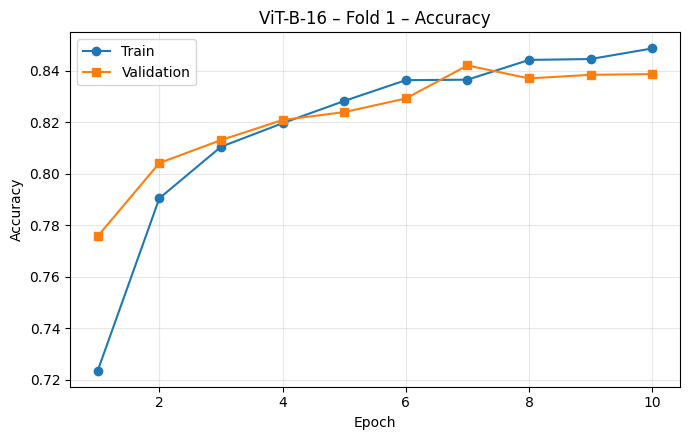

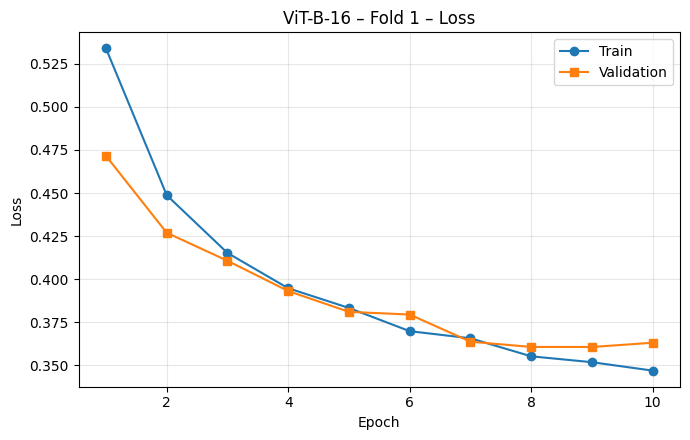

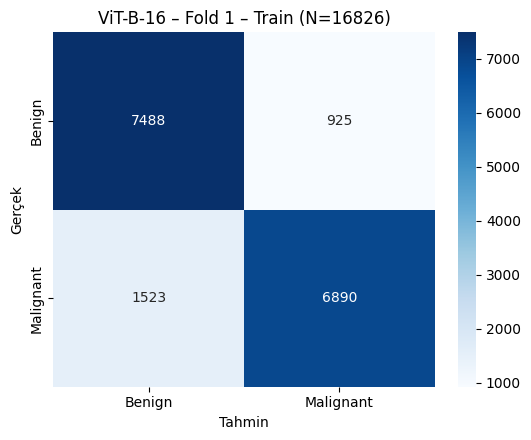

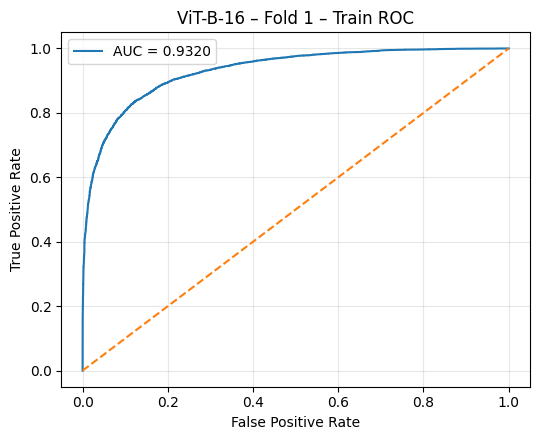

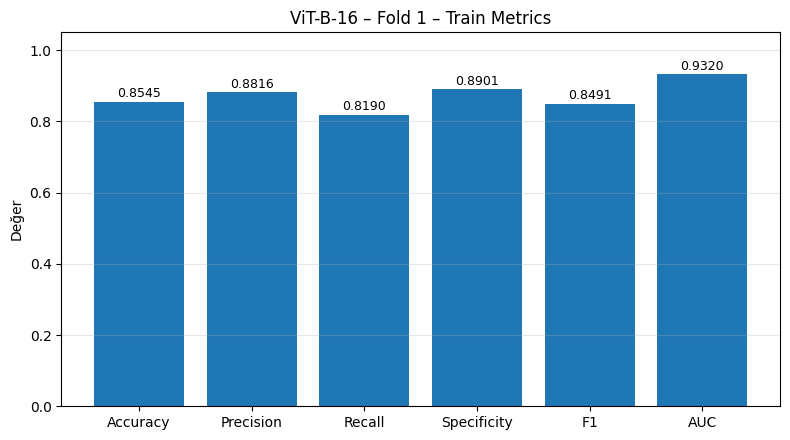

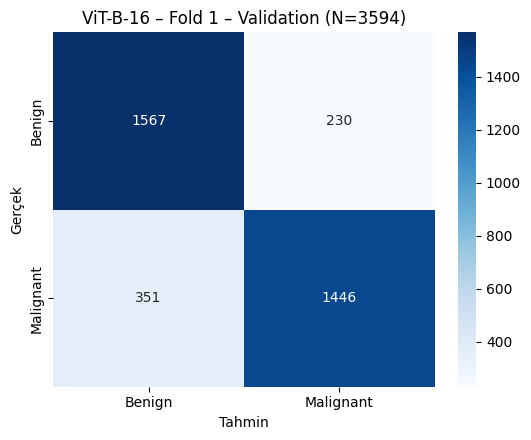

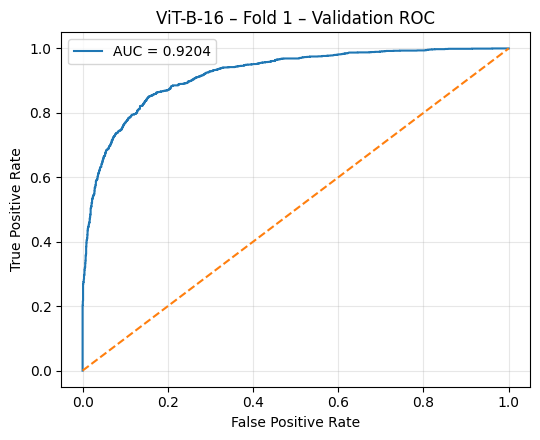

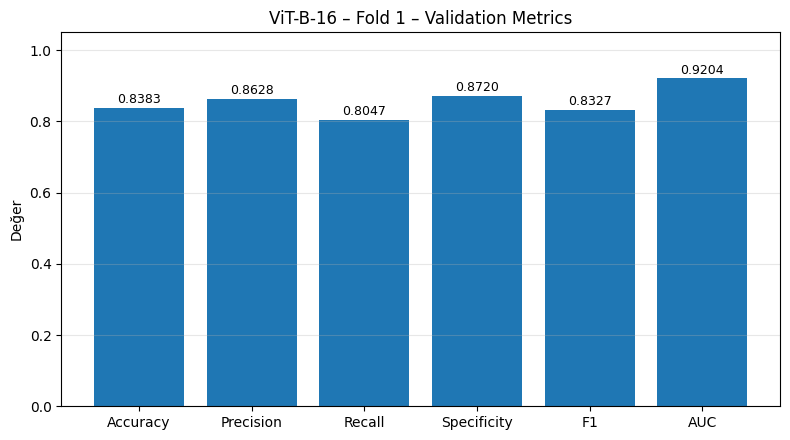

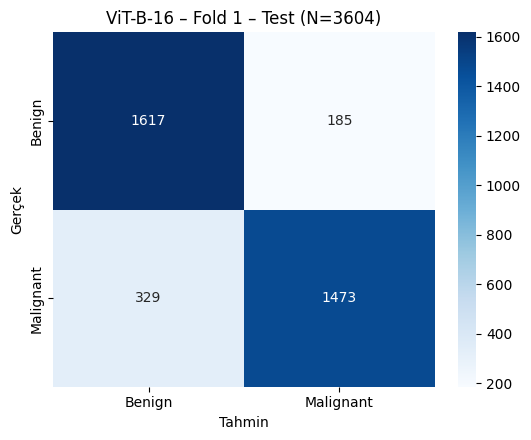

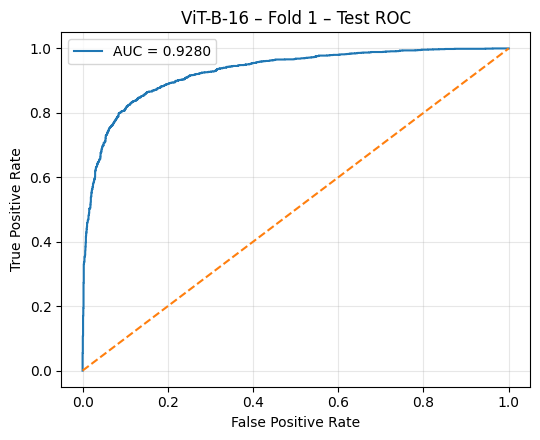

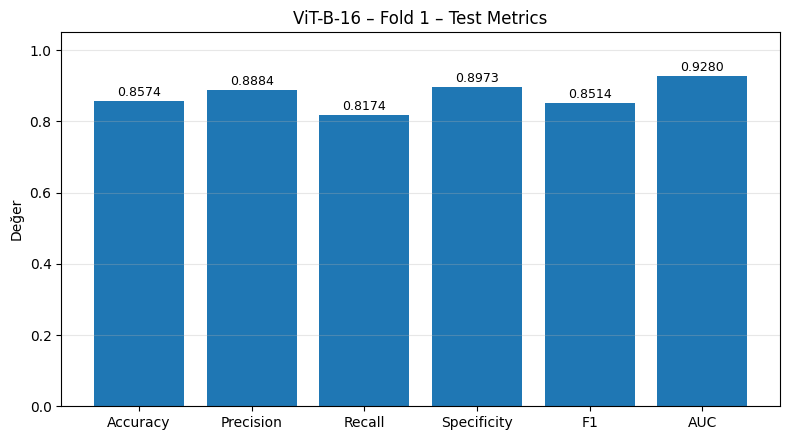

ViT-B-16 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7488.0,925.0,1523.0,6890.0,0.854511,0.881638,0.818971,0.890051,0.849150,0.931982,0.338606
Validation,3594.0,1567.0,230.0,351.0,1446.0,0.838342,0.862768,0.804674,0.872009,0.832709,0.920437,0.360616
Test,3604.0,1617.0,185.0,329.0,1473.0,0.857381,0.888420,0.817425,0.897336,0.851445,0.928041,0.347953


✓ ViT-B-16 Fold 1: best epoch 9 | Test acc 0.8574
ViT-B-16 | Fold 2 | Epoch 01/10 | Train loss 0.5349 acc 0.7257 | Val loss 0.4677 acc 0.7841
ViT-B-16 | Fold 2 | Epoch 02/10 | Train loss 0.4482 acc 0.7891 | Val loss 0.4257 acc 0.8041
ViT-B-16 | Fold 2 | Epoch 03/10 | Train loss 0.4153 acc 0.8106 | Val loss 0.4227 acc 0.7980
ViT-B-16 | Fold 2 | Epoch 04/10 | Train loss 0.3980 acc 0.8177 | Val loss 0.3864 acc 0.8314
ViT-B-16 | Fold 2 | Epoch 05/10 | Train loss 0.3828 acc 0.8304 | Val loss 0.3809 acc 0.8294
ViT-B-16 | Fold 2 | Epoch 06/10 | Train loss 0.3721 acc 0.8341 | Val loss 0.3748 acc 0.8328
ViT-B-16 | Fold 2 | Epoch 07/10 | Train loss 0.3629 acc 0.8388 | Val loss 0.3640 acc 0.8442
ViT-B-16 | Fold 2 | Epoch 08/10 | Train loss 0.3587 acc 0.8421 | Val loss 0.3529 acc 0.8486
ViT-B-16 | Fold 2 | Epoch 09/10 | Train loss 0.3521 acc 0.8464 | Val loss 0.3635 acc 0.8422
ViT-B-16 | Fold 2 | Epoch 10/10 | Train loss 0.3488 acc 0.8462 | Val loss 0.3577 acc 0.8386


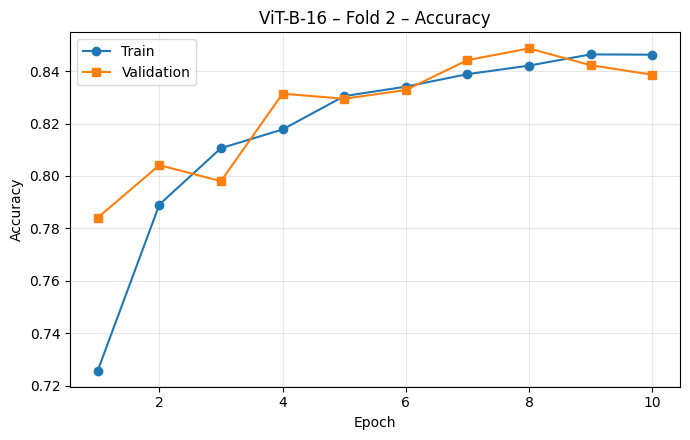

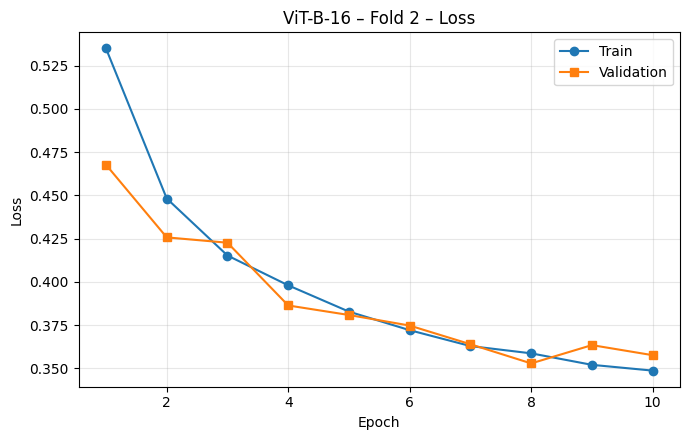

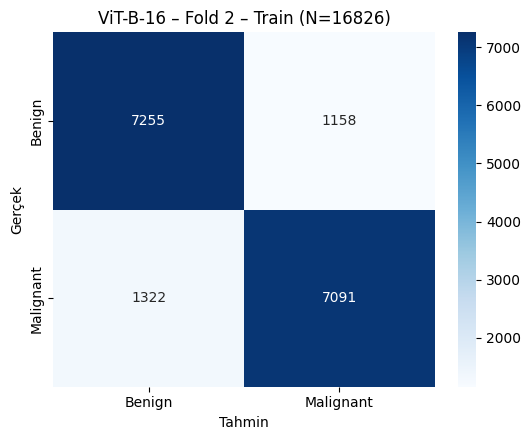

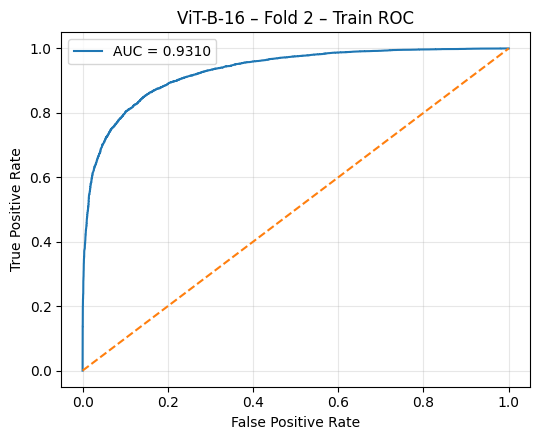

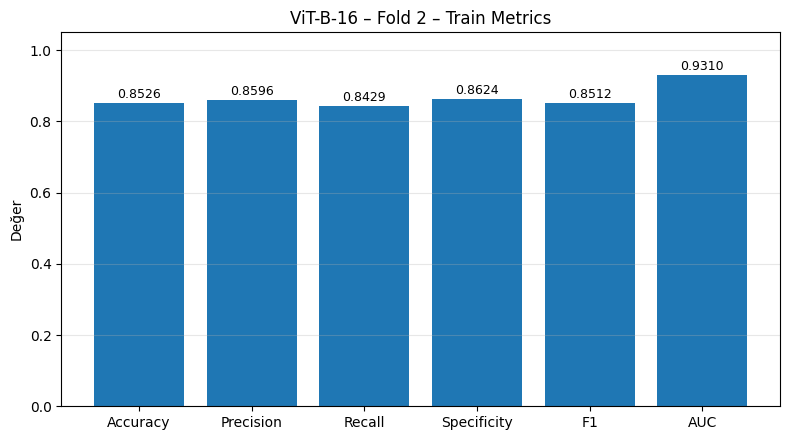

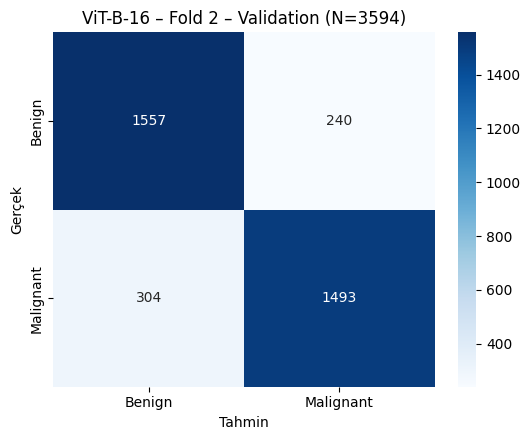

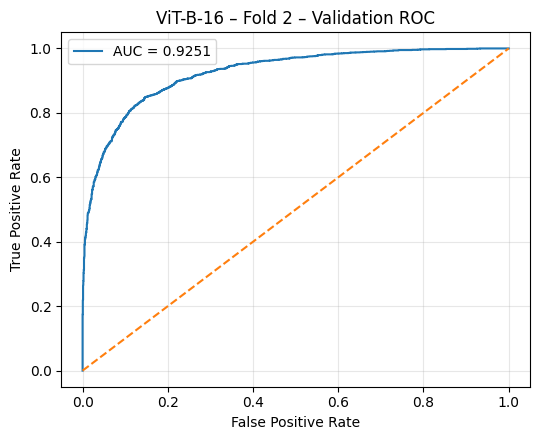

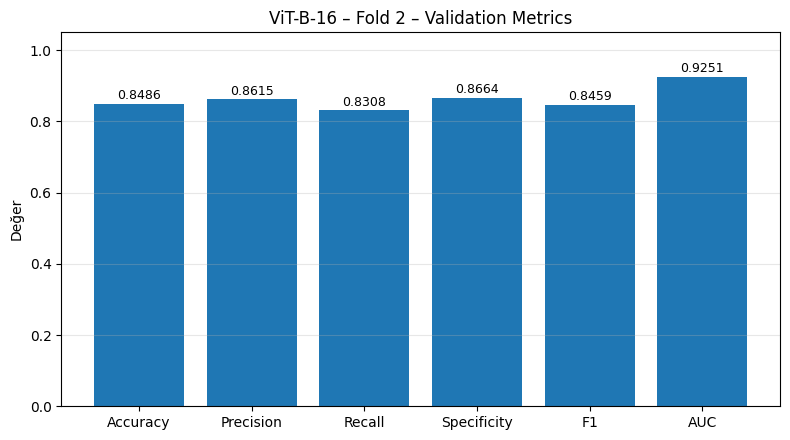

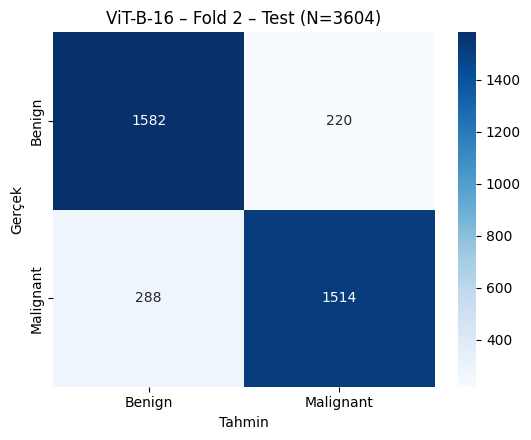

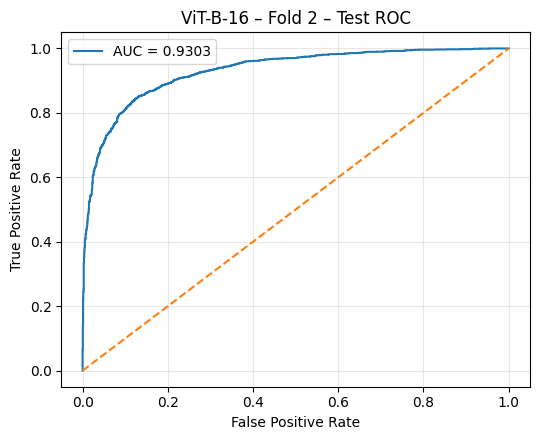

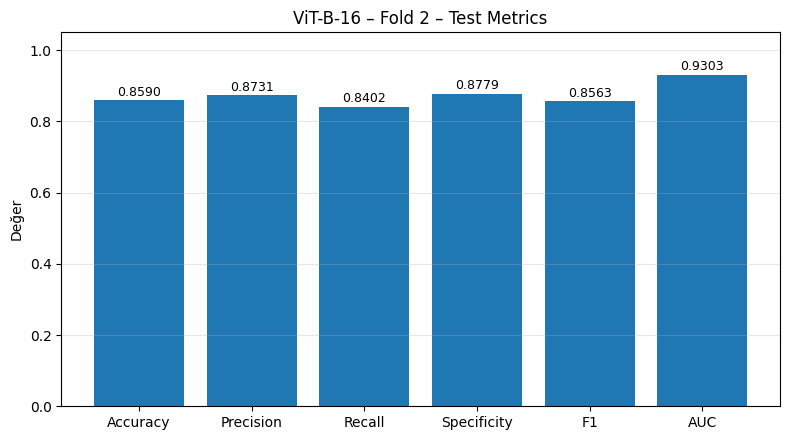

ViT-B-16 – Fold 2 sonuçları (best epoch = 8):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7255.0,1158.0,1322.0,7091.0,0.852609,0.859619,0.842862,0.862356,0.851158,0.930965,0.342194
Validation,3594.0,1557.0,240.0,304.0,1493.0,0.848637,0.861512,0.830829,0.866444,0.845892,0.925148,0.352913
Test,3604.0,1582.0,220.0,288.0,1514.0,0.859046,0.873126,0.840178,0.877913,0.856335,0.930322,0.344866


✓ ViT-B-16 Fold 2: best epoch 8 | Test acc 0.8590
ViT-B-16 | Fold 3 | Epoch 01/10 | Train loss 0.5306 acc 0.7282 | Val loss 0.4849 acc 0.7641
ViT-B-16 | Fold 3 | Epoch 02/10 | Train loss 0.4451 acc 0.7905 | Val loss 0.4467 acc 0.7910
ViT-B-16 | Fold 3 | Epoch 03/10 | Train loss 0.4119 acc 0.8115 | Val loss 0.4296 acc 0.8033
ViT-B-16 | Fold 3 | Epoch 04/10 | Train loss 0.3927 acc 0.8222 | Val loss 0.4110 acc 0.8133
ViT-B-16 | Fold 3 | Epoch 05/10 | Train loss 0.3778 acc 0.8317 | Val loss 0.3935 acc 0.8216
ViT-B-16 | Fold 3 | Epoch 06/10 | Train loss 0.3671 acc 0.8383 | Val loss 0.4043 acc 0.8125
ViT-B-16 | Fold 3 | Epoch 07/10 | Train loss 0.3594 acc 0.8389 | Val loss 0.3852 acc 0.8272
ViT-B-16 | Fold 3 | Epoch 08/10 | Train loss 0.3548 acc 0.8415 | Val loss 0.3722 acc 0.8278
ViT-B-16 | Fold 3 | Epoch 09/10 | Train loss 0.3474 acc 0.8489 | Val loss 0.3698 acc 0.8356
ViT-B-16 | Fold 3 | Epoch 10/10 | Train loss 0.3464 acc 0.8483 | Val loss 0.3827 acc 0.8242


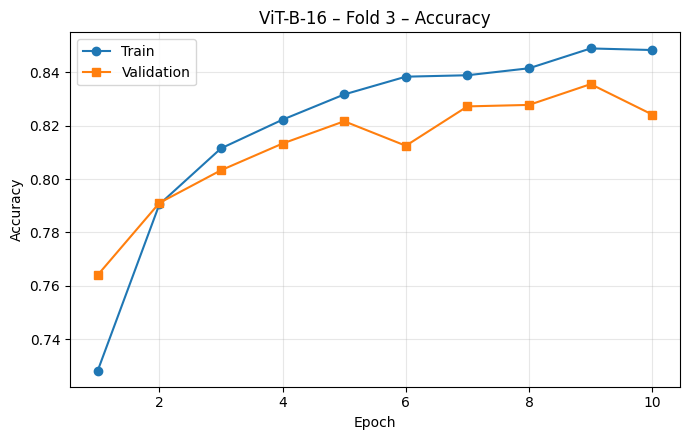

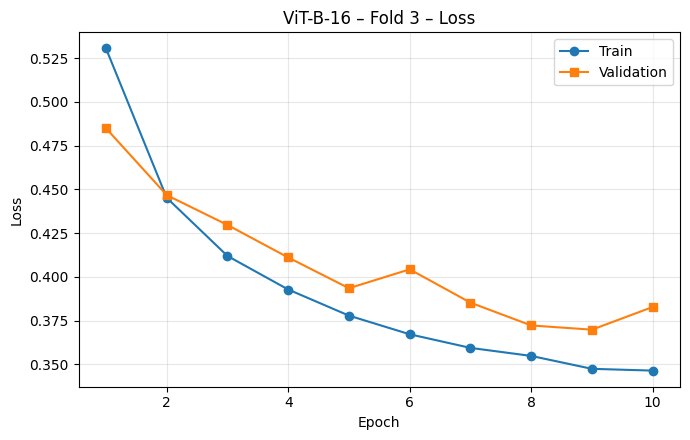

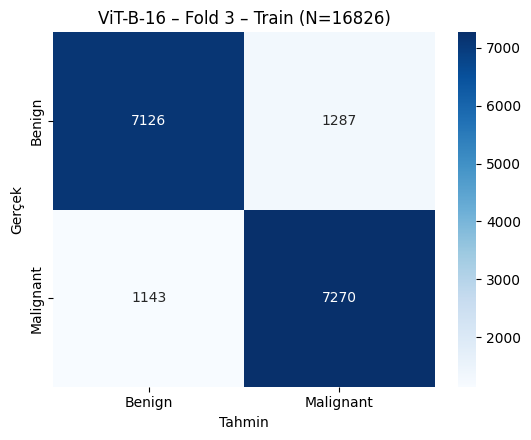

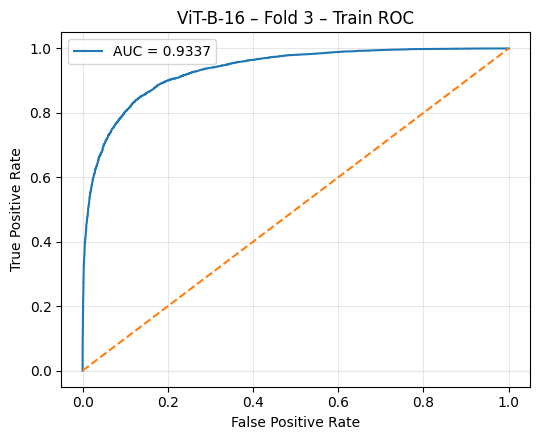

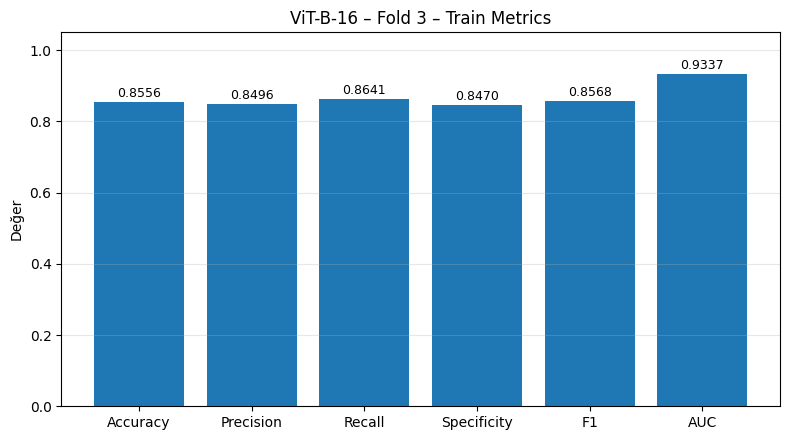

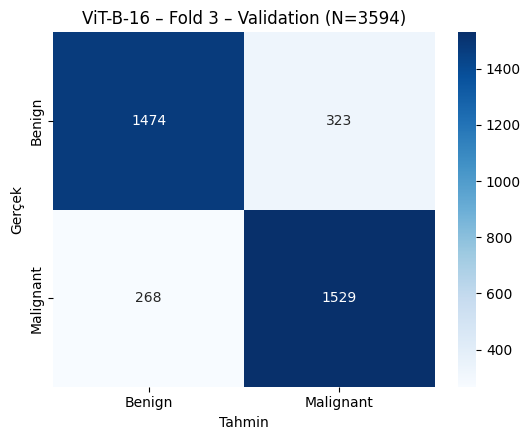

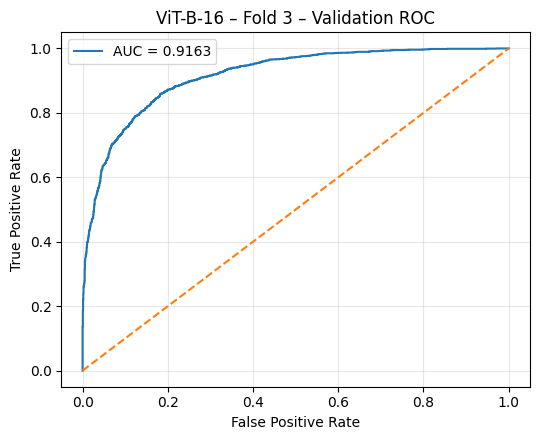

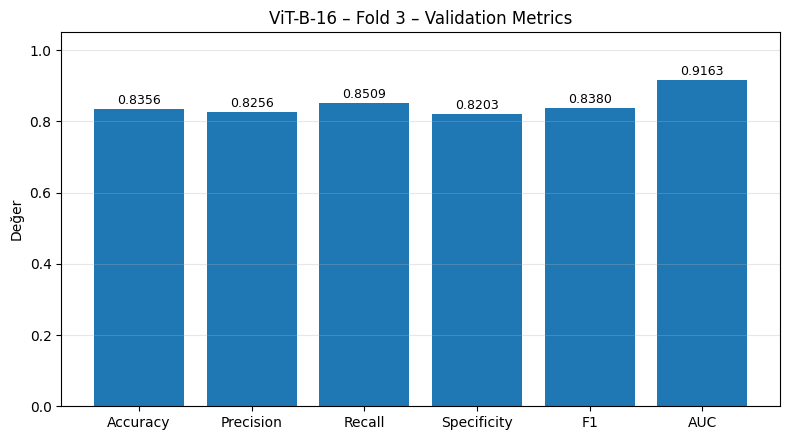

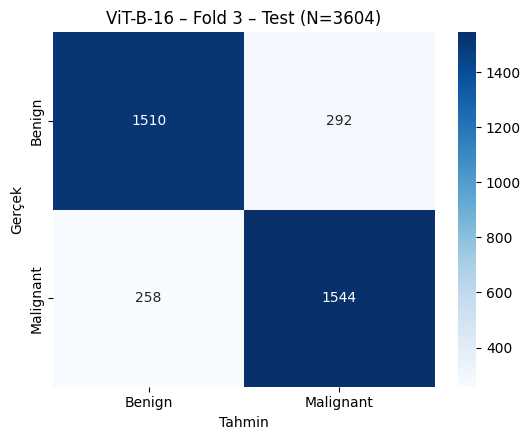

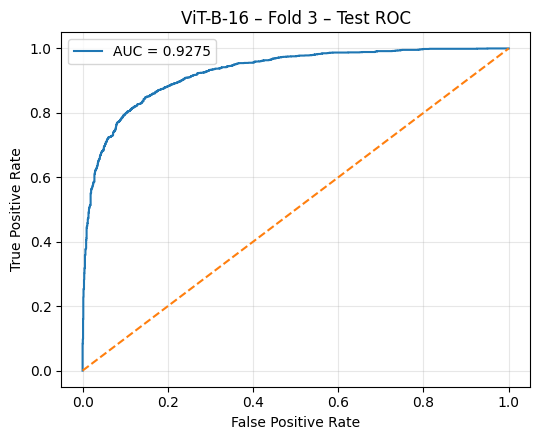

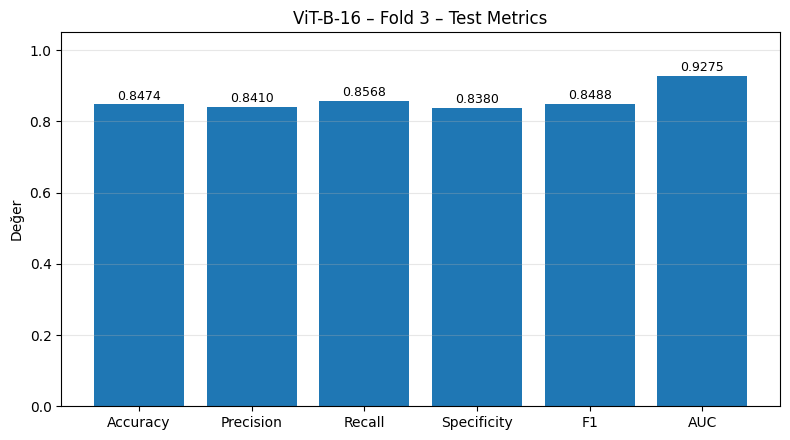

ViT-B-16 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7126.0,1287.0,1143.0,7270.0,0.855581,0.849597,0.864139,0.847022,0.856806,0.933668,0.335457
Validation,3594.0,1474.0,323.0,268.0,1529.0,0.835559,0.825594,0.850863,0.820256,0.838038,0.916306,0.369757
Test,3604.0,1510.0,292.0,258.0,1544.0,0.847392,0.840959,0.856826,0.837958,0.848818,0.927454,0.347843


✓ ViT-B-16 Fold 3: best epoch 9 | Test acc 0.8474
ViT-B-16 | Fold 4 | Epoch 01/10 | Train loss 0.5348 acc 0.7237 | Val loss 0.4819 acc 0.7643
ViT-B-16 | Fold 4 | Epoch 02/10 | Train loss 0.4447 acc 0.7909 | Val loss 0.4432 acc 0.7974
ViT-B-16 | Fold 4 | Epoch 03/10 | Train loss 0.4116 acc 0.8109 | Val loss 0.4148 acc 0.8178
ViT-B-16 | Fold 4 | Epoch 04/10 | Train loss 0.3923 acc 0.8199 | Val loss 0.4039 acc 0.8180
ViT-B-16 | Fold 4 | Epoch 05/10 | Train loss 0.3769 acc 0.8326 | Val loss 0.3932 acc 0.8247
ViT-B-16 | Fold 4 | Epoch 06/10 | Train loss 0.3666 acc 0.8373 | Val loss 0.4028 acc 0.8038
ViT-B-16 | Fold 4 | Epoch 07/10 | Train loss 0.3596 acc 0.8407 | Val loss 0.3939 acc 0.8239
ViT-B-16 | Fold 4 | Epoch 08/10 | Train loss 0.3539 acc 0.8427 | Val loss 0.3785 acc 0.8358
ViT-B-16 | Fold 4 | Epoch 09/10 | Train loss 0.3479 acc 0.8456 | Val loss 0.3833 acc 0.8239
ViT-B-16 | Fold 4 | Epoch 10/10 | Train loss 0.3425 acc 0.8485 | Val loss 0.3888 acc 0.8114


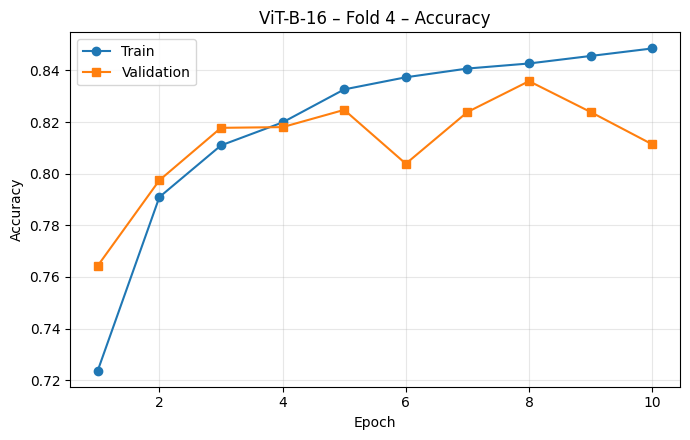

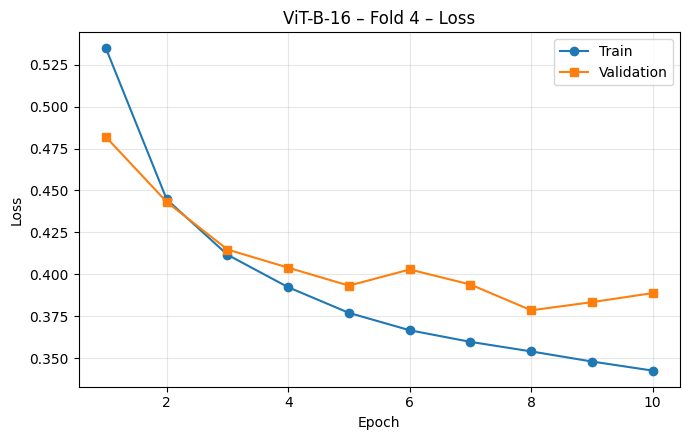

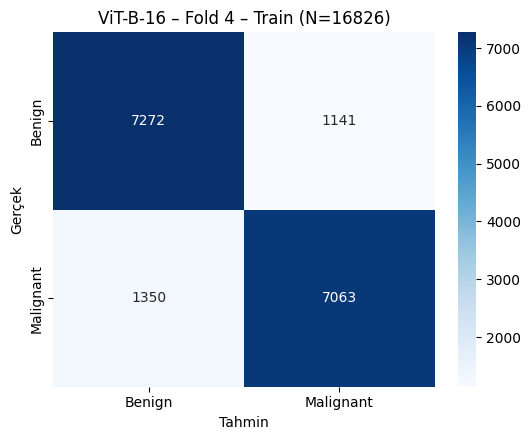

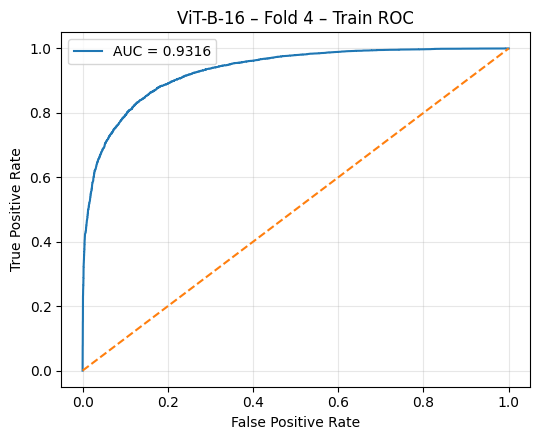

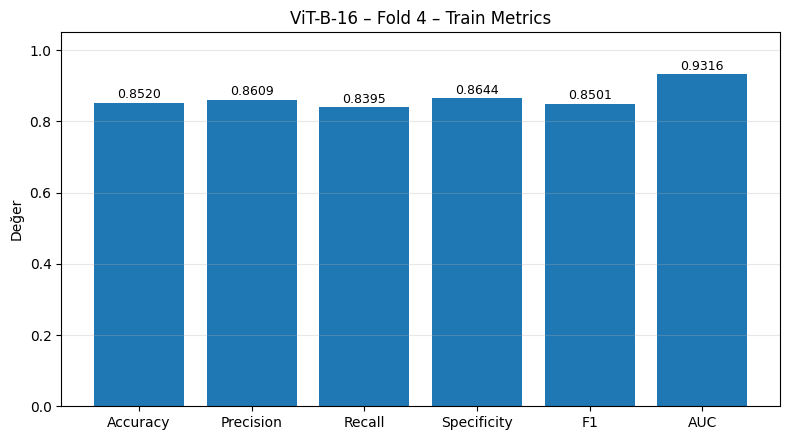

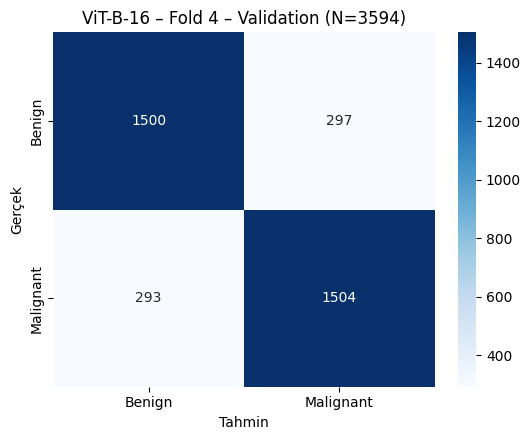

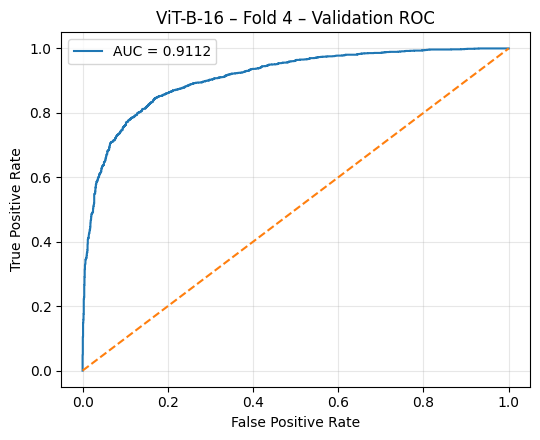

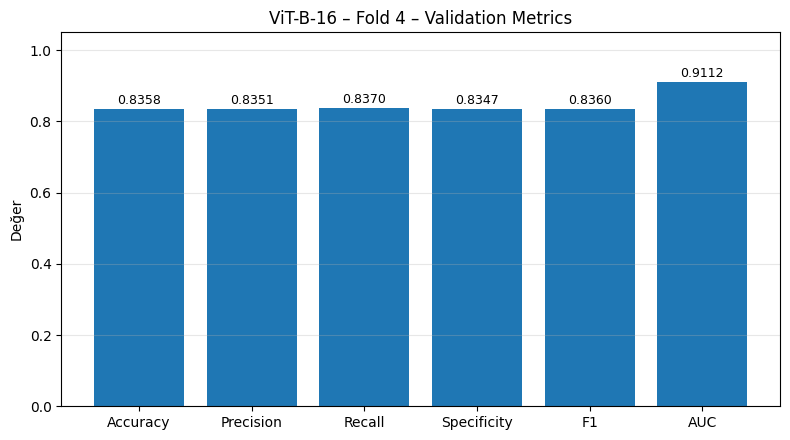

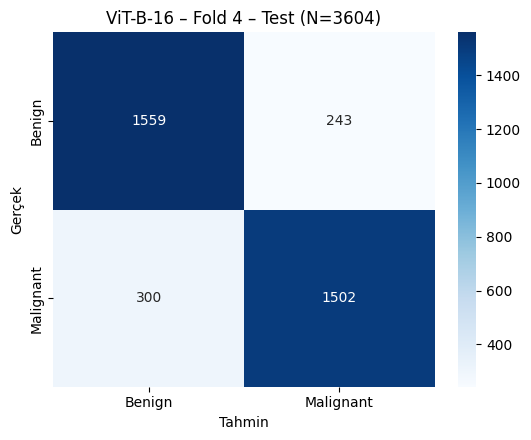

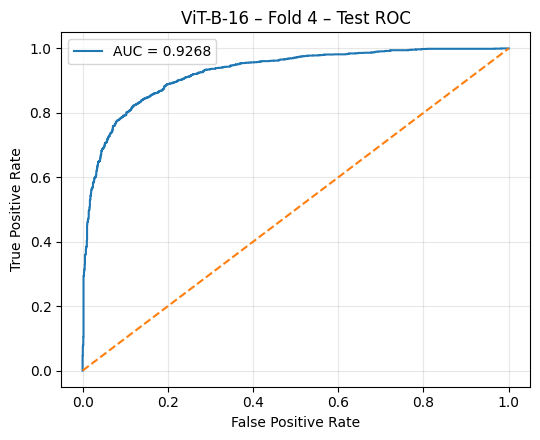

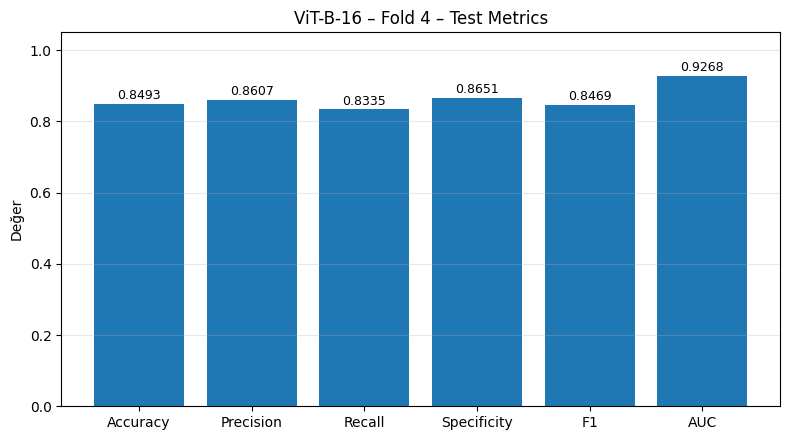

ViT-B-16 – Fold 4 sonuçları (best epoch = 8):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7272.0,1141.0,1350.0,7063.0,0.851955,0.860922,0.839534,0.864377,0.850093,0.931612,0.339353
Validation,3594.0,1500.0,297.0,293.0,1504.0,0.835838,0.835092,0.836950,0.834725,0.836020,0.911155,0.378485
Test,3604.0,1559.0,243.0,300.0,1502.0,0.849334,0.860745,0.833518,0.865150,0.846913,0.926773,0.349931


✓ ViT-B-16 Fold 4: best epoch 8 | Test acc 0.8493
ViT-B-16 | Fold 5 | Epoch 01/10 | Train loss 0.5325 acc 0.7306 | Val loss 0.4700 acc 0.7785
ViT-B-16 | Fold 5 | Epoch 02/10 | Train loss 0.4465 acc 0.7915 | Val loss 0.4284 acc 0.7983
ViT-B-16 | Fold 5 | Epoch 03/10 | Train loss 0.4123 acc 0.8130 | Val loss 0.4108 acc 0.8116
ViT-B-16 | Fold 5 | Epoch 04/10 | Train loss 0.3955 acc 0.8211 | Val loss 0.3930 acc 0.8242
ViT-B-16 | Fold 5 | Epoch 05/10 | Train loss 0.3809 acc 0.8306 | Val loss 0.3809 acc 0.8255
ViT-B-16 | Fold 5 | Epoch 06/10 | Train loss 0.3701 acc 0.8360 | Val loss 0.3813 acc 0.8242
ViT-B-16 | Fold 5 | Epoch 07/10 | Train loss 0.3641 acc 0.8375 | Val loss 0.3653 acc 0.8381
ViT-B-16 | Fold 5 | Epoch 08/10 | Train loss 0.3570 acc 0.8442 | Val loss 0.3689 acc 0.8319
ViT-B-16 | Fold 5 | Epoch 09/10 | Train loss 0.3517 acc 0.8446 | Val loss 0.3599 acc 0.8350
ViT-B-16 | Fold 5 | Epoch 10/10 | Train loss 0.3478 acc 0.8460 | Val loss 0.3550 acc 0.8411


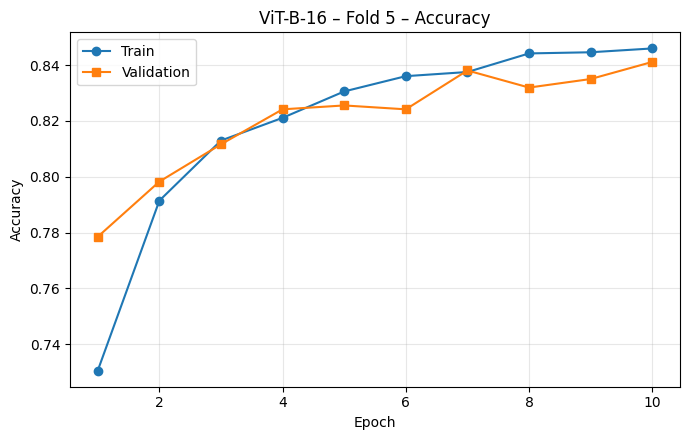

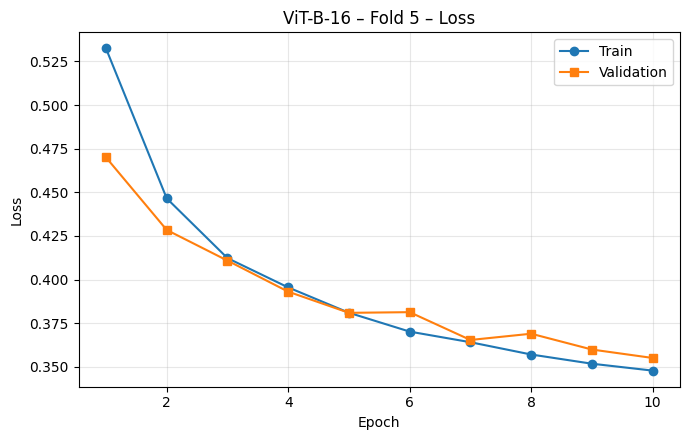

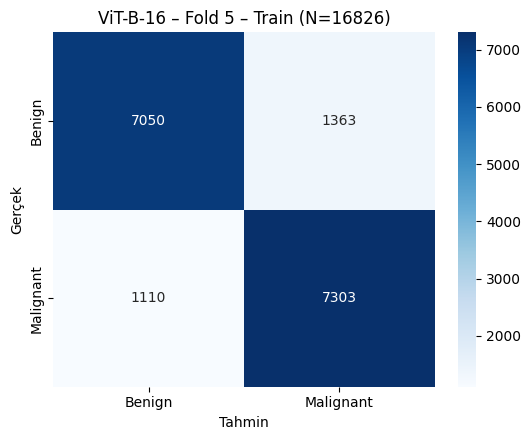

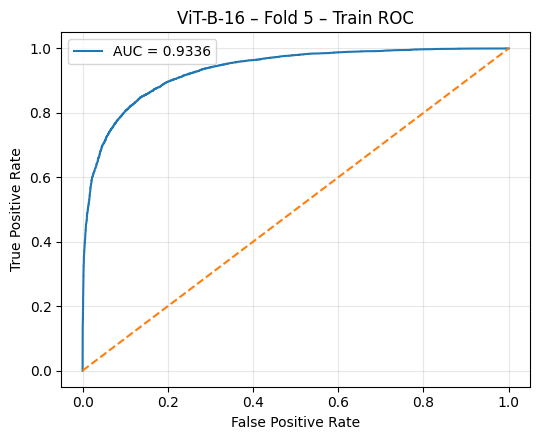

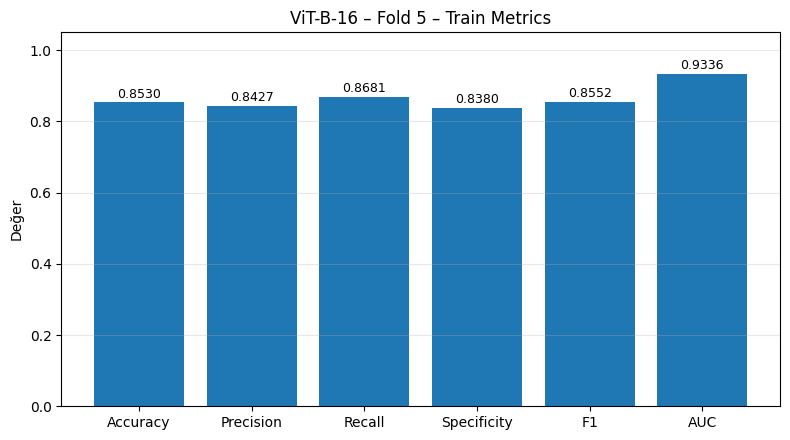

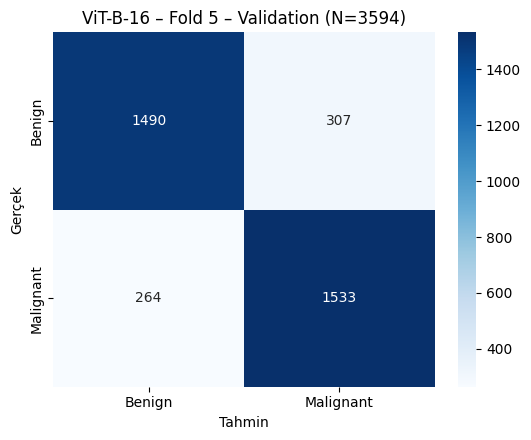

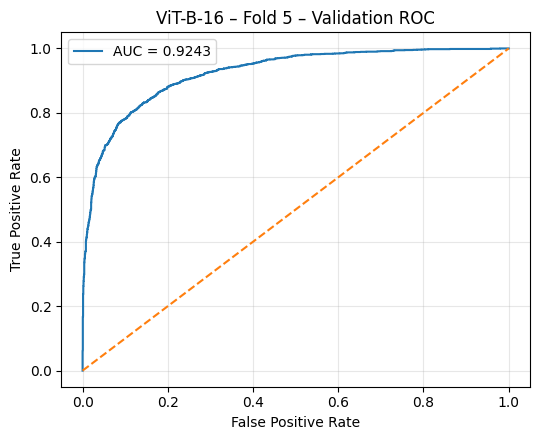

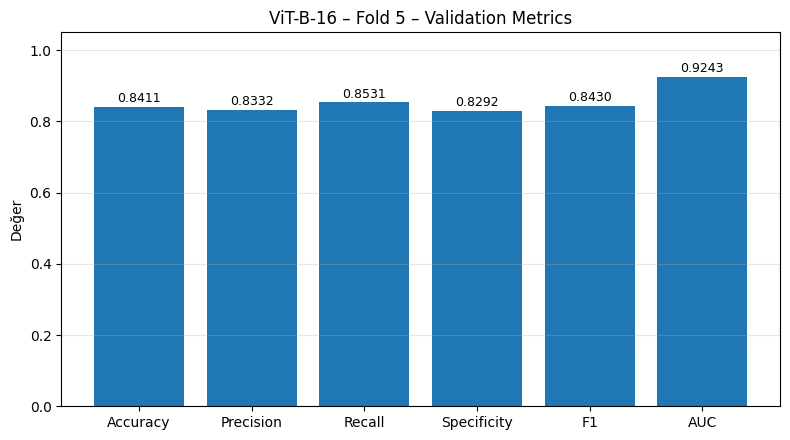

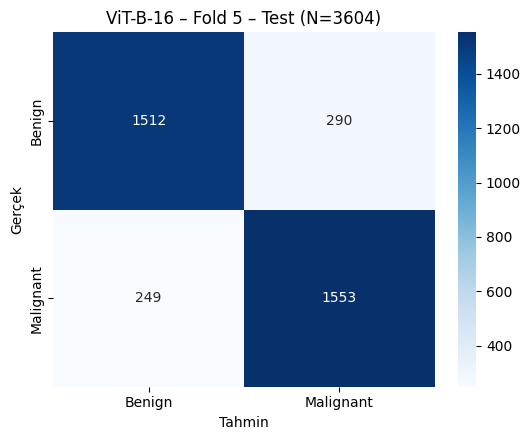

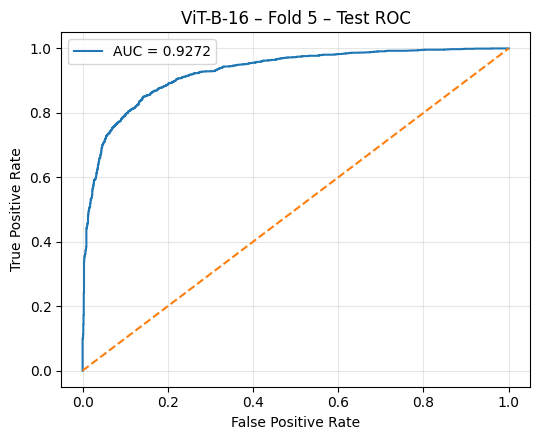

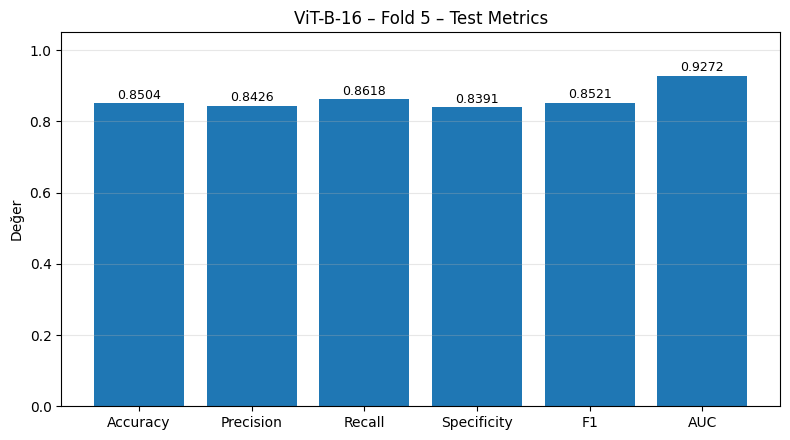

ViT-B-16 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7050.0,1363.0,1110.0,7303.0,0.853025,0.842719,0.868061,0.837989,0.855202,0.933562,0.336917
Validation,3594.0,1490.0,307.0,264.0,1533.0,0.841124,0.833152,0.853088,0.829160,0.843002,0.924320,0.355028
Test,3604.0,1512.0,290.0,249.0,1553.0,0.850444,0.842648,0.861820,0.839068,0.852126,0.927217,0.350567


✓ ViT-B-16 Fold 5: best epoch 10 | Test acc 0.8504
Downloading: "https://download.pytorch.org/models/vit_b_32-d86f8d99.pth" to /root/.cache/torch/hub/checkpoints/vit_b_32-d86f8d99.pth


100%|██████████| 337M/337M [00:01<00:00, 230MB/s]


ViT-B-32 | Fold 1 | Epoch 01/10 | Train loss 0.4994 acc 0.7533 | Val loss 0.4363 acc 0.8108
ViT-B-32 | Fold 1 | Epoch 02/10 | Train loss 0.4052 acc 0.8176 | Val loss 0.3959 acc 0.8333
ViT-B-32 | Fold 1 | Epoch 03/10 | Train loss 0.3741 acc 0.8329 | Val loss 0.3770 acc 0.8445
ViT-B-32 | Fold 1 | Epoch 04/10 | Train loss 0.3546 acc 0.8449 | Val loss 0.3663 acc 0.8534
ViT-B-32 | Fold 1 | Epoch 05/10 | Train loss 0.3388 acc 0.8533 | Val loss 0.3542 acc 0.8589
ViT-B-32 | Fold 1 | Epoch 06/10 | Train loss 0.3268 acc 0.8591 | Val loss 0.3414 acc 0.8587
ViT-B-32 | Fold 1 | Epoch 07/10 | Train loss 0.3206 acc 0.8653 | Val loss 0.3317 acc 0.8728
ViT-B-32 | Fold 1 | Epoch 08/10 | Train loss 0.3119 acc 0.8709 | Val loss 0.3286 acc 0.8695
ViT-B-32 | Fold 1 | Epoch 09/10 | Train loss 0.3061 acc 0.8723 | Val loss 0.3326 acc 0.8689
ViT-B-32 | Fold 1 | Epoch 10/10 | Train loss 0.3031 acc 0.8746 | Val loss 0.3251 acc 0.8687


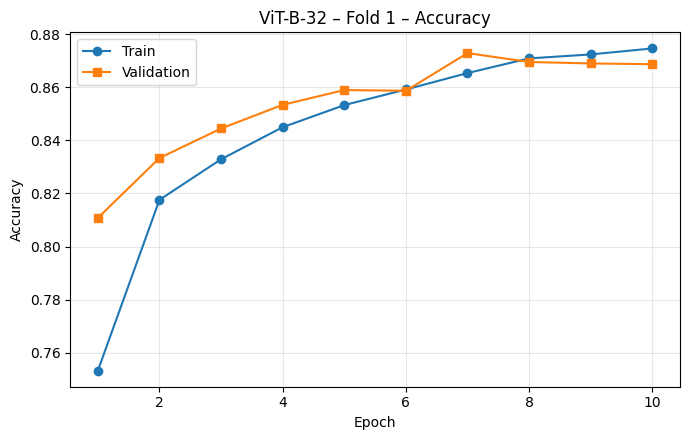

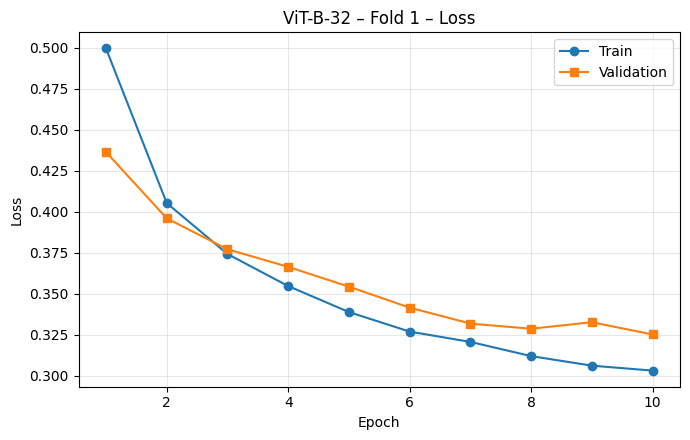

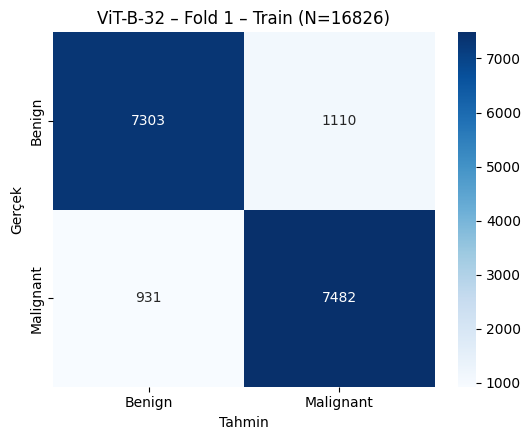

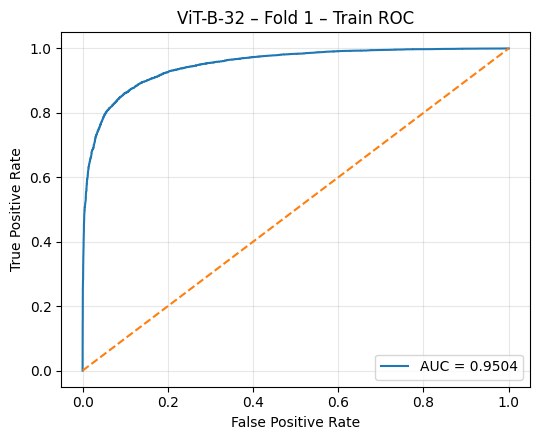

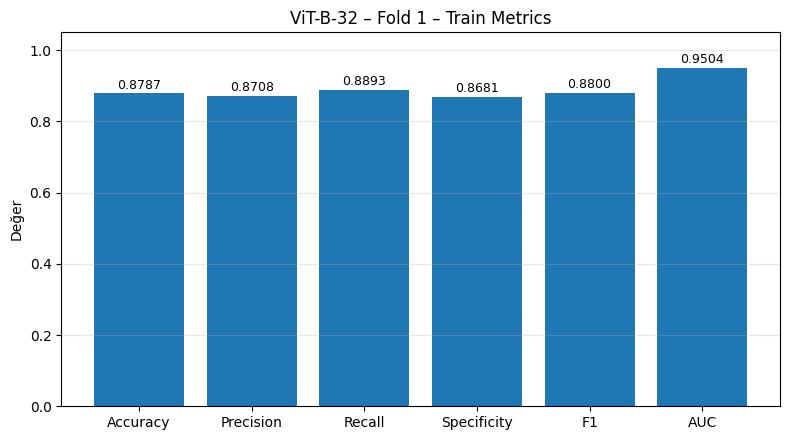

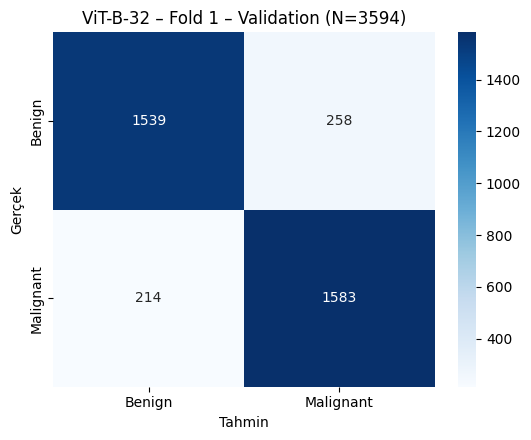

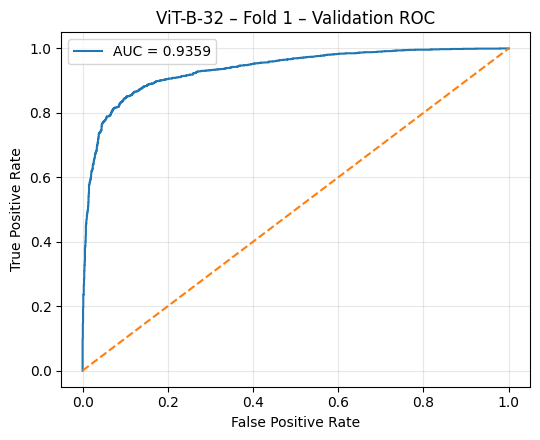

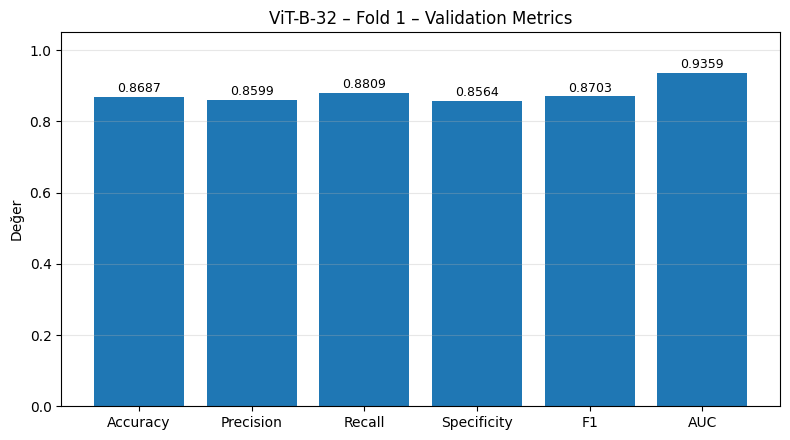

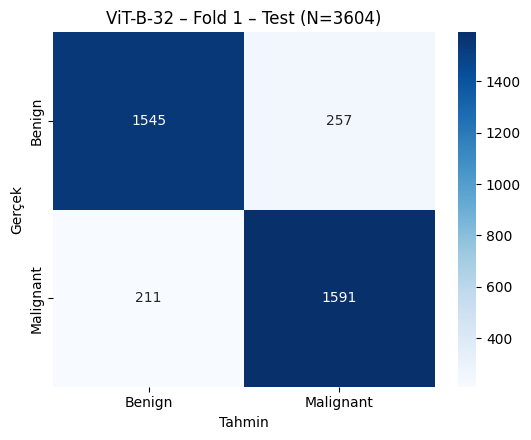

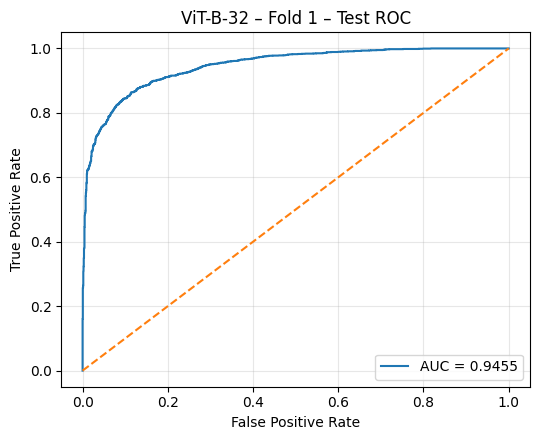

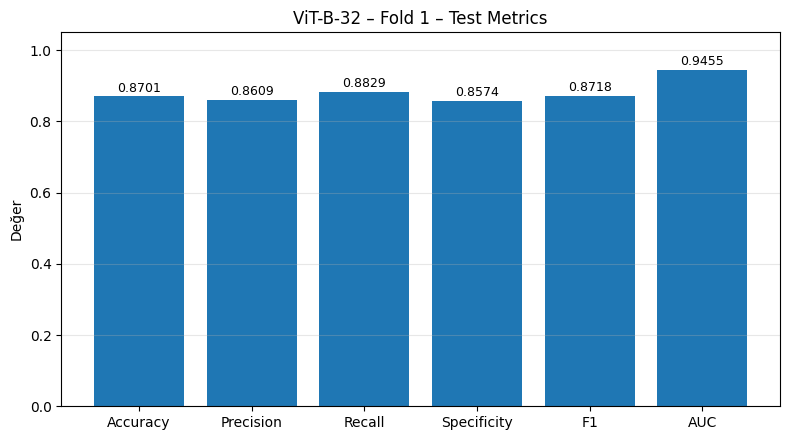

ViT-B-32 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7303.0,1110.0,931.0,7482.0,0.878700,0.870810,0.889338,0.868061,0.879976,0.950402,0.292386
Validation,3594.0,1539.0,258.0,214.0,1583.0,0.868670,0.859859,0.880913,0.856427,0.870258,0.935915,0.325095
Test,3604.0,1545.0,257.0,211.0,1591.0,0.870144,0.860931,0.882908,0.857381,0.871781,0.945486,0.302462


✓ ViT-B-32 Fold 1: best epoch 10 | Test acc 0.8701
ViT-B-32 | Fold 2 | Epoch 01/10 | Train loss 0.4985 acc 0.7524 | Val loss 0.4388 acc 0.7986
ViT-B-32 | Fold 2 | Epoch 02/10 | Train loss 0.4072 acc 0.8203 | Val loss 0.3911 acc 0.8317
ViT-B-32 | Fold 2 | Epoch 03/10 | Train loss 0.3706 acc 0.8372 | Val loss 0.3900 acc 0.8261
ViT-B-32 | Fold 2 | Epoch 04/10 | Train loss 0.3553 acc 0.8455 | Val loss 0.3558 acc 0.8517
ViT-B-32 | Fold 2 | Epoch 05/10 | Train loss 0.3394 acc 0.8534 | Val loss 0.3492 acc 0.8506
ViT-B-32 | Fold 2 | Epoch 06/10 | Train loss 0.3272 acc 0.8643 | Val loss 0.3428 acc 0.8523
ViT-B-32 | Fold 2 | Epoch 07/10 | Train loss 0.3204 acc 0.8653 | Val loss 0.3321 acc 0.8639
ViT-B-32 | Fold 2 | Epoch 08/10 | Train loss 0.3129 acc 0.8684 | Val loss 0.3291 acc 0.8623
ViT-B-32 | Fold 2 | Epoch 09/10 | Train loss 0.3073 acc 0.8721 | Val loss 0.3187 acc 0.8692
ViT-B-32 | Fold 2 | Epoch 10/10 | Train loss 0.3029 acc 0.8742 | Val loss 0.3233 acc 0.8667


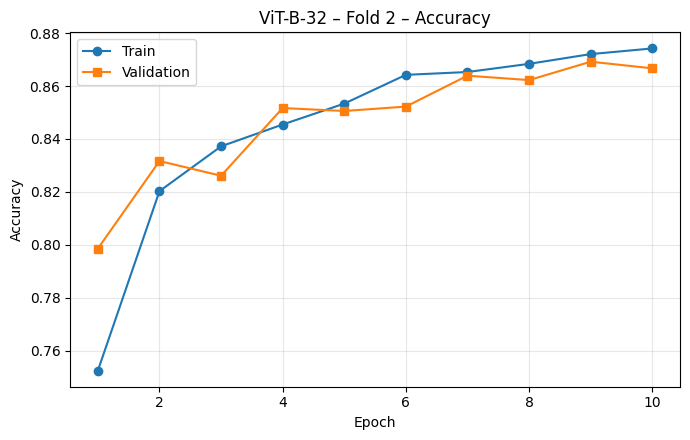

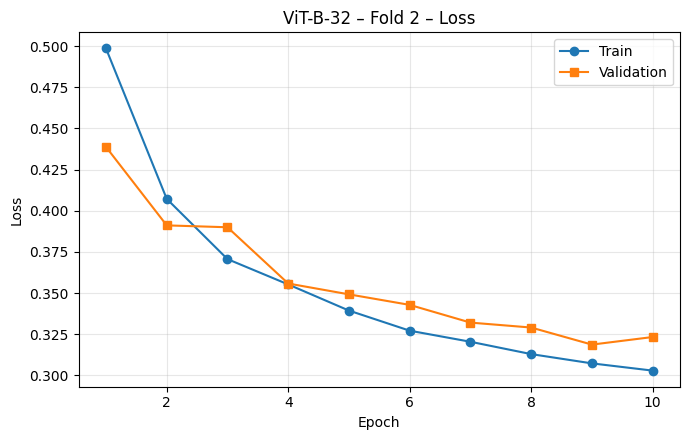

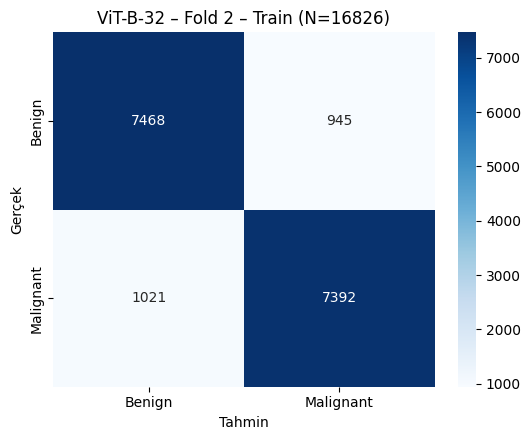

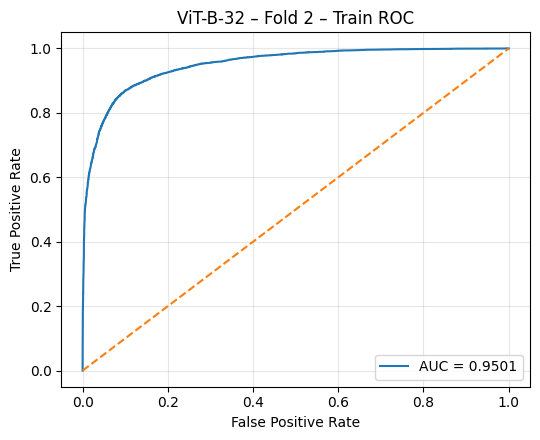

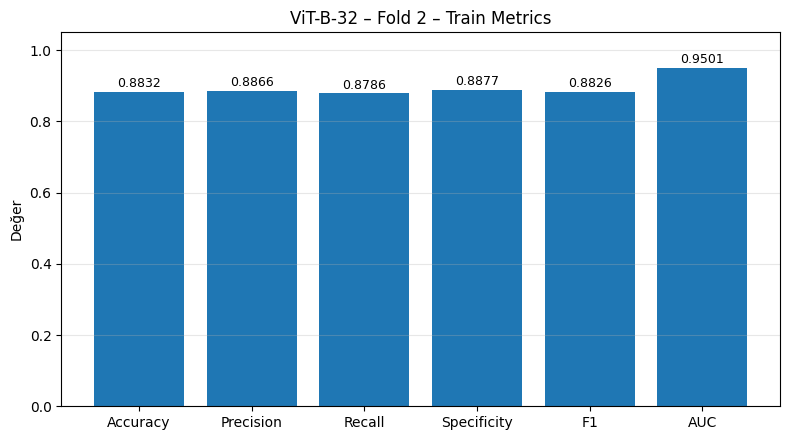

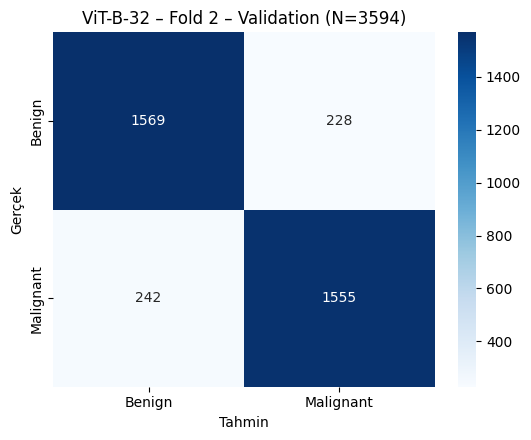

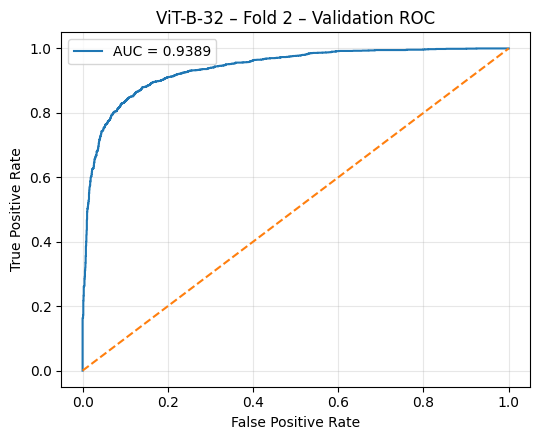

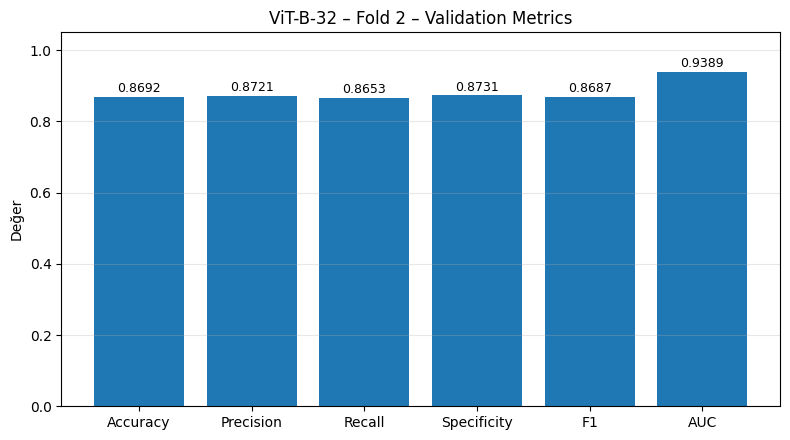

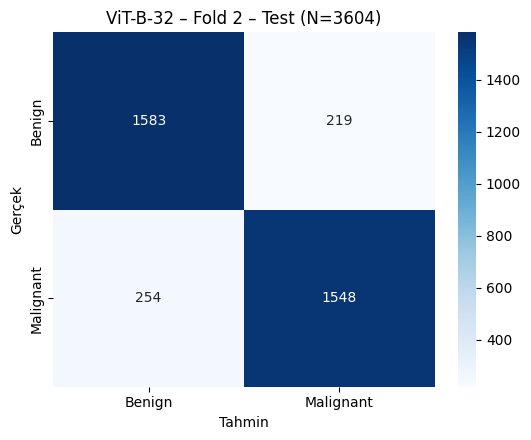

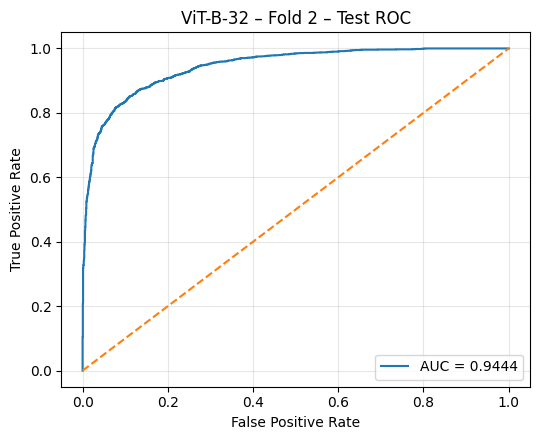

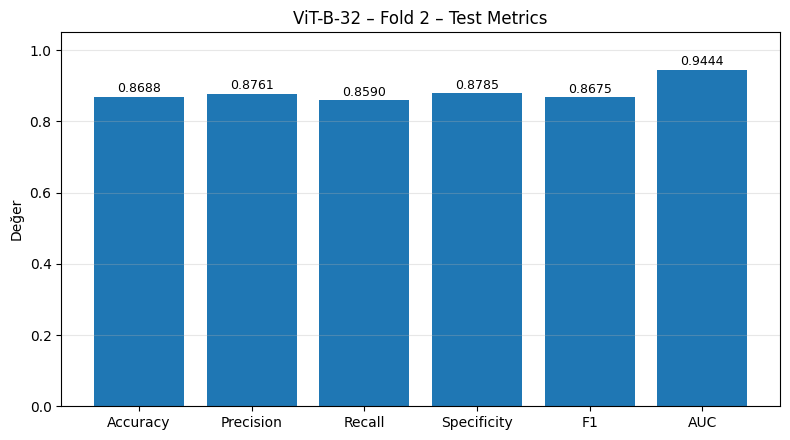

ViT-B-32 – Fold 2 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7468.0,945.0,1021.0,7392.0,0.883157,0.886650,0.878640,0.887674,0.882627,0.950147,0.293326
Validation,3594.0,1569.0,228.0,242.0,1555.0,0.869226,0.872126,0.865331,0.873122,0.868715,0.938899,0.318714
Test,3604.0,1583.0,219.0,254.0,1548.0,0.868757,0.876061,0.859046,0.878468,0.867470,0.944371,0.305447


✓ ViT-B-32 Fold 2: best epoch 9 | Test acc 0.8688
ViT-B-32 | Fold 3 | Epoch 01/10 | Train loss 0.4986 acc 0.7554 | Val loss 0.4399 acc 0.7899
ViT-B-32 | Fold 3 | Epoch 02/10 | Train loss 0.4063 acc 0.8154 | Val loss 0.3896 acc 0.8255
ViT-B-32 | Fold 3 | Epoch 03/10 | Train loss 0.3736 acc 0.8358 | Val loss 0.3724 acc 0.8333
ViT-B-32 | Fold 3 | Epoch 04/10 | Train loss 0.3561 acc 0.8443 | Val loss 0.3538 acc 0.8467
ViT-B-32 | Fold 3 | Epoch 05/10 | Train loss 0.3417 acc 0.8558 | Val loss 0.3511 acc 0.8378
ViT-B-32 | Fold 3 | Epoch 06/10 | Train loss 0.3307 acc 0.8626 | Val loss 0.3510 acc 0.8397
ViT-B-32 | Fold 3 | Epoch 07/10 | Train loss 0.3212 acc 0.8605 | Val loss 0.3338 acc 0.8556
ViT-B-32 | Fold 3 | Epoch 08/10 | Train loss 0.3154 acc 0.8686 | Val loss 0.3244 acc 0.8584
ViT-B-32 | Fold 3 | Epoch 09/10 | Train loss 0.3093 acc 0.8689 | Val loss 0.3116 acc 0.8698
ViT-B-32 | Fold 3 | Epoch 10/10 | Train loss 0.3052 acc 0.8716 | Val loss 0.3210 acc 0.8553


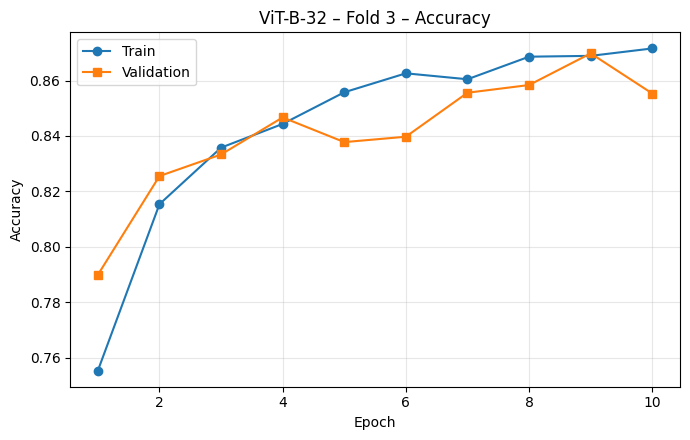

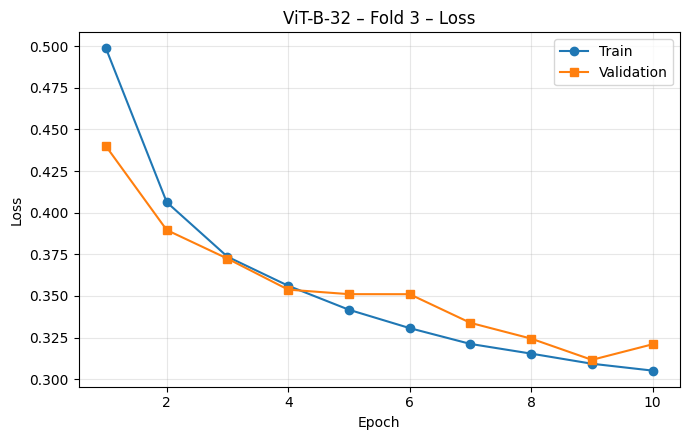

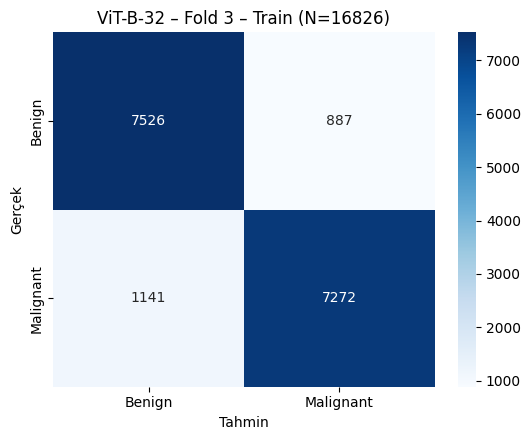

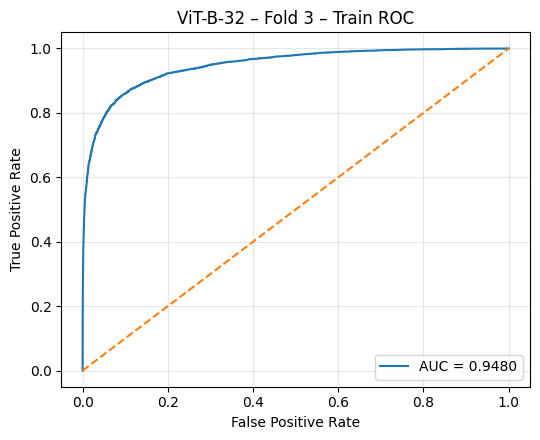

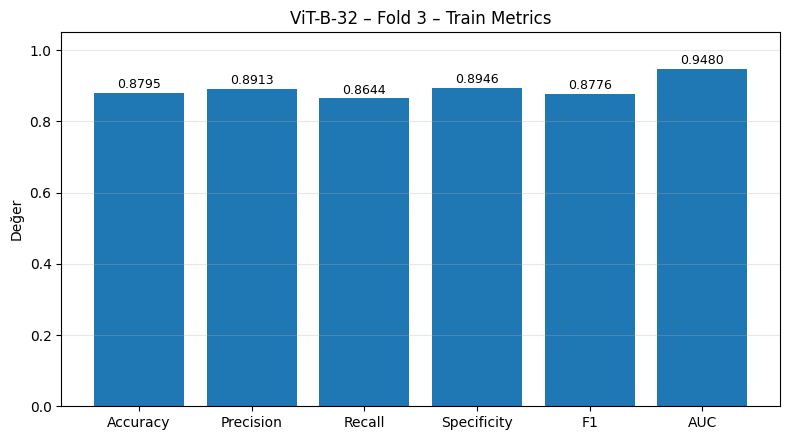

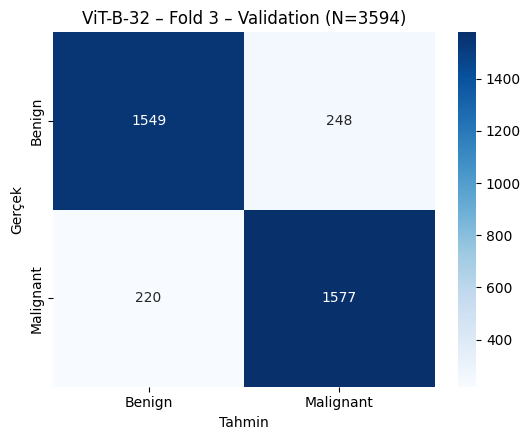

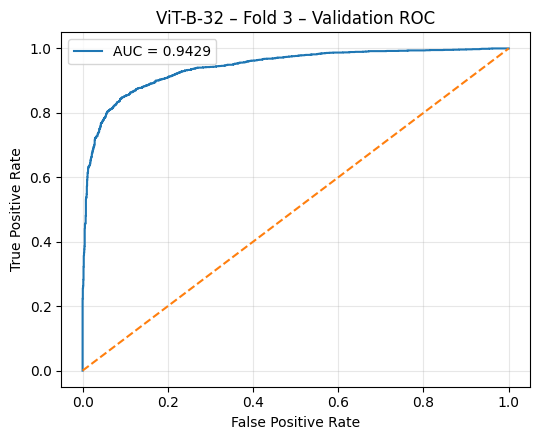

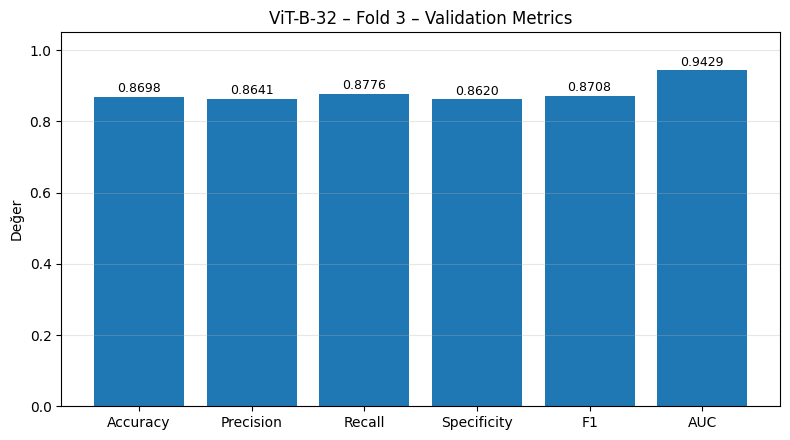

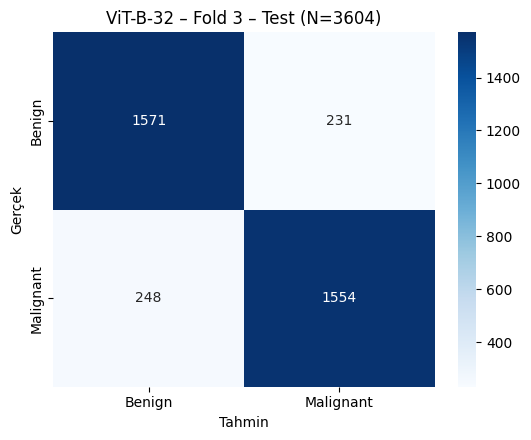

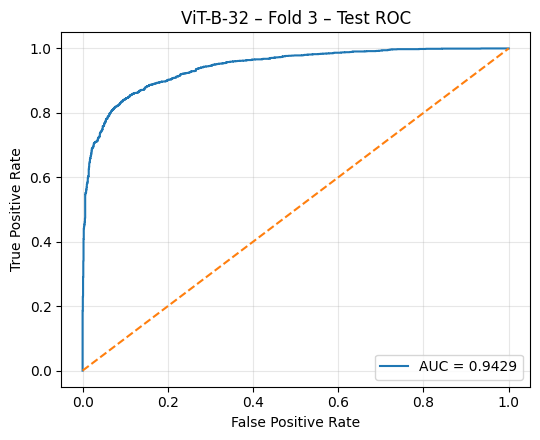

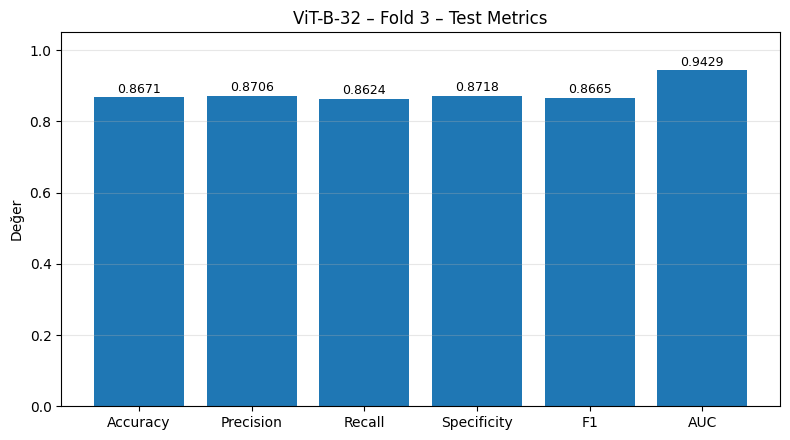

ViT-B-32 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7526.0,887.0,1141.0,7272.0,0.879472,0.891286,0.864377,0.894568,0.877625,0.948016,0.297637
Validation,3594.0,1549.0,248.0,220.0,1577.0,0.869783,0.864110,0.877574,0.861992,0.870790,0.942931,0.311626
Test,3604.0,1571.0,231.0,248.0,1554.0,0.867092,0.870588,0.862375,0.871809,0.866462,0.942920,0.308109


✓ ViT-B-32 Fold 3: best epoch 9 | Test acc 0.8671
ViT-B-32 | Fold 4 | Epoch 01/10 | Train loss 0.4991 acc 0.7542 | Val loss 0.4441 acc 0.7891
ViT-B-32 | Fold 4 | Epoch 02/10 | Train loss 0.4057 acc 0.8148 | Val loss 0.4009 acc 0.8236
ViT-B-32 | Fold 4 | Epoch 03/10 | Train loss 0.3703 acc 0.8383 | Val loss 0.3788 acc 0.8333
ViT-B-32 | Fold 4 | Epoch 04/10 | Train loss 0.3528 acc 0.8468 | Val loss 0.3698 acc 0.8331
ViT-B-32 | Fold 4 | Epoch 05/10 | Train loss 0.3383 acc 0.8581 | Val loss 0.3542 acc 0.8492
ViT-B-32 | Fold 4 | Epoch 06/10 | Train loss 0.3278 acc 0.8618 | Val loss 0.3485 acc 0.8509
ViT-B-32 | Fold 4 | Epoch 07/10 | Train loss 0.3172 acc 0.8664 | Val loss 0.3503 acc 0.8447
ViT-B-32 | Fold 4 | Epoch 08/10 | Train loss 0.3123 acc 0.8679 | Val loss 0.3369 acc 0.8587
ViT-B-32 | Fold 4 | Epoch 09/10 | Train loss 0.3070 acc 0.8710 | Val loss 0.3347 acc 0.8550
ViT-B-32 | Fold 4 | Epoch 10/10 | Train loss 0.3007 acc 0.8739 | Val loss 0.3324 acc 0.8523


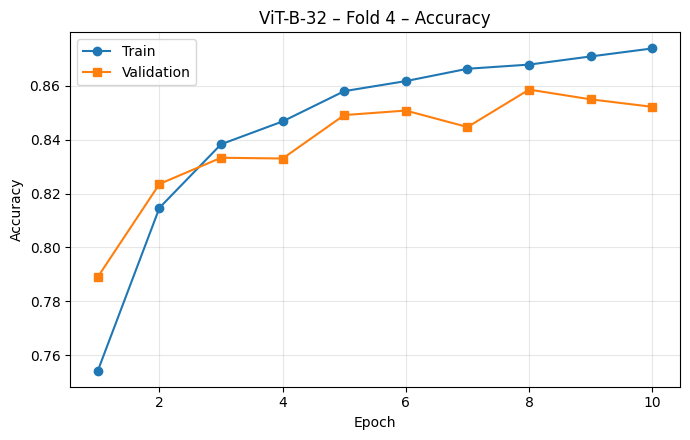

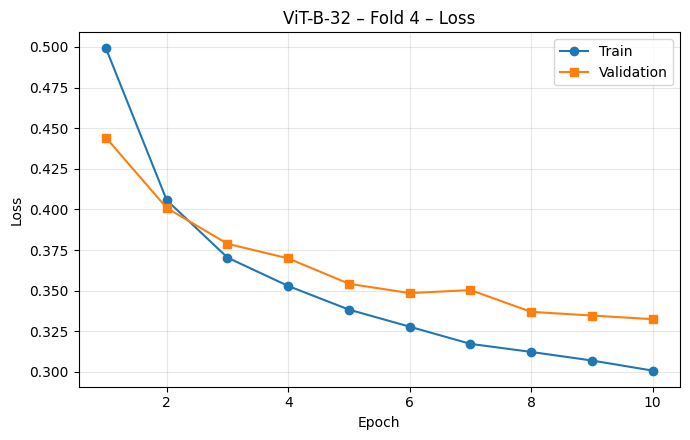

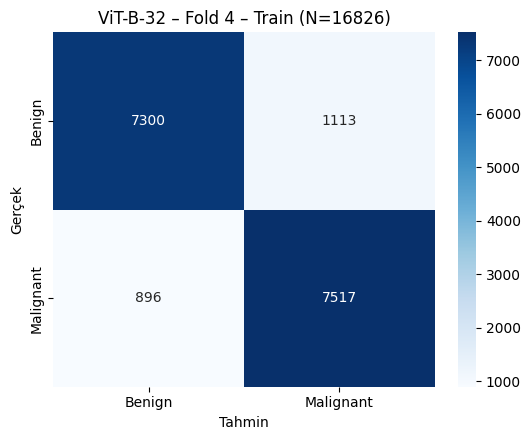

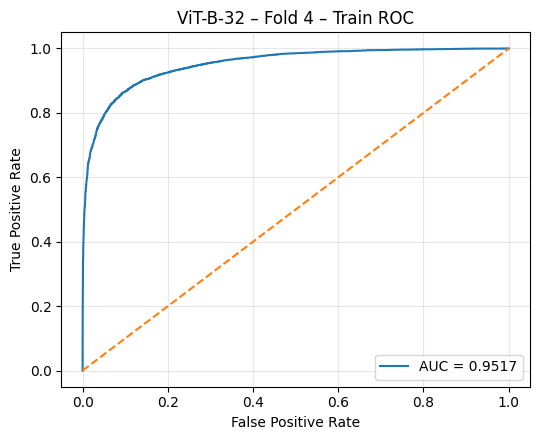

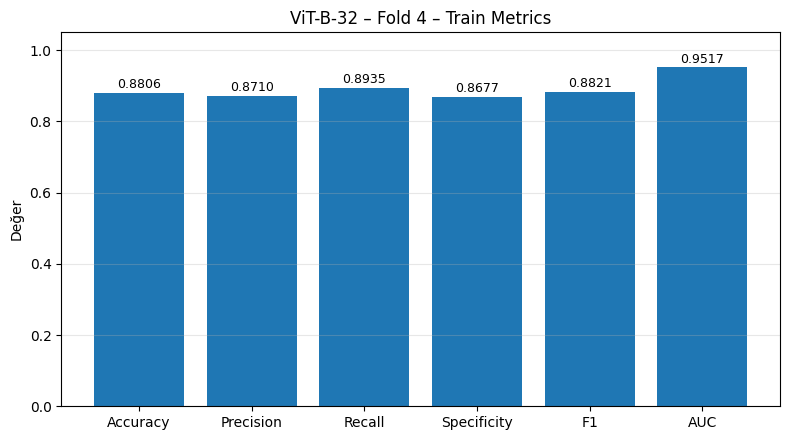

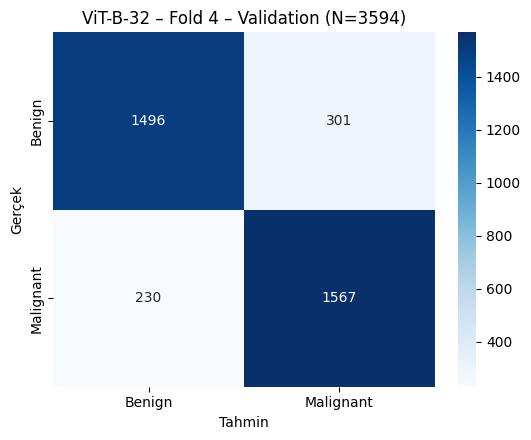

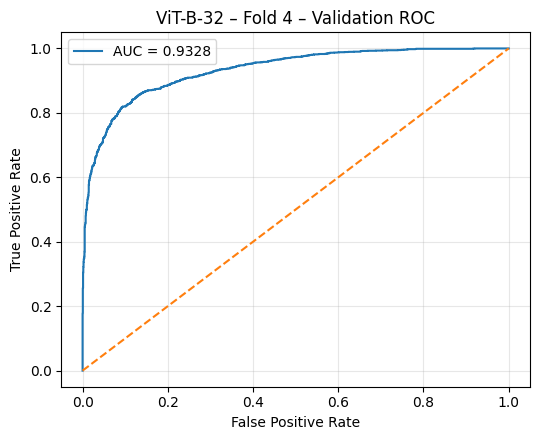

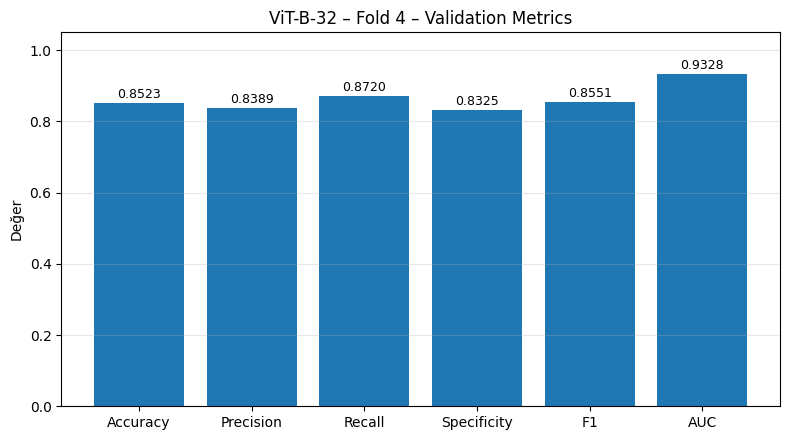

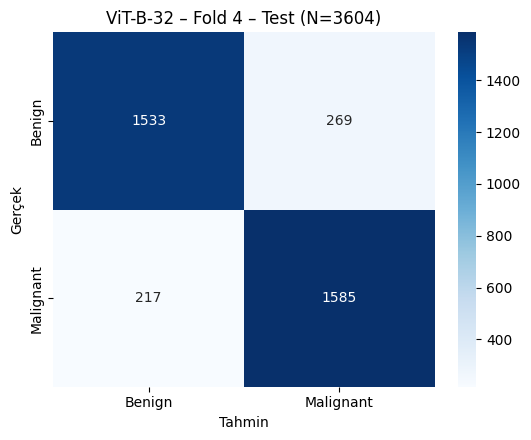

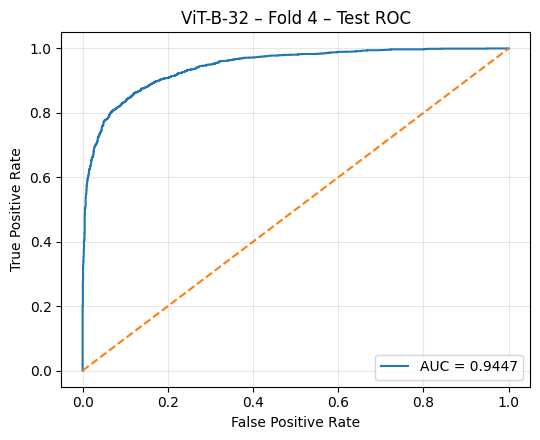

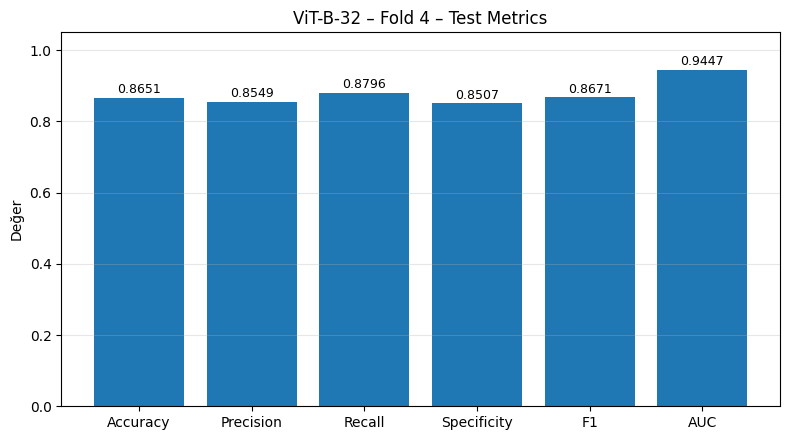

ViT-B-32 – Fold 4 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7300.0,1113.0,896.0,7517.0,0.880601,0.871031,0.893498,0.867705,0.882122,0.951663,0.290395
Validation,3594.0,1496.0,301.0,230.0,1567.0,0.852254,0.838865,0.872009,0.832499,0.855116,0.932834,0.332412
Test,3604.0,1533.0,269.0,217.0,1585.0,0.865150,0.854908,0.879578,0.850721,0.867068,0.944710,0.306186


✓ ViT-B-32 Fold 4: best epoch 10 | Test acc 0.8651
ViT-B-32 | Fold 5 | Epoch 01/10 | Train loss 0.4989 acc 0.7569 | Val loss 0.4254 acc 0.8011
ViT-B-32 | Fold 5 | Epoch 02/10 | Train loss 0.4081 acc 0.8162 | Val loss 0.3831 acc 0.8292
ViT-B-32 | Fold 5 | Epoch 03/10 | Train loss 0.3733 acc 0.8338 | Val loss 0.3683 acc 0.8367
ViT-B-32 | Fold 5 | Epoch 04/10 | Train loss 0.3543 acc 0.8462 | Val loss 0.3505 acc 0.8481
ViT-B-32 | Fold 5 | Epoch 05/10 | Train loss 0.3407 acc 0.8543 | Val loss 0.3409 acc 0.8542
ViT-B-32 | Fold 5 | Epoch 06/10 | Train loss 0.3292 acc 0.8584 | Val loss 0.3349 acc 0.8553
ViT-B-32 | Fold 5 | Epoch 07/10 | Train loss 0.3215 acc 0.8648 | Val loss 0.3255 acc 0.8637
ViT-B-32 | Fold 5 | Epoch 08/10 | Train loss 0.3138 acc 0.8668 | Val loss 0.3225 acc 0.8603
ViT-B-32 | Fold 5 | Epoch 09/10 | Train loss 0.3076 acc 0.8726 | Val loss 0.3279 acc 0.8545
ViT-B-32 | Fold 5 | Epoch 10/10 | Train loss 0.3026 acc 0.8747 | Val loss 0.3116 acc 0.8670


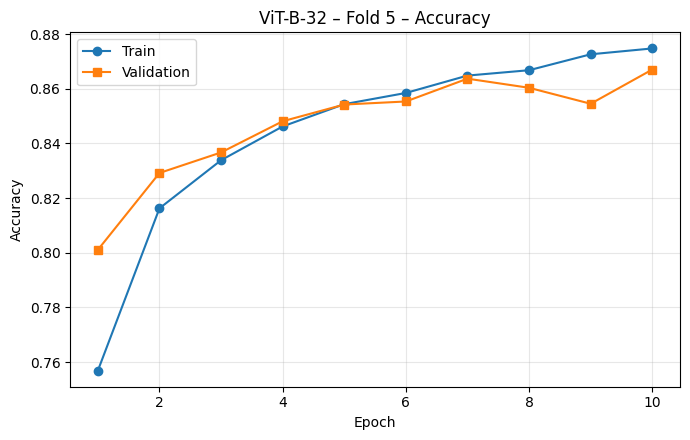

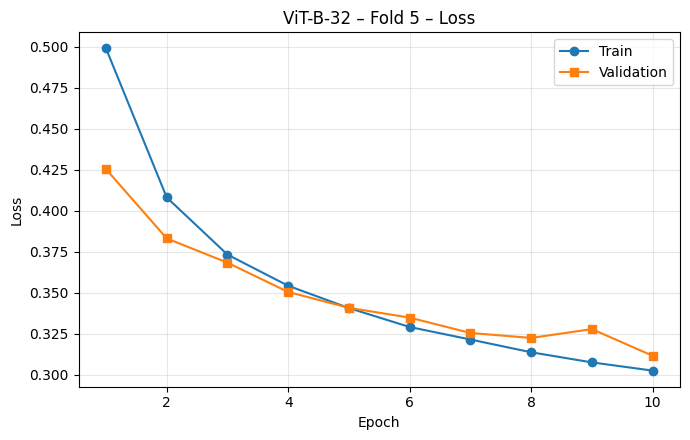

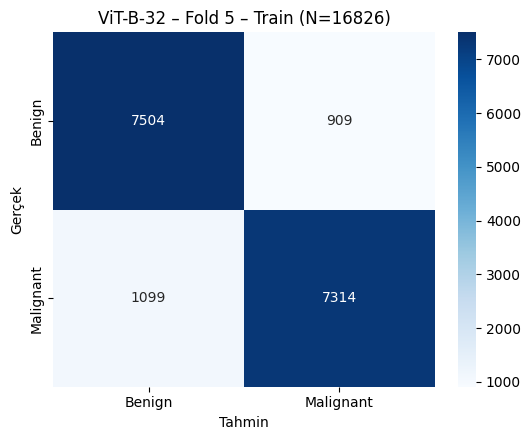

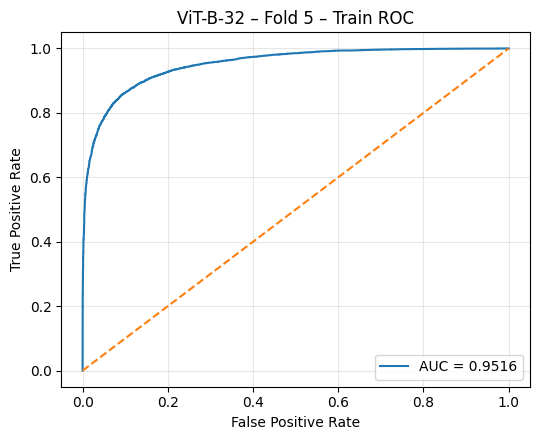

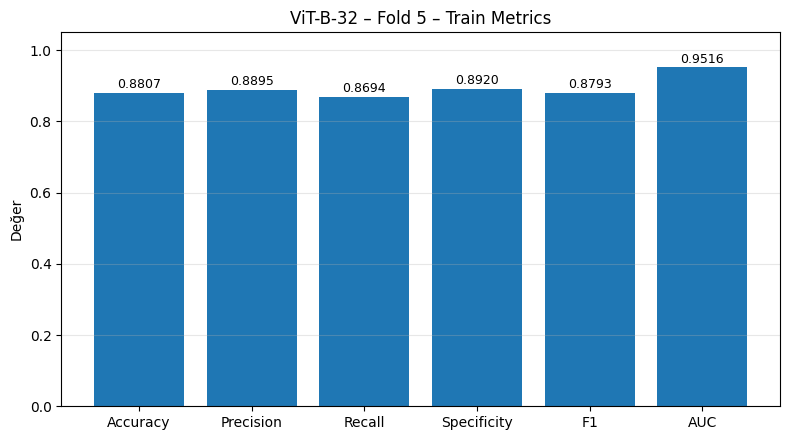

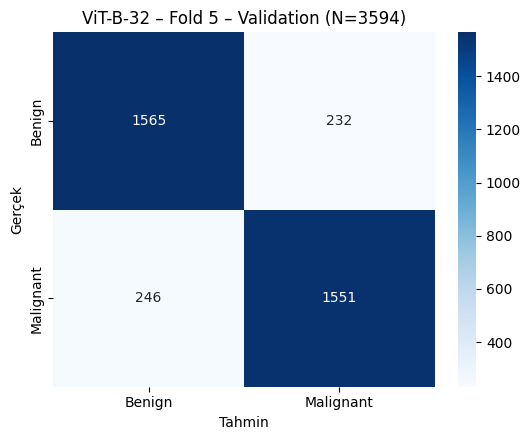

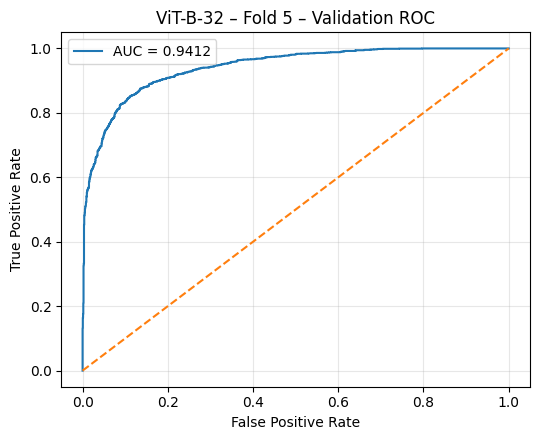

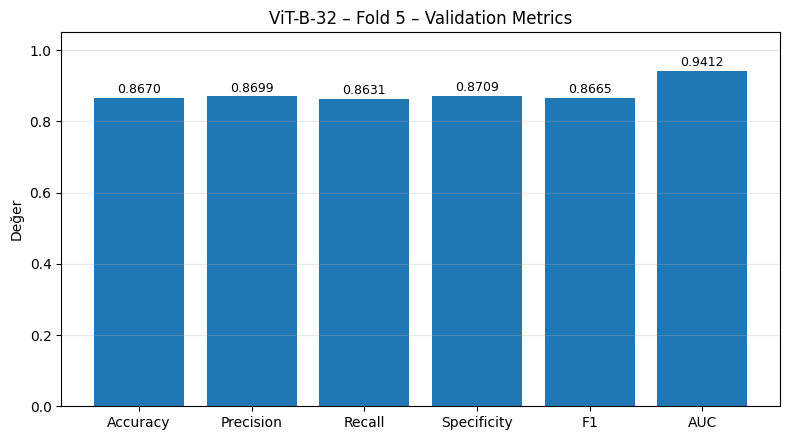

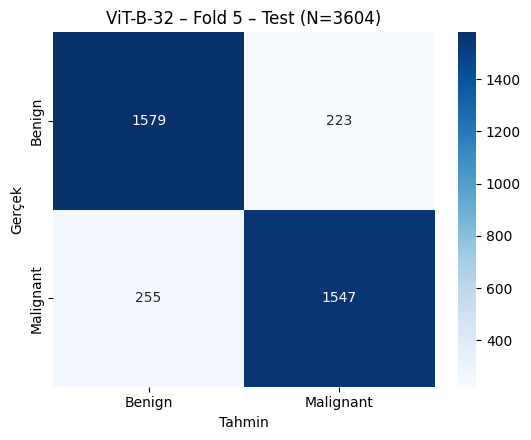

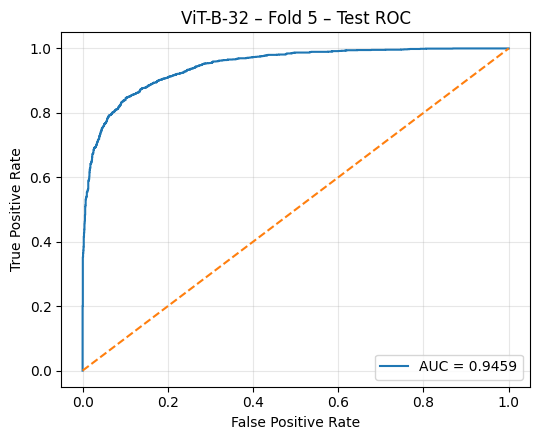

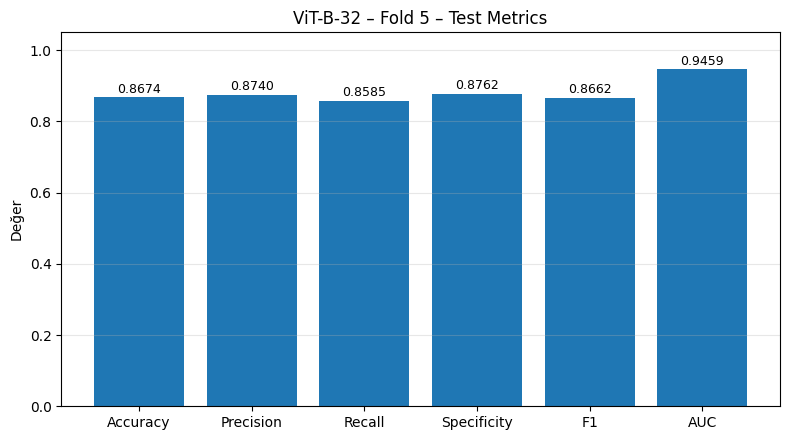

ViT-B-32 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7504.0,909.0,1099.0,7314.0,0.880661,0.889456,0.869369,0.891953,0.879298,0.951564,0.289002
Validation,3594.0,1565.0,232.0,246.0,1551.0,0.867001,0.869882,0.863105,0.870896,0.866480,0.941214,0.311631
Test,3604.0,1579.0,223.0,255.0,1547.0,0.867370,0.874011,0.858491,0.876249,0.866181,0.945934,0.301333


✓ ViT-B-32 Fold 5: best epoch 10 | Test acc 0.8674
Downloading: "https://download.pytorch.org/models/vit_l_16-852ce7e3.pth" to /root/.cache/torch/hub/checkpoints/vit_l_16-852ce7e3.pth


100%|██████████| 1.13G/1.13G [00:05<00:00, 234MB/s]


ViT-L-16 | Fold 1 | Epoch 01/10 | Train loss 0.4808 acc 0.7679 | Val loss 0.4116 acc 0.8178
ViT-L-16 | Fold 1 | Epoch 02/10 | Train loss 0.3907 acc 0.8284 | Val loss 0.3655 acc 0.8422
ViT-L-16 | Fold 1 | Epoch 03/10 | Train loss 0.3551 acc 0.8457 | Val loss 0.3520 acc 0.8453
ViT-L-16 | Fold 1 | Epoch 04/10 | Train loss 0.3345 acc 0.8555 | Val loss 0.3262 acc 0.8637
ViT-L-16 | Fold 1 | Epoch 05/10 | Train loss 0.3206 acc 0.8650 | Val loss 0.3137 acc 0.8712
ViT-L-16 | Fold 1 | Epoch 06/10 | Train loss 0.3077 acc 0.8690 | Val loss 0.3139 acc 0.8667
ViT-L-16 | Fold 1 | Epoch 07/10 | Train loss 0.3006 acc 0.8717 | Val loss 0.3136 acc 0.8692
ViT-L-16 | Fold 1 | Epoch 08/10 | Train loss 0.2900 acc 0.8766 | Val loss 0.2972 acc 0.8801
ViT-L-16 | Fold 1 | Epoch 09/10 | Train loss 0.2846 acc 0.8819 | Val loss 0.2937 acc 0.8792
ViT-L-16 | Fold 1 | Epoch 10/10 | Train loss 0.2810 acc 0.8830 | Val loss 0.2883 acc 0.8823


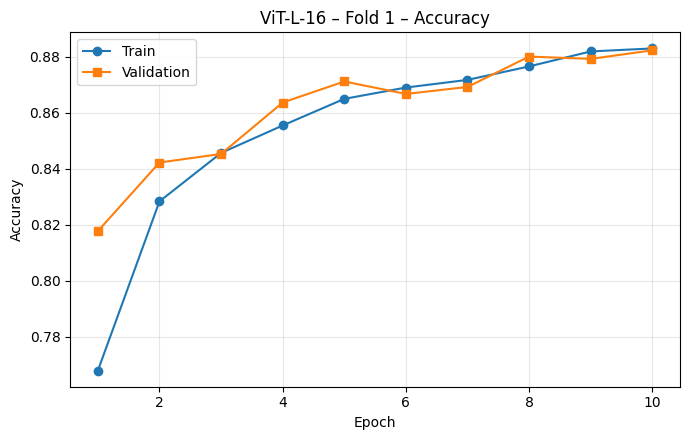

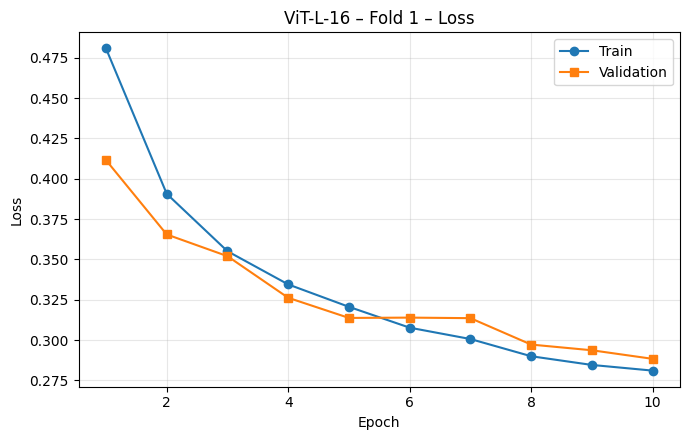

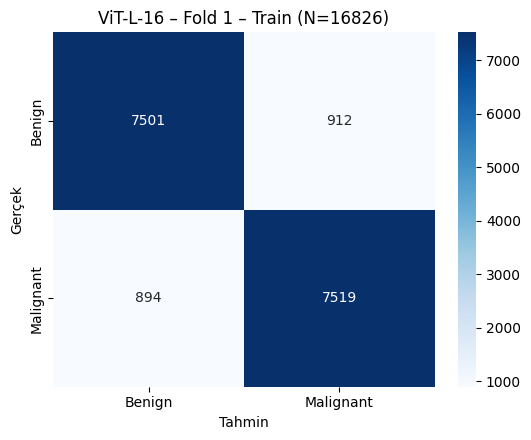

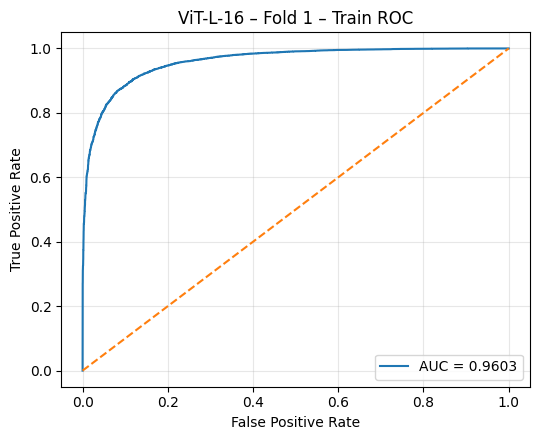

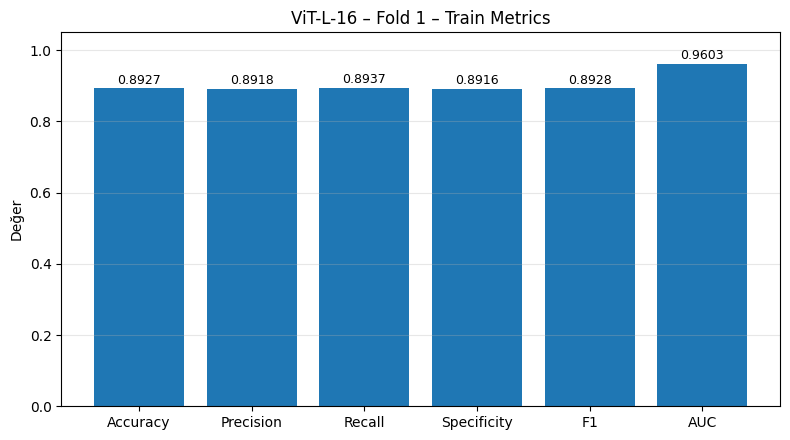

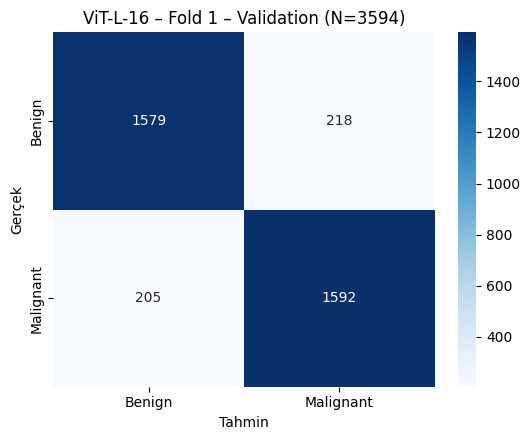

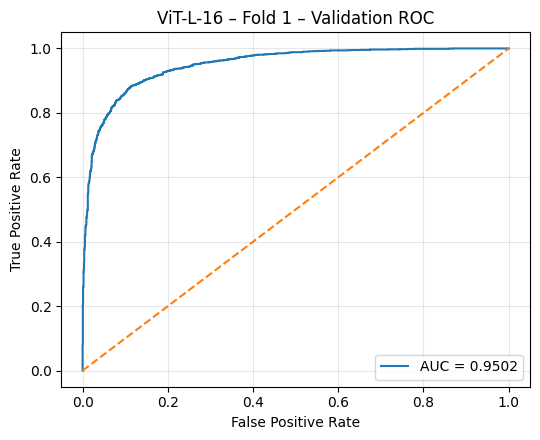

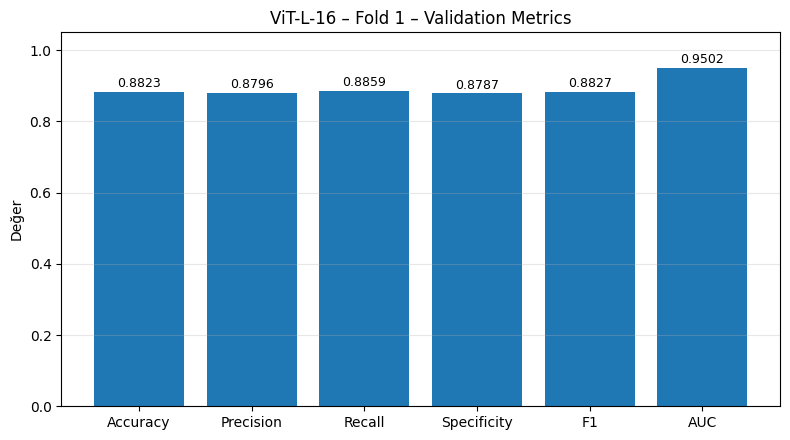

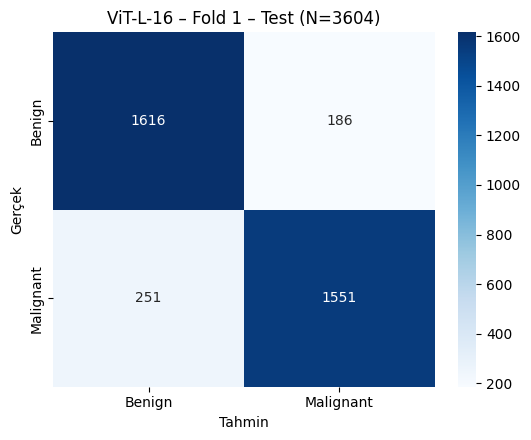

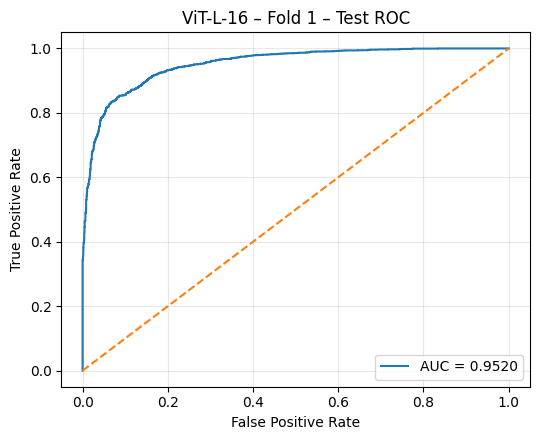

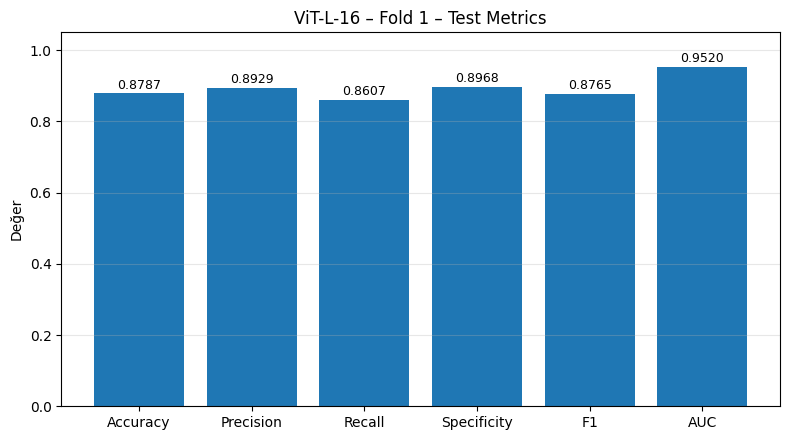

ViT-L-16 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7501.0,912.0,894.0,7519.0,0.892666,0.891828,0.893736,0.891596,0.892781,0.960333,0.263172
Validation,3594.0,1579.0,218.0,205.0,1592.0,0.882304,0.879558,0.885921,0.878687,0.882728,0.950248,0.288339
Test,3604.0,1616.0,186.0,251.0,1551.0,0.878746,0.892919,0.860710,0.896781,0.876519,0.951991,0.282395


✓ ViT-L-16 Fold 1: best epoch 10 | Test acc 0.8787
ViT-L-16 | Fold 2 | Epoch 01/10 | Train loss 0.4806 acc 0.7652 | Val loss 0.4193 acc 0.8055
ViT-L-16 | Fold 2 | Epoch 02/10 | Train loss 0.3882 acc 0.8315 | Val loss 0.3729 acc 0.8372
ViT-L-16 | Fold 2 | Epoch 03/10 | Train loss 0.3527 acc 0.8491 | Val loss 0.3715 acc 0.8331
ViT-L-16 | Fold 2 | Epoch 04/10 | Train loss 0.3357 acc 0.8547 | Val loss 0.3454 acc 0.8620
ViT-L-16 | Fold 2 | Epoch 05/10 | Train loss 0.3161 acc 0.8665 | Val loss 0.3399 acc 0.8542
ViT-L-16 | Fold 2 | Epoch 06/10 | Train loss 0.3043 acc 0.8723 | Val loss 0.3283 acc 0.8548
ViT-L-16 | Fold 2 | Epoch 07/10 | Train loss 0.2954 acc 0.8772 | Val loss 0.3192 acc 0.8600
ViT-L-16 | Fold 2 | Epoch 08/10 | Train loss 0.2874 acc 0.8803 | Val loss 0.3133 acc 0.8634
ViT-L-16 | Fold 2 | Epoch 09/10 | Train loss 0.2806 acc 0.8839 | Val loss 0.3084 acc 0.8673
ViT-L-16 | Fold 2 | Epoch 10/10 | Train loss 0.2763 acc 0.8857 | Val loss 0.3035 acc 0.8656


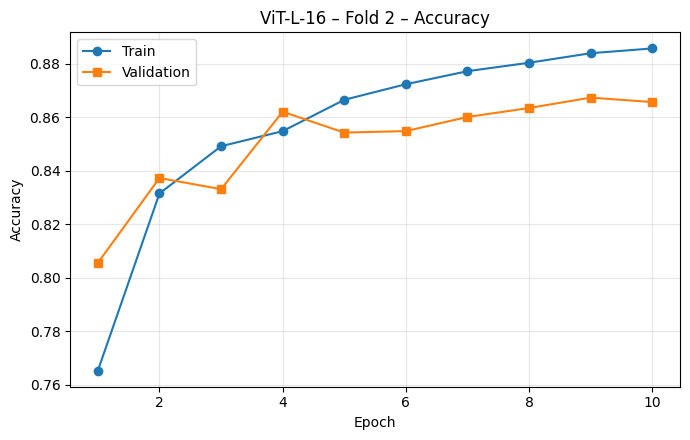

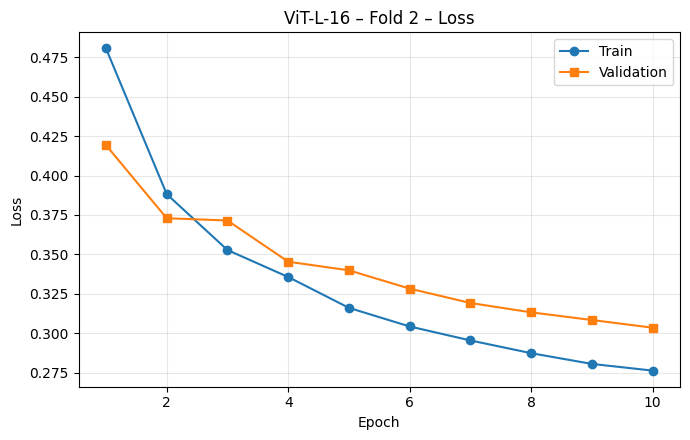

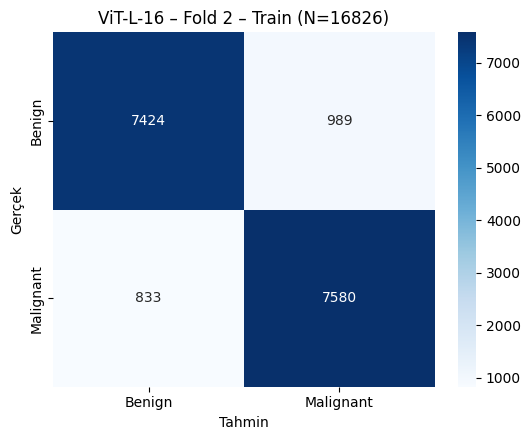

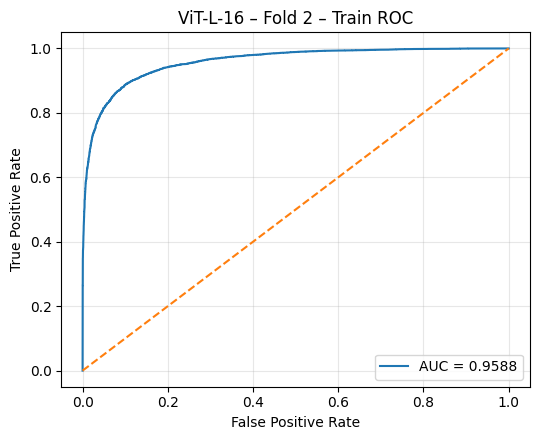

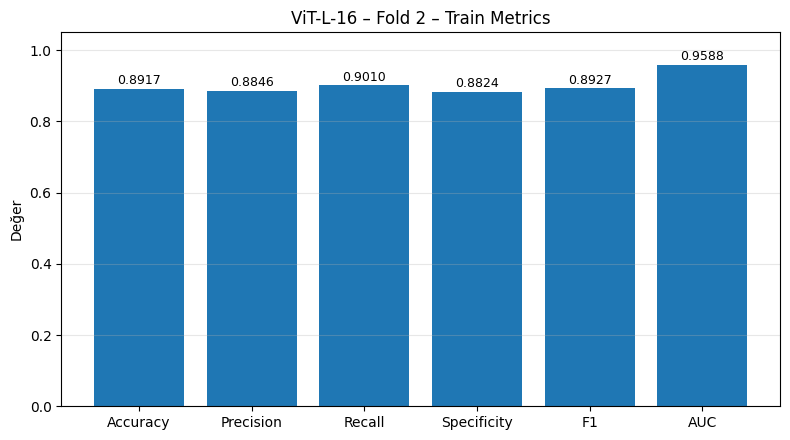

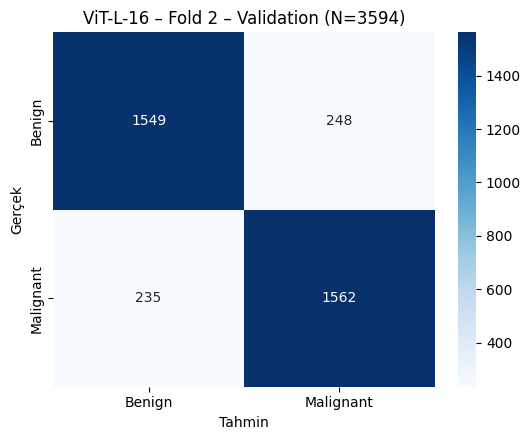

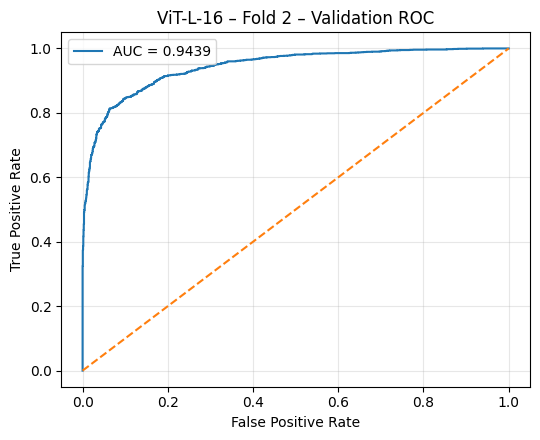

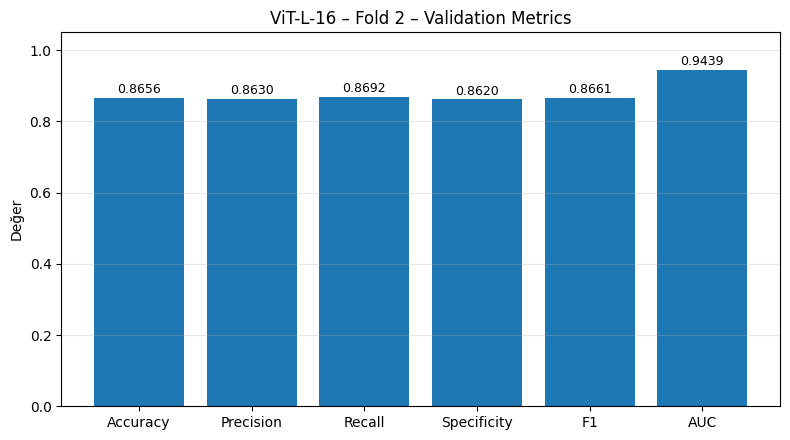

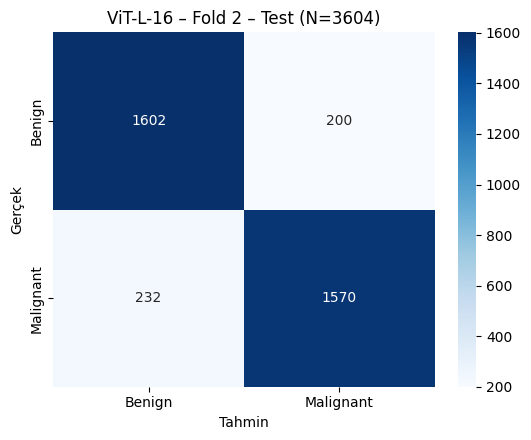

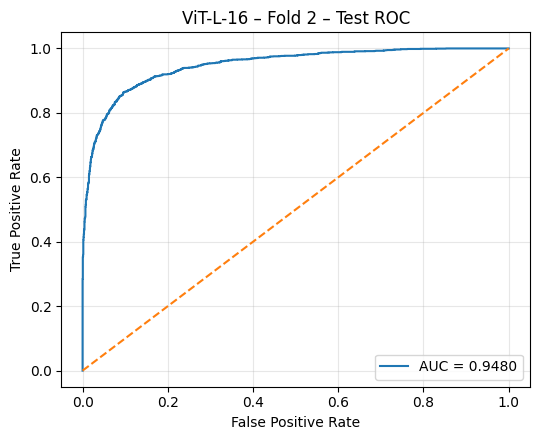

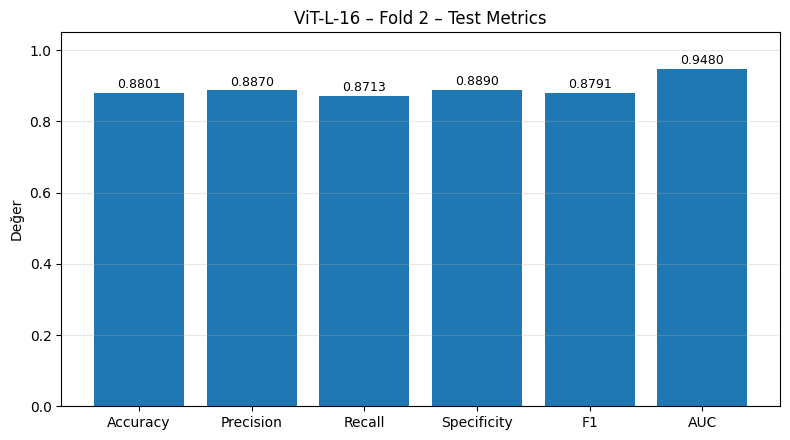

ViT-L-16 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7424.0,989.0,833.0,7580.0,0.891715,0.884584,0.900987,0.882444,0.892710,0.958774,0.268552
Validation,3594.0,1549.0,248.0,235.0,1562.0,0.865609,0.862983,0.869226,0.861992,0.866094,0.943930,0.303520
Test,3604.0,1602.0,200.0,232.0,1570.0,0.880133,0.887006,0.871254,0.889012,0.879059,0.948048,0.292104


✓ ViT-L-16 Fold 2: best epoch 10 | Test acc 0.8801
ViT-L-16 | Fold 3 | Epoch 01/10 | Train loss 0.4834 acc 0.7692 | Val loss 0.4241 acc 0.8036
ViT-L-16 | Fold 3 | Epoch 02/10 | Train loss 0.3892 acc 0.8288 | Val loss 0.3781 acc 0.8347
ViT-L-16 | Fold 3 | Epoch 03/10 | Train loss 0.3560 acc 0.8458 | Val loss 0.3827 acc 0.8264
ViT-L-16 | Fold 3 | Epoch 04/10 | Train loss 0.3346 acc 0.8583 | Val loss 0.3382 acc 0.8561
ViT-L-16 | Fold 3 | Epoch 05/10 | Train loss 0.3186 acc 0.8643 | Val loss 0.3191 acc 0.8642
ViT-L-16 | Fold 3 | Epoch 06/10 | Train loss 0.3083 acc 0.8676 | Val loss 0.3469 acc 0.8489
ViT-L-16 | Fold 3 | Epoch 07/10 | Train loss 0.2987 acc 0.8731 | Val loss 0.3094 acc 0.8648
ViT-L-16 | Fold 3 | Epoch 08/10 | Train loss 0.2908 acc 0.8772 | Val loss 0.2979 acc 0.8748
ViT-L-16 | Fold 3 | Epoch 09/10 | Train loss 0.2834 acc 0.8810 | Val loss 0.2906 acc 0.8798
ViT-L-16 | Fold 3 | Epoch 10/10 | Train loss 0.2794 acc 0.8824 | Val loss 0.2934 acc 0.8723


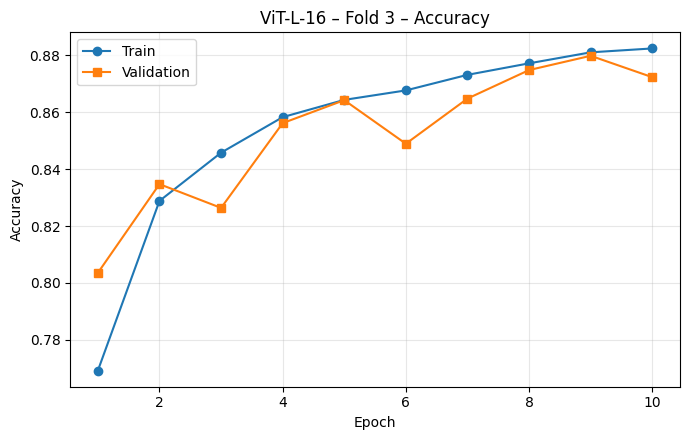

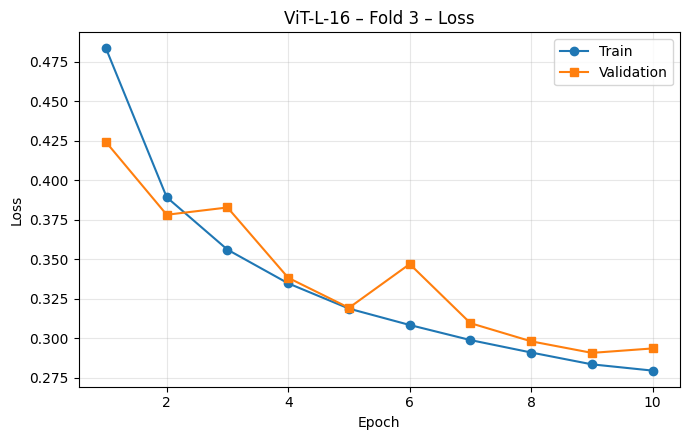

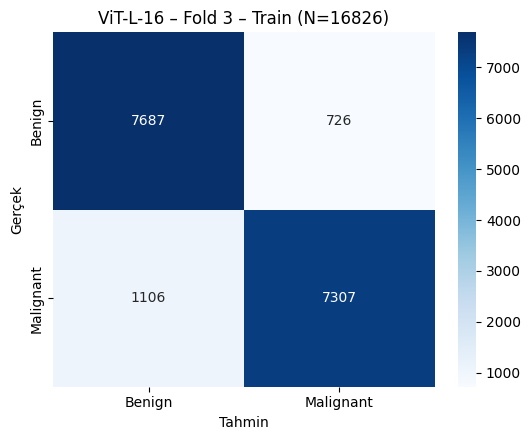

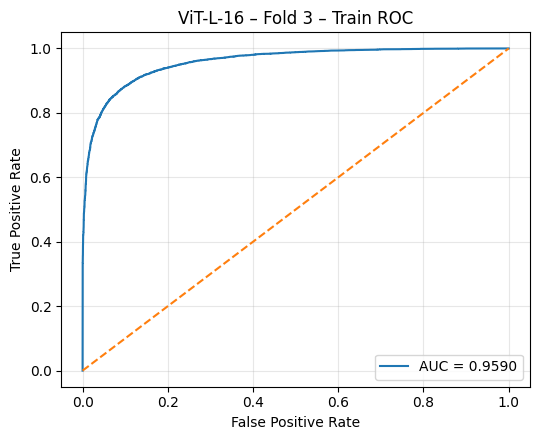

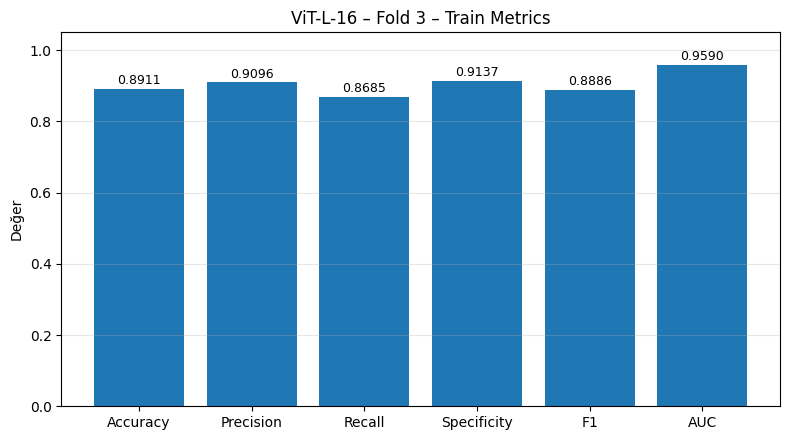

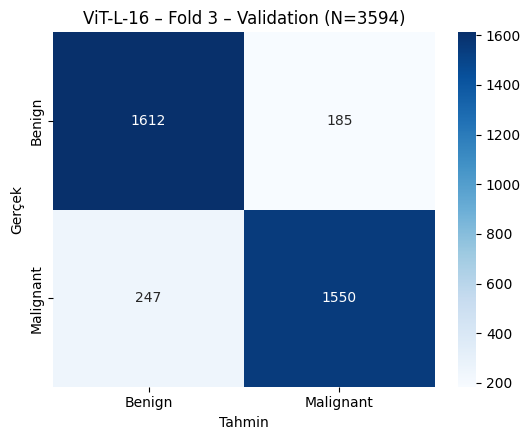

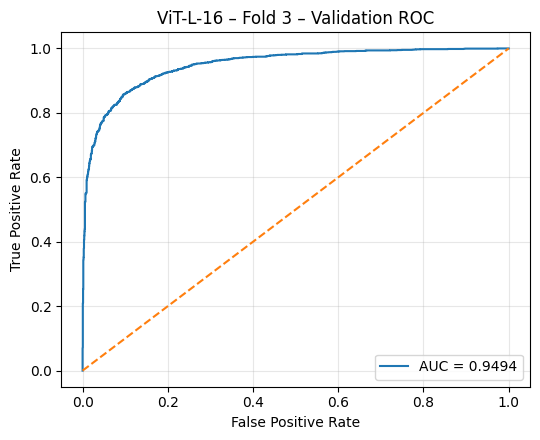

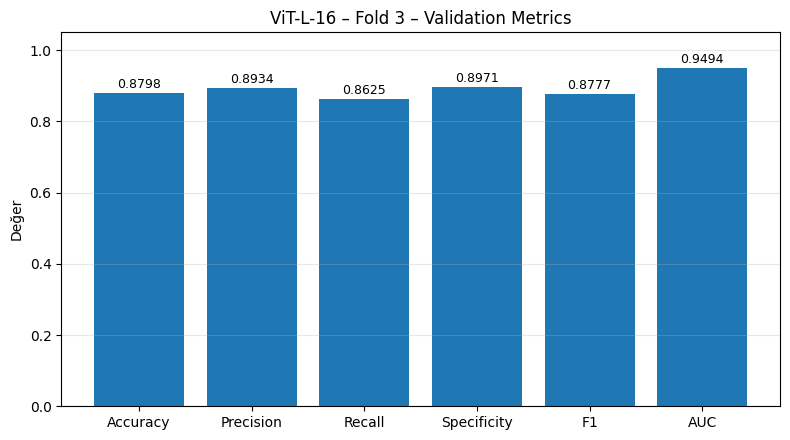

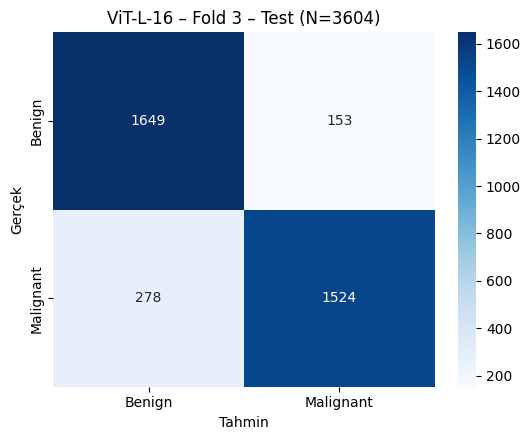

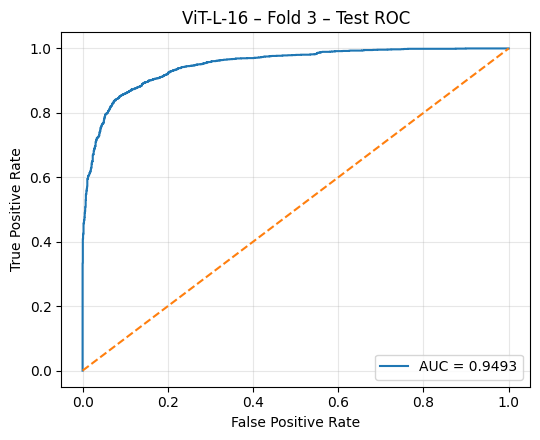

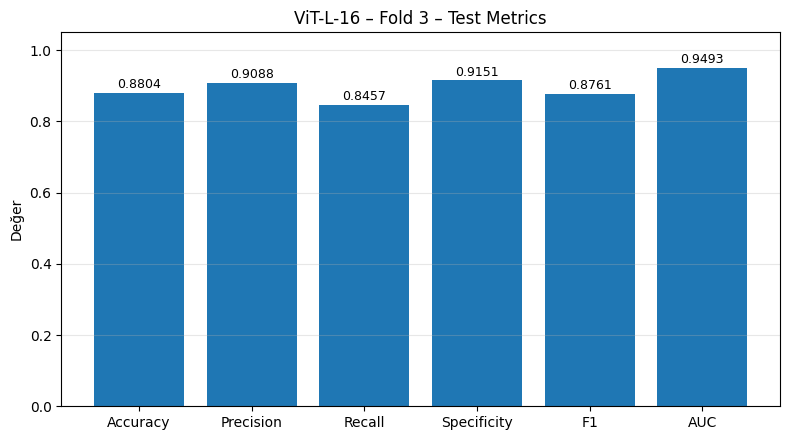

ViT-L-16 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7687.0,726.0,1106.0,7307.0,0.891121,0.909623,0.868537,0.913705,0.888605,0.959005,0.267762
Validation,3594.0,1612.0,185.0,247.0,1550.0,0.879800,0.893372,0.862549,0.897051,0.877690,0.949378,0.290620
Test,3604.0,1649.0,153.0,278.0,1524.0,0.880411,0.908766,0.845727,0.915094,0.876114,0.949297,0.291427


✓ ViT-L-16 Fold 3: best epoch 9 | Test acc 0.8804
ViT-L-16 | Fold 4 | Epoch 01/10 | Train loss 0.4801 acc 0.7699 | Val loss 0.4228 acc 0.7983
ViT-L-16 | Fold 4 | Epoch 02/10 | Train loss 0.3876 acc 0.8295 | Val loss 0.3987 acc 0.8225
ViT-L-16 | Fold 4 | Epoch 03/10 | Train loss 0.3544 acc 0.8465 | Val loss 0.3733 acc 0.8358
ViT-L-16 | Fold 4 | Epoch 04/10 | Train loss 0.3322 acc 0.8599 | Val loss 0.3409 acc 0.8489
ViT-L-16 | Fold 4 | Epoch 05/10 | Train loss 0.3156 acc 0.8667 | Val loss 0.3426 acc 0.8511
ViT-L-16 | Fold 4 | Epoch 06/10 | Train loss 0.3032 acc 0.8717 | Val loss 0.3348 acc 0.8500
ViT-L-16 | Fold 4 | Epoch 07/10 | Train loss 0.2939 acc 0.8791 | Val loss 0.3277 acc 0.8548
ViT-L-16 | Fold 4 | Epoch 08/10 | Train loss 0.2866 acc 0.8817 | Val loss 0.3253 acc 0.8587
ViT-L-16 | Fold 4 | Epoch 09/10 | Train loss 0.2822 acc 0.8851 | Val loss 0.3078 acc 0.8689
ViT-L-16 | Fold 4 | Epoch 10/10 | Train loss 0.2751 acc 0.8855 | Val loss 0.3184 acc 0.8595


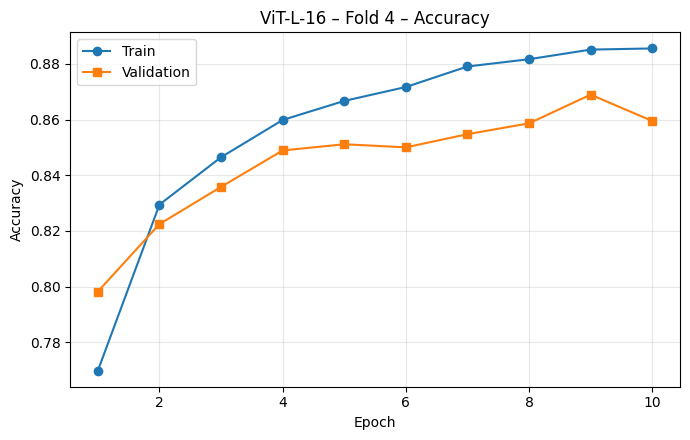

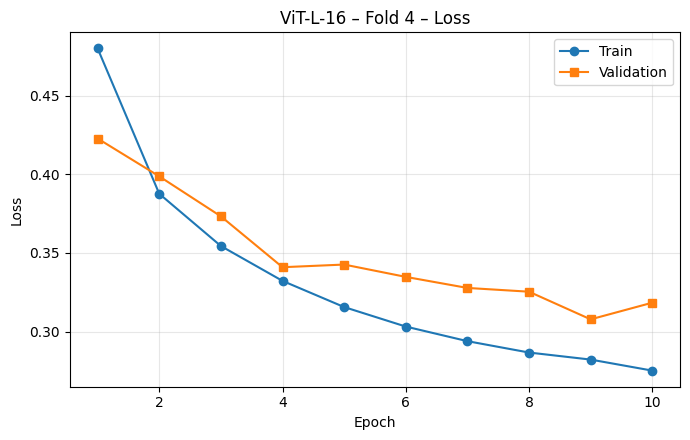

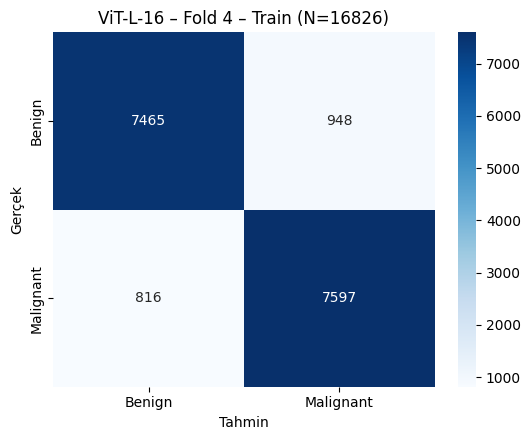

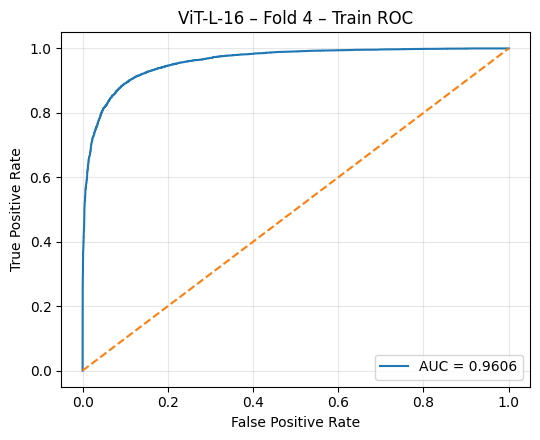

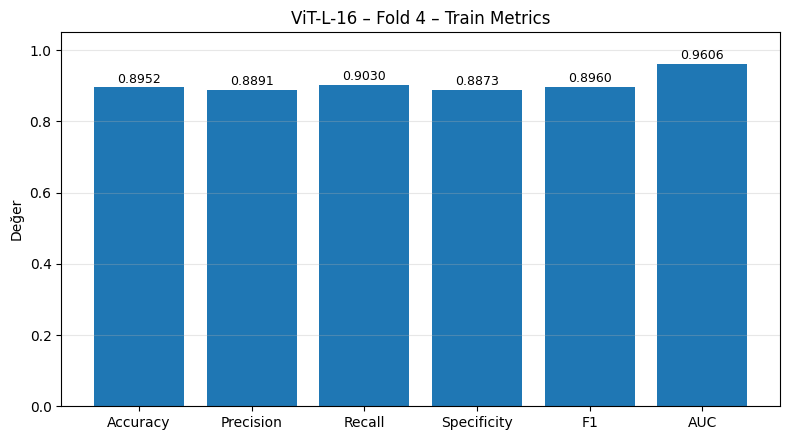

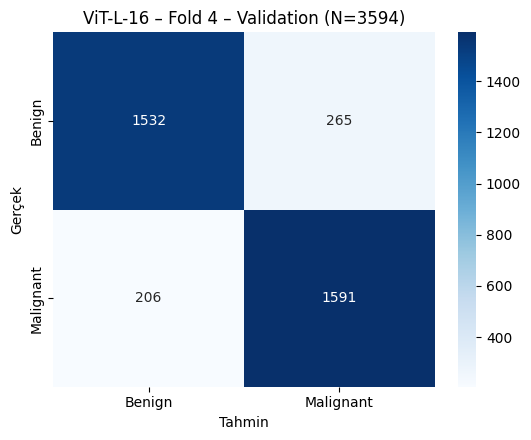

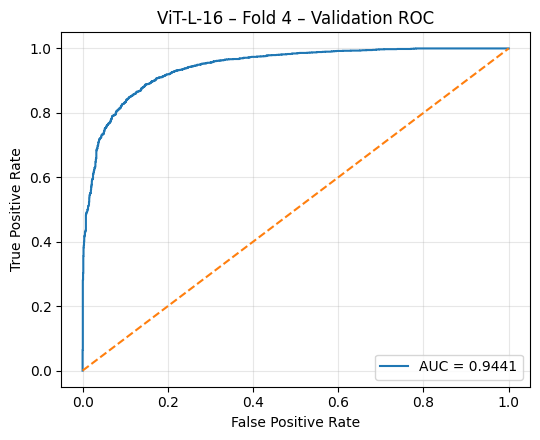

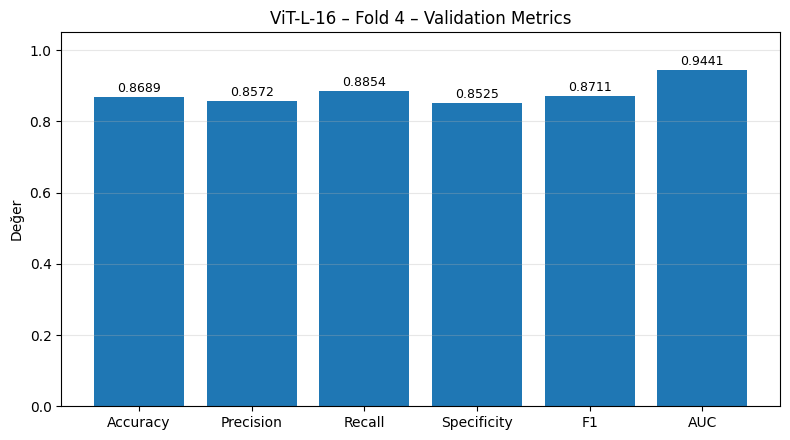

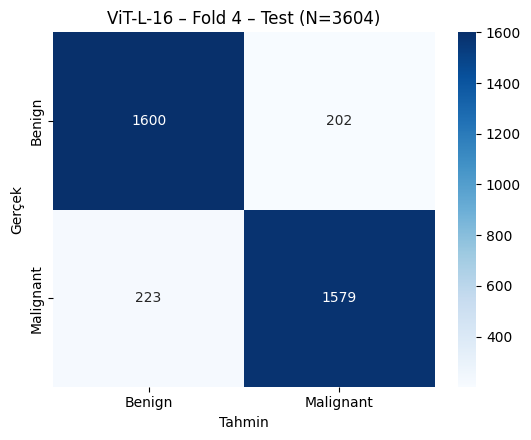

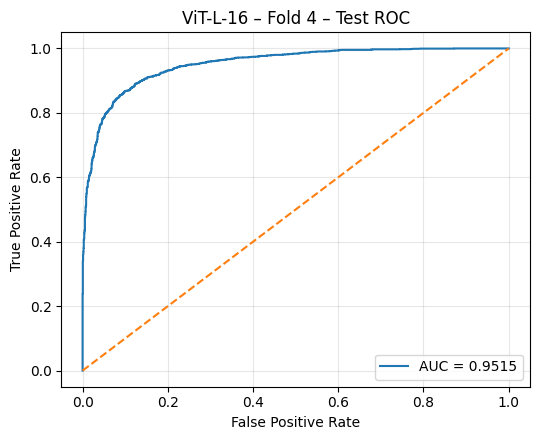

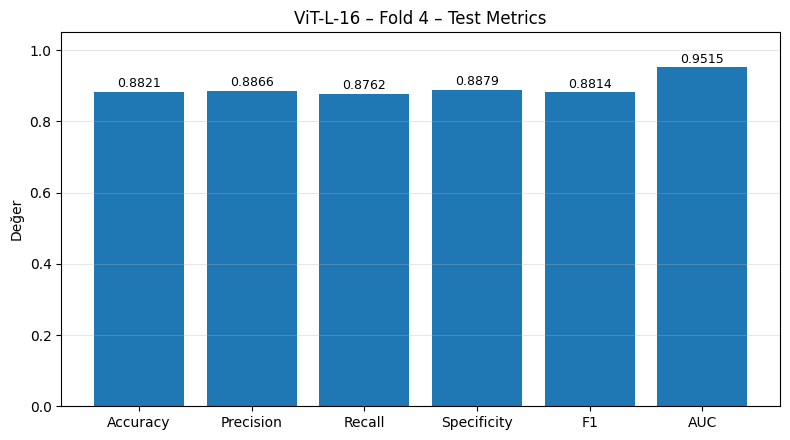

ViT-L-16 – Fold 4 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7465.0,948.0,816.0,7597.0,0.895162,0.889058,0.903007,0.887317,0.895978,0.960645,0.266048
Validation,3594.0,1532.0,265.0,206.0,1591.0,0.868948,0.857220,0.885364,0.852532,0.871065,0.944082,0.307757
Test,3604.0,1600.0,202.0,223.0,1579.0,0.882075,0.886581,0.876249,0.887902,0.881384,0.951499,0.286355


✓ ViT-L-16 Fold 4: best epoch 9 | Test acc 0.8821
ViT-L-16 | Fold 5 | Epoch 01/10 | Train loss 0.4820 acc 0.7690 | Val loss 0.4117 acc 0.8105
ViT-L-16 | Fold 5 | Epoch 02/10 | Train loss 0.3894 acc 0.8295 | Val loss 0.3664 acc 0.8364
ViT-L-16 | Fold 5 | Epoch 03/10 | Train loss 0.3543 acc 0.8467 | Val loss 0.3534 acc 0.8481
ViT-L-16 | Fold 5 | Epoch 04/10 | Train loss 0.3349 acc 0.8567 | Val loss 0.3250 acc 0.8587
ViT-L-16 | Fold 5 | Epoch 05/10 | Train loss 0.3214 acc 0.8636 | Val loss 0.3202 acc 0.8664
ViT-L-16 | Fold 5 | Epoch 06/10 | Train loss 0.3069 acc 0.8717 | Val loss 0.3109 acc 0.8703
ViT-L-16 | Fold 5 | Epoch 07/10 | Train loss 0.3013 acc 0.8738 | Val loss 0.3304 acc 0.8436
ViT-L-16 | Fold 5 | Epoch 08/10 | Train loss 0.2910 acc 0.8767 | Val loss 0.3082 acc 0.8662
ViT-L-16 | Fold 5 | Epoch 09/10 | Train loss 0.2847 acc 0.8804 | Val loss 0.2886 acc 0.8801
ViT-L-16 | Fold 5 | Epoch 10/10 | Train loss 0.2796 acc 0.8843 | Val loss 0.2883 acc 0.8845


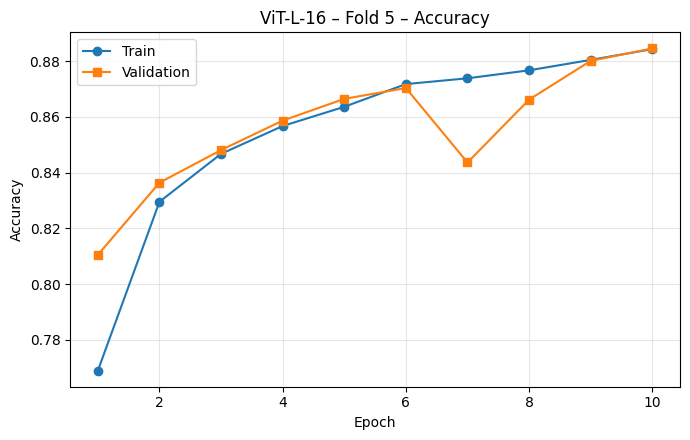

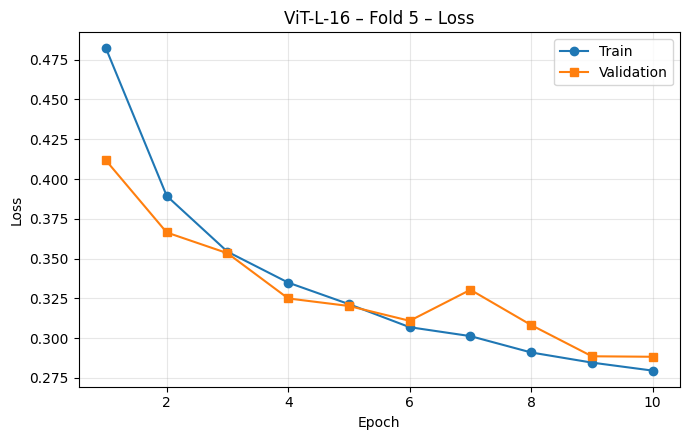

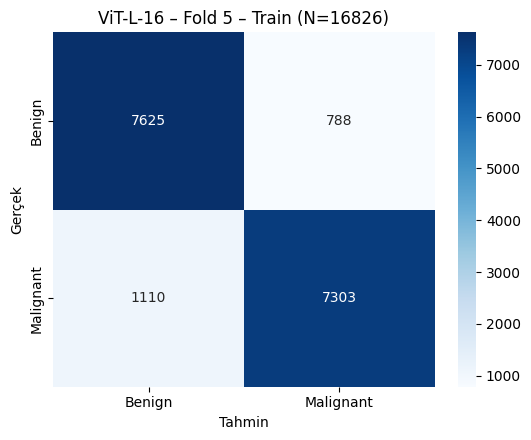

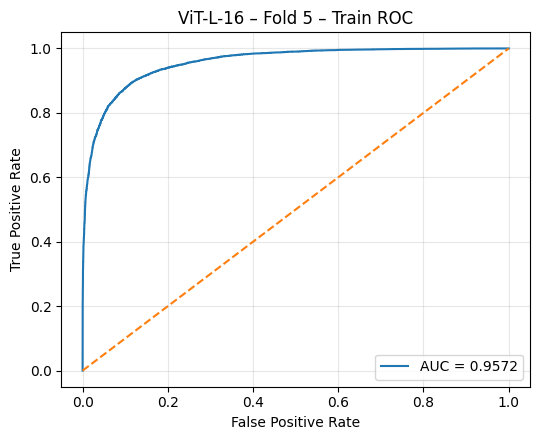

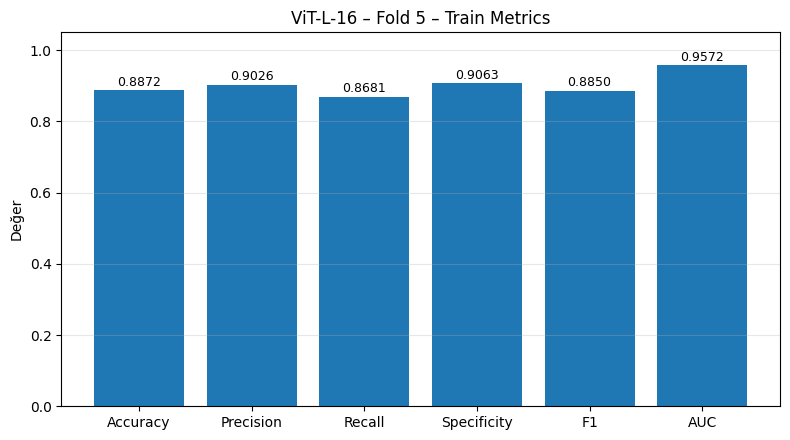

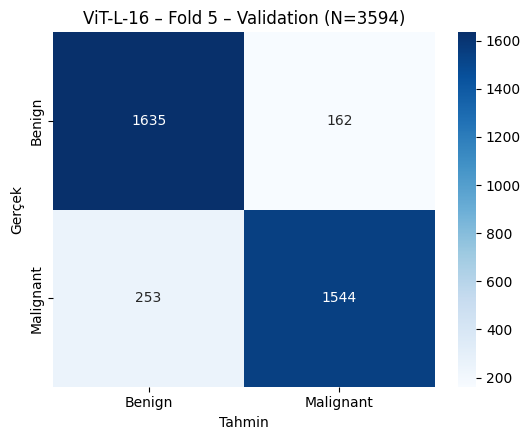

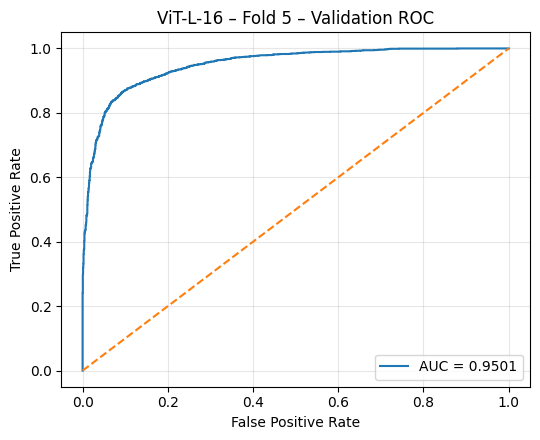

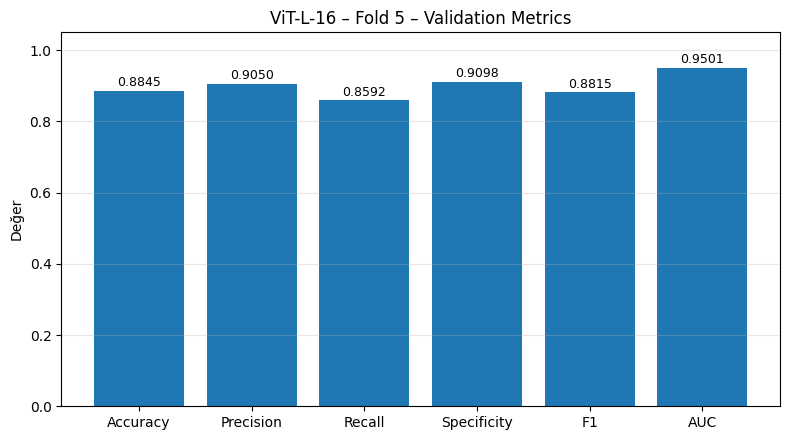

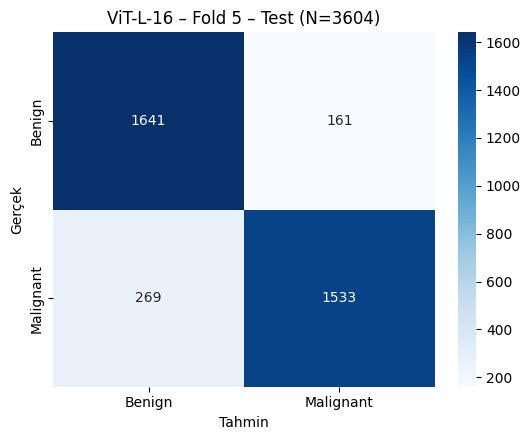

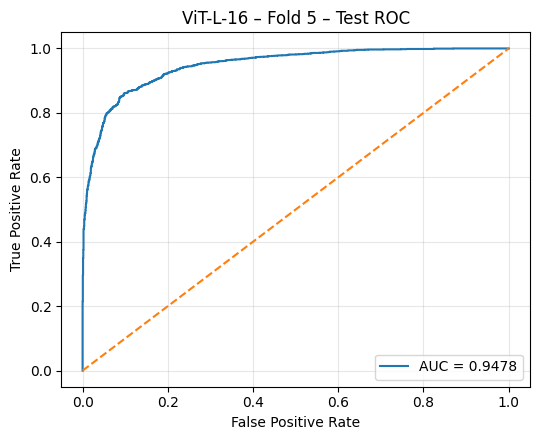

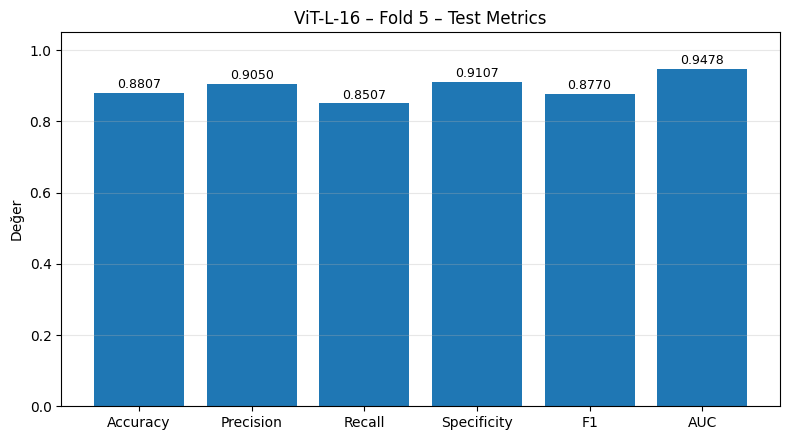

ViT-L-16 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7625.0,788.0,1110.0,7303.0,0.887198,0.902608,0.868061,0.906335,0.884998,0.957193,0.271322
Validation,3594.0,1635.0,162.0,253.0,1544.0,0.884530,0.905041,0.859210,0.909850,0.881530,0.950099,0.288333
Test,3604.0,1641.0,161.0,269.0,1533.0,0.880688,0.904959,0.850721,0.910655,0.877002,0.947797,0.294165


✓ ViT-L-16 Fold 5: best epoch 10 | Test acc 0.8807
Downloading: "https://download.pytorch.org/models/vit_l_32-c7638314.pth" to /root/.cache/torch/hub/checkpoints/vit_l_32-c7638314.pth


100%|██████████| 1.14G/1.14G [00:05<00:00, 221MB/s]


ViT-L-32 | Fold 1 | Epoch 01/10 | Train loss 0.4837 acc 0.7619 | Val loss 0.4217 acc 0.8105
ViT-L-32 | Fold 1 | Epoch 02/10 | Train loss 0.3821 acc 0.8346 | Val loss 0.3730 acc 0.8422
ViT-L-32 | Fold 1 | Epoch 03/10 | Train loss 0.3461 acc 0.8524 | Val loss 0.3519 acc 0.8520
ViT-L-32 | Fold 1 | Epoch 04/10 | Train loss 0.3212 acc 0.8638 | Val loss 0.3381 acc 0.8575
ViT-L-32 | Fold 1 | Epoch 05/10 | Train loss 0.3078 acc 0.8692 | Val loss 0.3234 acc 0.8603
ViT-L-32 | Fold 1 | Epoch 06/10 | Train loss 0.2931 acc 0.8771 | Val loss 0.3126 acc 0.8681
ViT-L-32 | Fold 1 | Epoch 07/10 | Train loss 0.2857 acc 0.8821 | Val loss 0.3086 acc 0.8734
ViT-L-32 | Fold 1 | Epoch 08/10 | Train loss 0.2759 acc 0.8857 | Val loss 0.3061 acc 0.8759
ViT-L-32 | Fold 1 | Epoch 09/10 | Train loss 0.2694 acc 0.8899 | Val loss 0.3010 acc 0.8701
ViT-L-32 | Fold 1 | Epoch 10/10 | Train loss 0.2642 acc 0.8916 | Val loss 0.2983 acc 0.8792


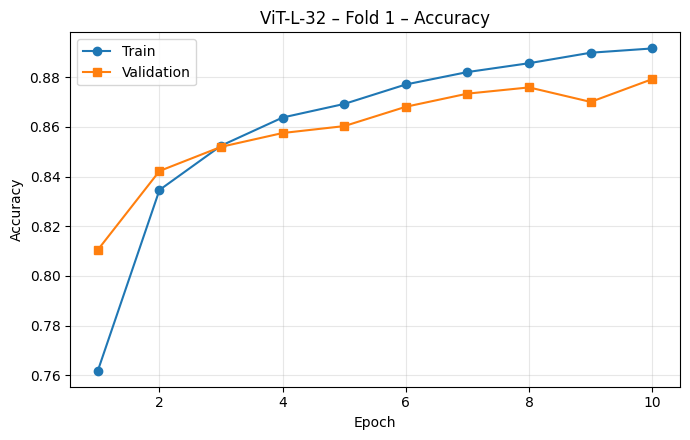

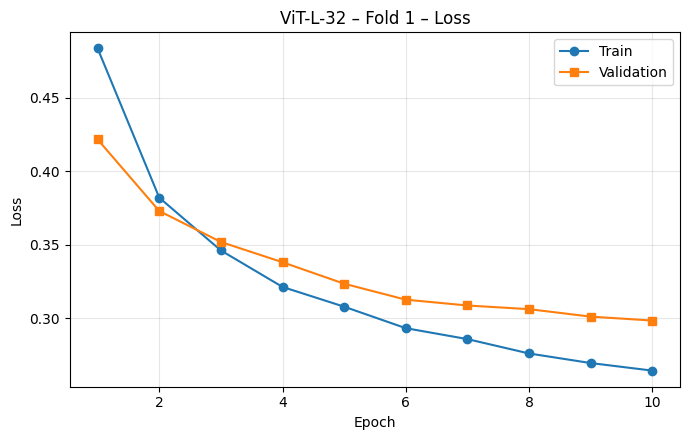

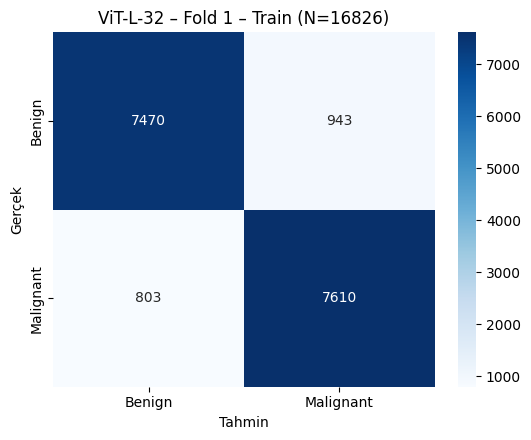

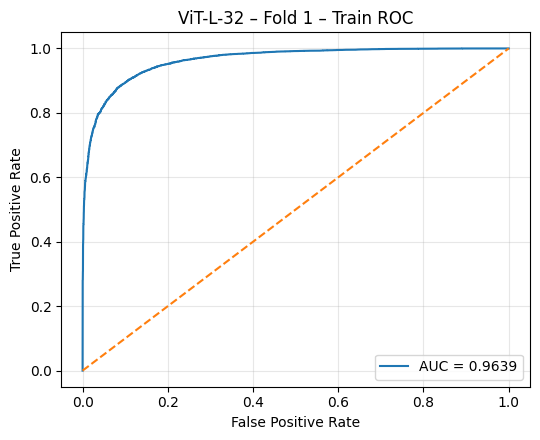

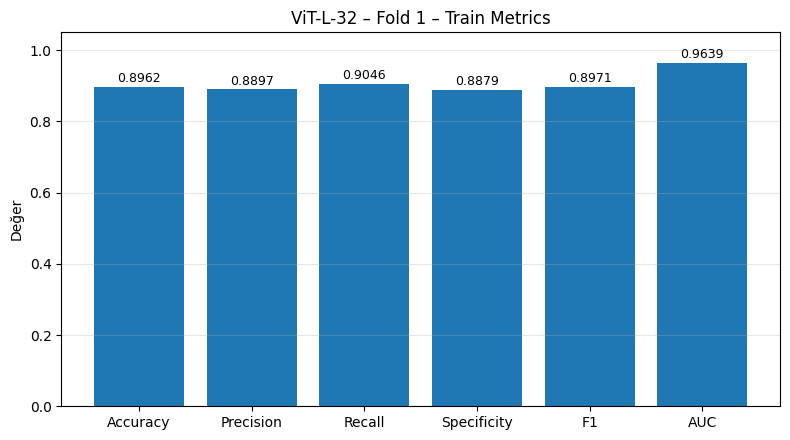

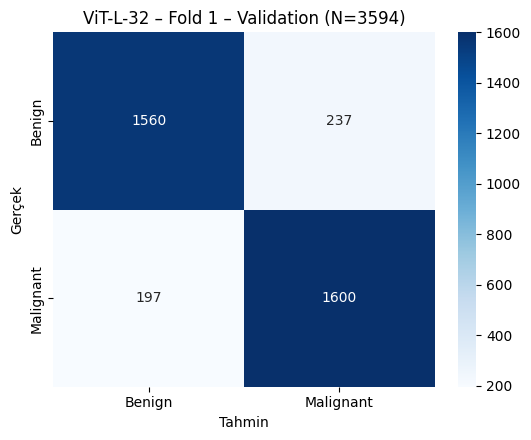

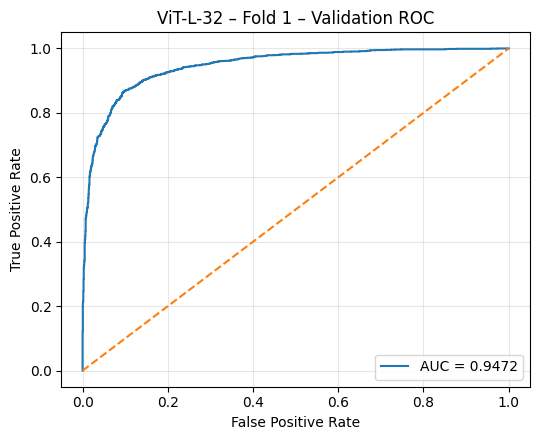

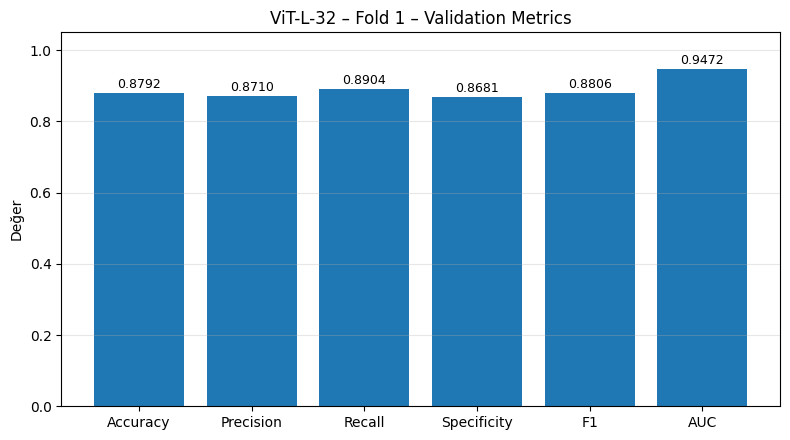

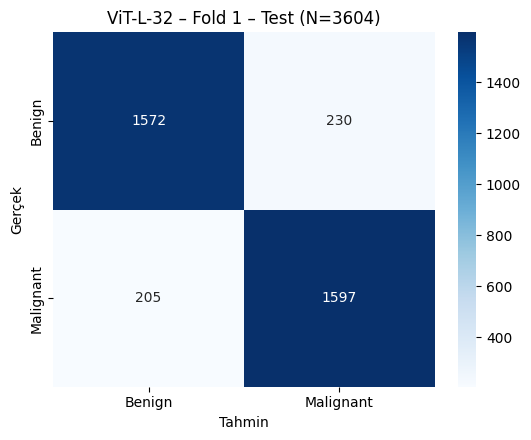

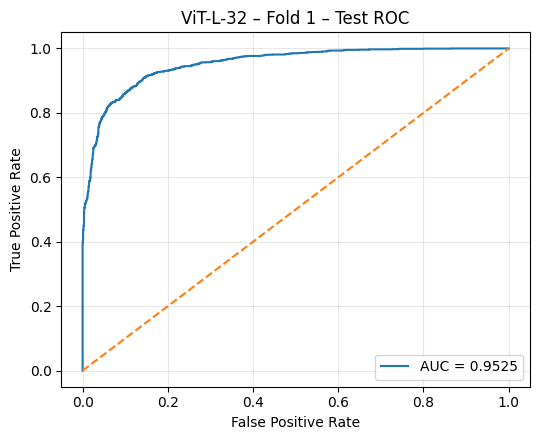

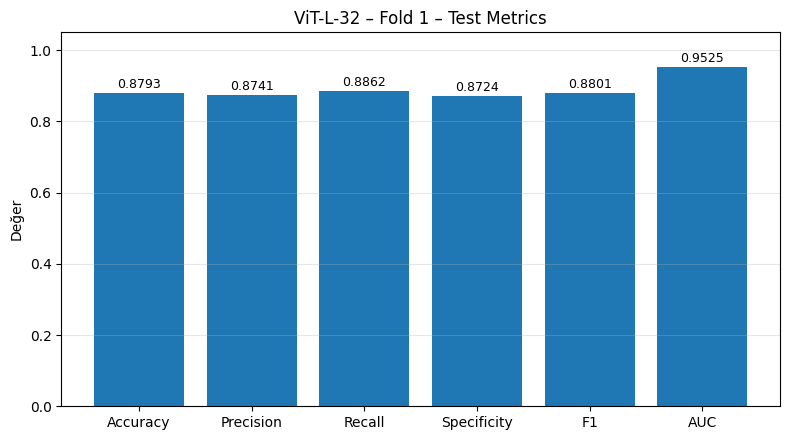

ViT-L-32 – Fold 1 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7470.0,943.0,803.0,7610.0,0.896232,0.889746,0.904552,0.887912,0.897088,0.963918,0.253959
Validation,3594.0,1560.0,237.0,197.0,1600.0,0.879243,0.870985,0.890373,0.868114,0.880572,0.947162,0.298339
Test,3604.0,1572.0,230.0,205.0,1597.0,0.879301,0.874111,0.886238,0.872364,0.880132,0.952455,0.281736


✓ ViT-L-32 Fold 1: best epoch 10 | Test acc 0.8793
ViT-L-32 | Fold 2 | Epoch 01/10 | Train loss 0.4855 acc 0.7652 | Val loss 0.4147 acc 0.8063
ViT-L-32 | Fold 2 | Epoch 02/10 | Train loss 0.3839 acc 0.8314 | Val loss 0.3664 acc 0.8436
ViT-L-32 | Fold 2 | Epoch 03/10 | Train loss 0.3450 acc 0.8529 | Val loss 0.3581 acc 0.8428
ViT-L-32 | Fold 2 | Epoch 04/10 | Train loss 0.3233 acc 0.8637 | Val loss 0.3281 acc 0.8603
ViT-L-32 | Fold 2 | Epoch 05/10 | Train loss 0.3057 acc 0.8723 | Val loss 0.3202 acc 0.8662
ViT-L-32 | Fold 2 | Epoch 06/10 | Train loss 0.2937 acc 0.8772 | Val loss 0.3102 acc 0.8703
ViT-L-32 | Fold 2 | Epoch 07/10 | Train loss 0.2825 acc 0.8841 | Val loss 0.3051 acc 0.8676
ViT-L-32 | Fold 2 | Epoch 08/10 | Train loss 0.2758 acc 0.8873 | Val loss 0.2954 acc 0.8734
ViT-L-32 | Fold 2 | Epoch 09/10 | Train loss 0.2695 acc 0.8908 | Val loss 0.2971 acc 0.8726
ViT-L-32 | Fold 2 | Epoch 10/10 | Train loss 0.2640 acc 0.8927 | Val loss 0.3069 acc 0.8701


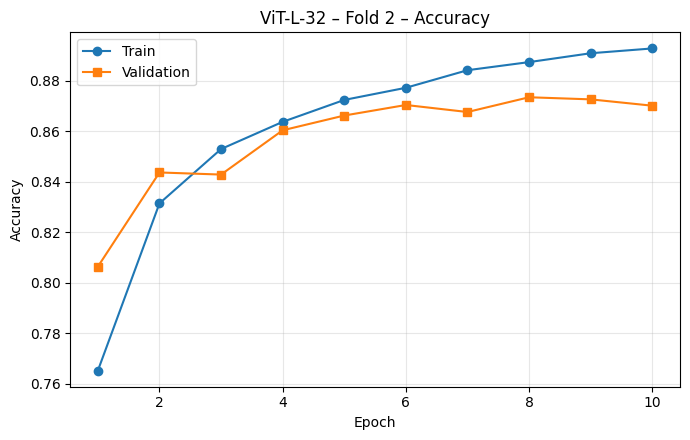

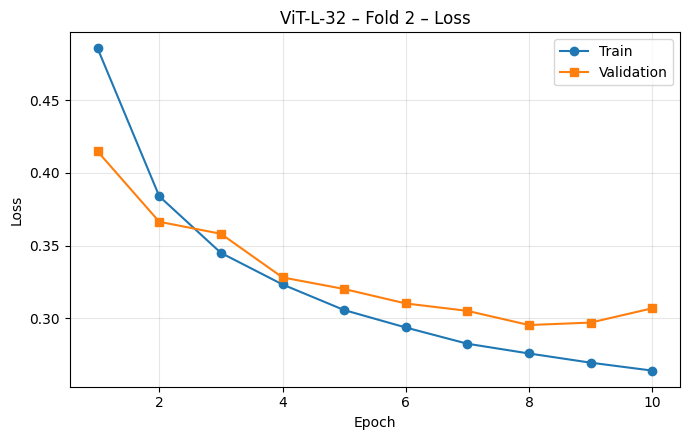

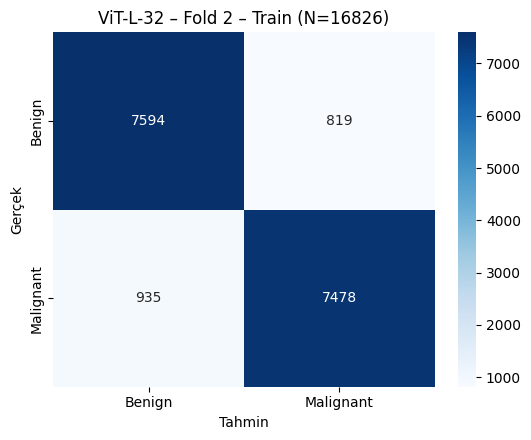

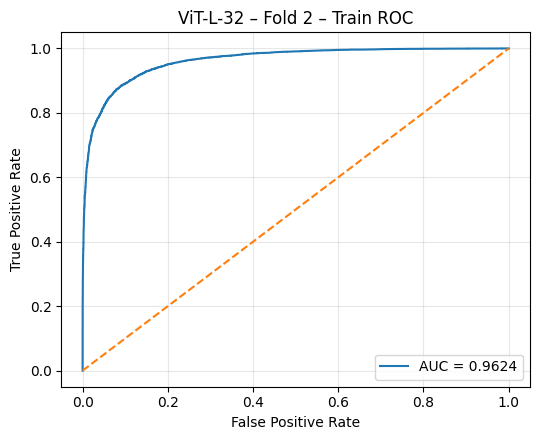

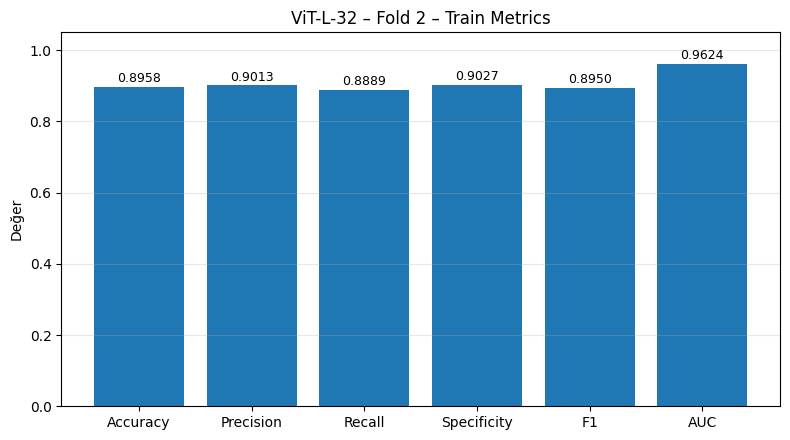

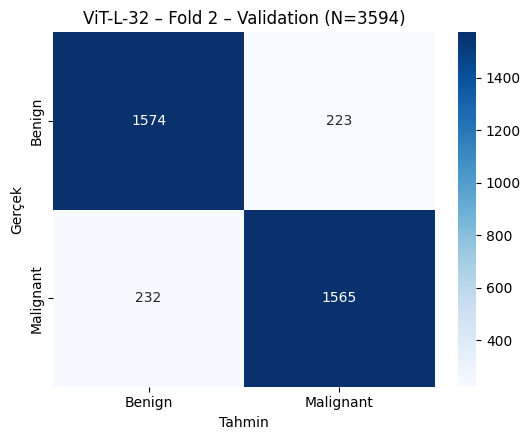

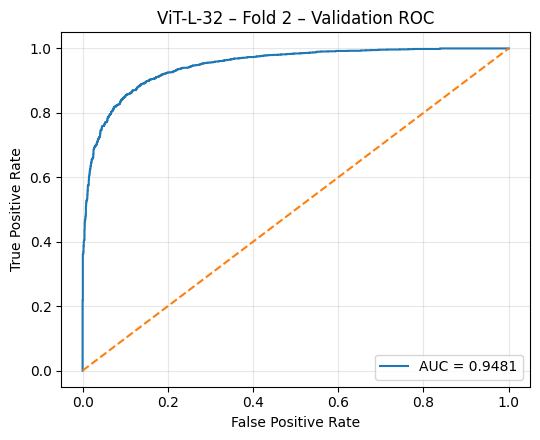

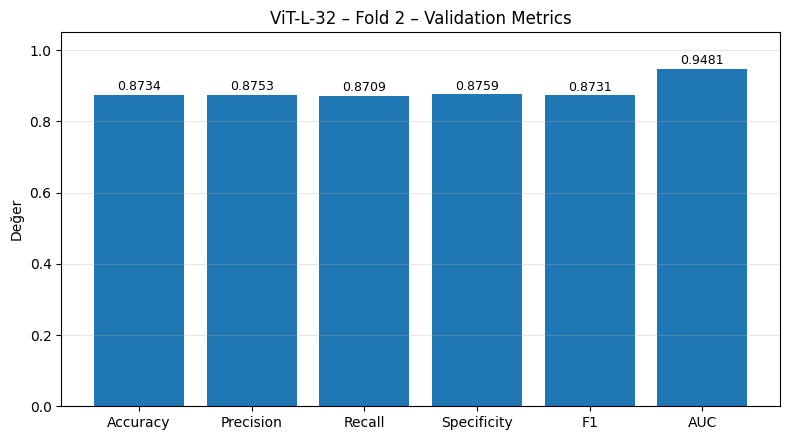

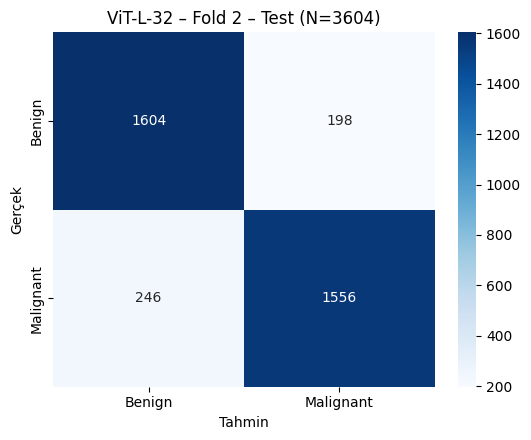

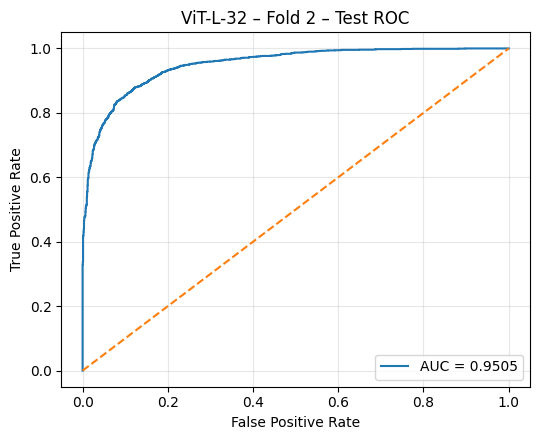

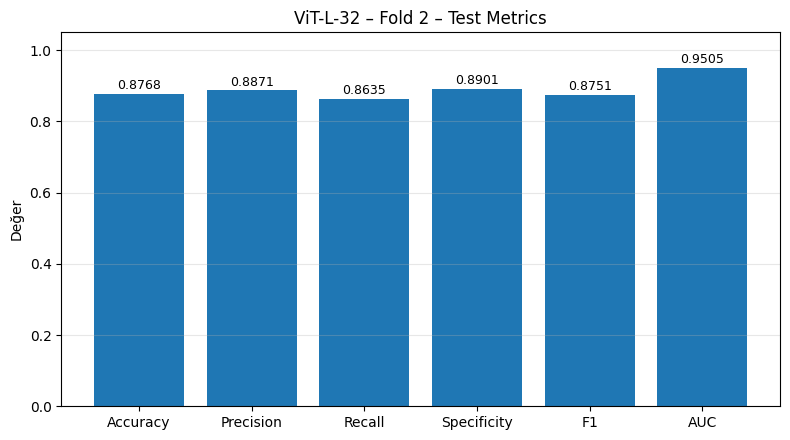

ViT-L-32 – Fold 2 sonuçları (best epoch = 8):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7594.0,819.0,935.0,7478.0,0.895757,0.901290,0.888862,0.902651,0.895033,0.962419,0.260679
Validation,3594.0,1574.0,223.0,232.0,1565.0,0.873400,0.875280,0.870896,0.875904,0.873082,0.948085,0.295378
Test,3604.0,1604.0,198.0,246.0,1556.0,0.876804,0.887115,0.863485,0.890122,0.875141,0.950494,0.288696


✓ ViT-L-32 Fold 2: best epoch 8 | Test acc 0.8768
ViT-L-32 | Fold 3 | Epoch 01/10 | Train loss 0.4868 acc 0.7625 | Val loss 0.4214 acc 0.8061
ViT-L-32 | Fold 3 | Epoch 02/10 | Train loss 0.3859 acc 0.8291 | Val loss 0.3611 acc 0.8472
ViT-L-32 | Fold 3 | Epoch 03/10 | Train loss 0.3477 acc 0.8518 | Val loss 0.3434 acc 0.8467
ViT-L-32 | Fold 3 | Epoch 04/10 | Train loss 0.3264 acc 0.8630 | Val loss 0.3202 acc 0.8617
ViT-L-32 | Fold 3 | Epoch 05/10 | Train loss 0.3111 acc 0.8700 | Val loss 0.3090 acc 0.8614
ViT-L-32 | Fold 3 | Epoch 06/10 | Train loss 0.2973 acc 0.8772 | Val loss 0.3081 acc 0.8651
ViT-L-32 | Fold 3 | Epoch 07/10 | Train loss 0.2881 acc 0.8811 | Val loss 0.2975 acc 0.8698
ViT-L-32 | Fold 3 | Epoch 08/10 | Train loss 0.2793 acc 0.8879 | Val loss 0.2855 acc 0.8787
ViT-L-32 | Fold 3 | Epoch 09/10 | Train loss 0.2711 acc 0.8906 | Val loss 0.2817 acc 0.8804
ViT-L-32 | Fold 3 | Epoch 10/10 | Train loss 0.2681 acc 0.8902 | Val loss 0.2828 acc 0.8745


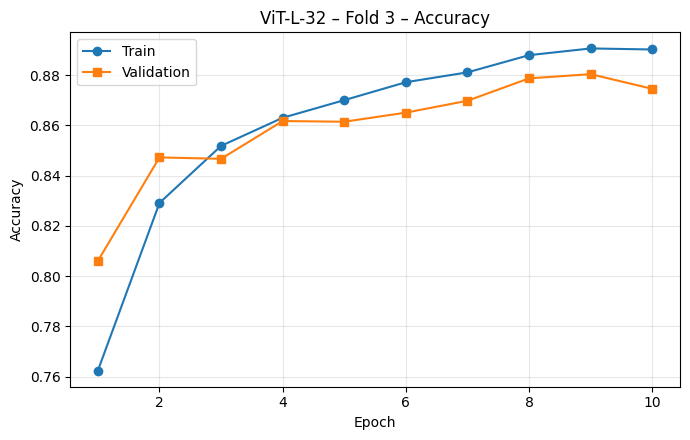

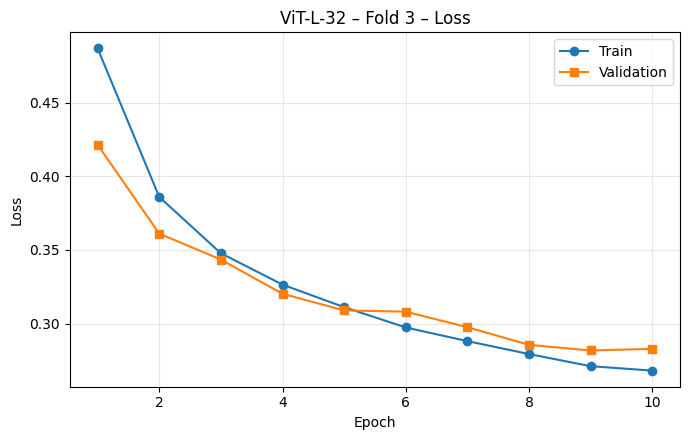

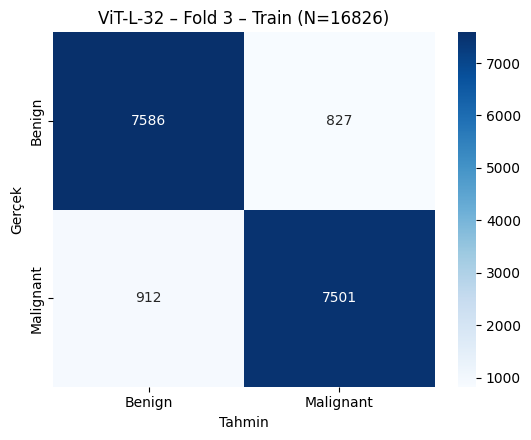

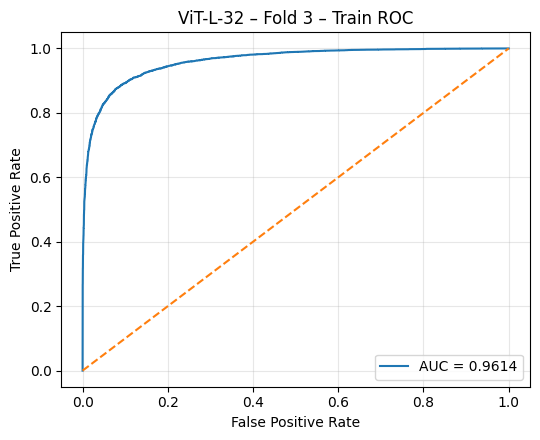

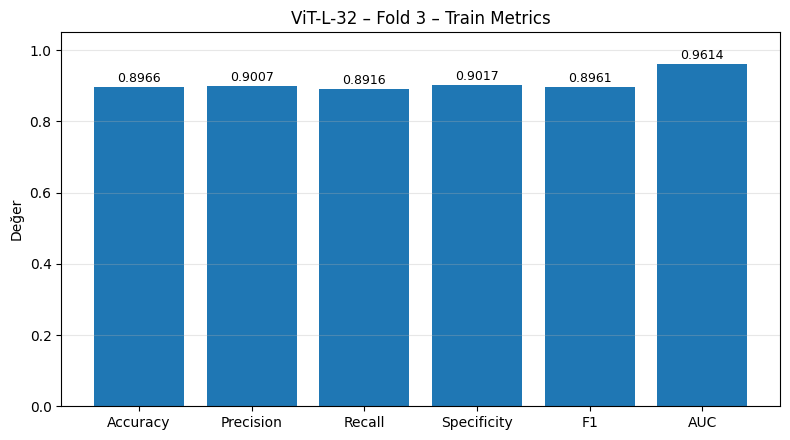

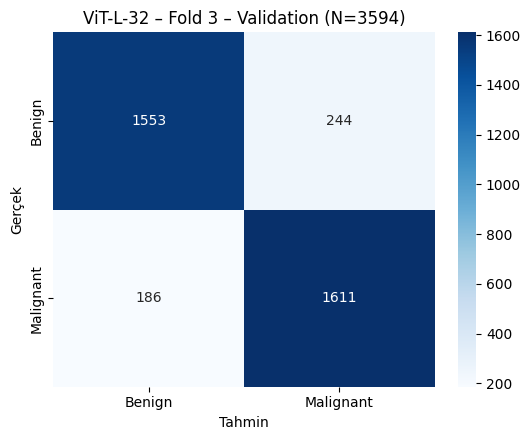

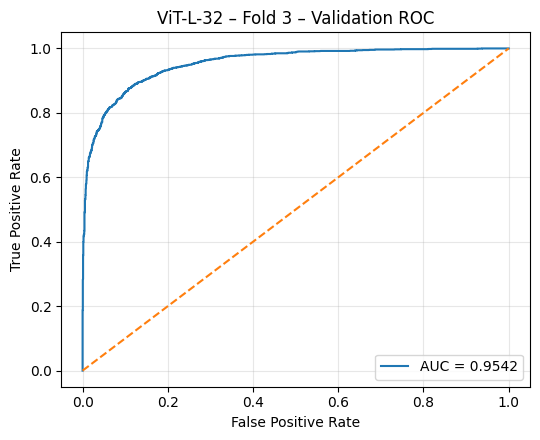

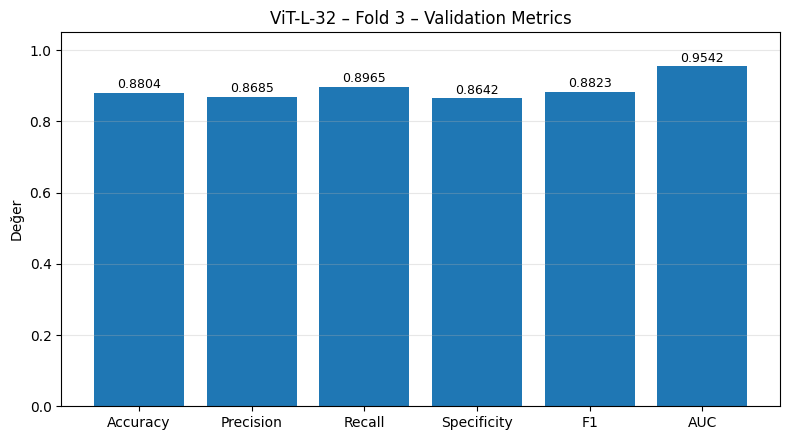

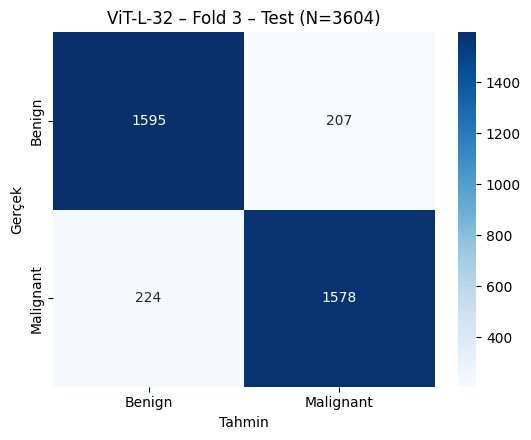

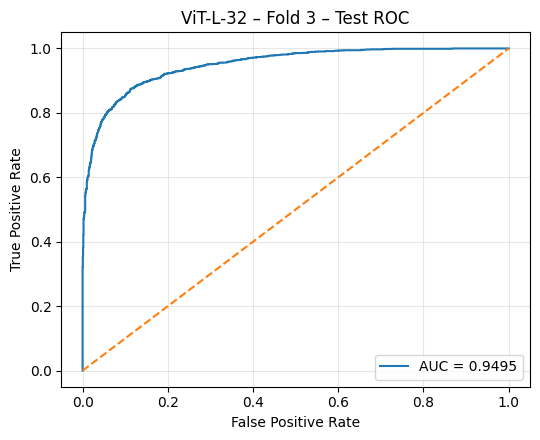

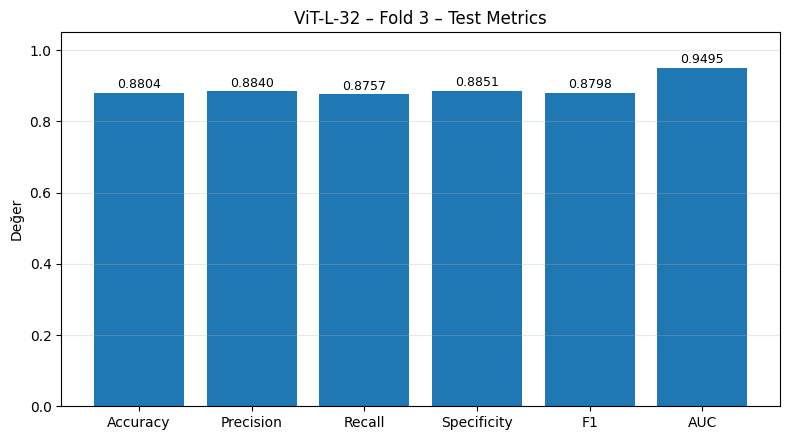

ViT-L-32 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,7586.0,827.0,912.0,7501.0,0.896648,0.900696,0.891596,0.901700,0.896123,0.961365,0.262468
Validation,3594.0,1553.0,244.0,186.0,1611.0,0.880356,0.868464,0.896494,0.864218,0.882256,0.954228,0.281716
Test,3604.0,1595.0,207.0,224.0,1578.0,0.880411,0.884034,0.875694,0.885128,0.879844,0.949529,0.289564


✓ ViT-L-32 Fold 3: best epoch 9 | Test acc 0.8804
ViT-L-32 | Fold 4 | Epoch 01/10 | Train loss 0.4869 acc 0.7644 | Val loss 0.4202 acc 0.8030
ViT-L-32 | Fold 4 | Epoch 02/10 | Train loss 0.3811 acc 0.8346 | Val loss 0.3740 acc 0.8344
ViT-L-32 | Fold 4 | Epoch 03/10 | Train loss 0.3442 acc 0.8536 | Val loss 0.3457 acc 0.8495
ViT-L-32 | Fold 4 | Epoch 04/10 | Train loss 0.3227 acc 0.8640 | Val loss 0.3318 acc 0.8564
ViT-L-32 | Fold 4 | Epoch 05/10 | Train loss 0.3061 acc 0.8743 | Val loss 0.3266 acc 0.8561
ViT-L-32 | Fold 4 | Epoch 06/10 | Train loss 0.2935 acc 0.8787 | Val loss 0.3130 acc 0.8678
ViT-L-32 | Fold 4 | Epoch 07/10 | Train loss 0.2852 acc 0.8812 | Val loss 0.3183 acc 0.8603
ViT-L-32 | Fold 4 | Epoch 08/10 | Train loss 0.2775 acc 0.8839 | Val loss 0.2968 acc 0.8753


In [ ]:
# ======================= 4. ÇALIŞTIR =======================
KIND, FAM = GROUP.split("_")
models_to_run = MODELS or (CNN_MODELS if FAM == "cnn" else VIT_MODELS)
assert all(FAMILY[m] == FAM for m in models_to_run), "Seçilen modeller gruba uymuyor"
if RERUN:   # etiket başına bir kez: MODELS=None ise gruptaki TÜM modeller, değilse sadece MODELS'tekiler
    marker = OUTPUT_ROOT / CV_MODE / GROUP / f"rerun_{RERUN}.done"
    if marker.exists():
        print(f"RERUN '{RERUN}' daha önce uygulanmış → silme YAPILMADI, kaldığı fold'dan devam ediliyor.")
    else:
        for m in models_to_run:
            d = OUTPUT_ROOT / CV_MODE / GROUP / m
            if d.exists():
                shutil.rmtree(d); print(f"Eski sonuçlar silindi, yeniden eğitilecek: {d}")
        marker.parent.mkdir(parents=True, exist_ok=True)
        marker.write_text(f"{time.strftime('%Y-%m-%d %H:%M')} | silinen modeller: {', '.join(models_to_run)}\n")

(OUTPUT_ROOT / CV_MODE / GROUP).mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / CV_MODE / GROUP / "config.json").write_text(json.dumps({
    "GROUP": GROUP, "COMMON": COMMON, "RECIPE": RECIPES[KIND], "FT_SCOPE": FT_SCOPE[(KIND, FAM)],
    "AUGMENT": AUGMENT if RECIPES[KIND]["augment"] else None, "CV_MODE": CV_MODE, "N_FOLDS": N_FOLDS, "FOLD_SEED": FOLD_SEED, "TRAIN_SEED": TRAIN_SEED,
    "fold_counts": fold_table.to_dict("records"), "VIT_LAST_BLOCKS": VIT_LAST_BLOCKS,
    "torch": torch.__version__, "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "kaggle_split_counts": {s: len(d) for s, d in DS.items()}}, indent=2, default=str))

results = []
for name in models_to_run:
    for fold in range(1, N_FOLDS + 1):
        results.append(run_one(name, fold, KIND))

per_run, summary, article = results_to_frames(results)
with pd.ExcelWriter(OUTPUT_ROOT / CV_MODE / GROUP / f"{GROUP}_results.xlsx") as xw:
    per_run.to_excel(xw, sheet_name="Fold bazlı", index=False)
    summary.to_excel(xw, sheet_name="Ortalama-Std", index=False)
    article.to_excel(xw, sheet_name="Makale tablosu", index=False)
display(article[article.Split == "Test"])
